# Estimación de RUL en N-CMAPSS (DS02) — ProjectV06

**Trabajo de título:** *Estimación de la vida útil remanente en sistemas de propulsión
aeronáutica mediante arquitecturas híbridas de aprendizaje profundo*
Matías Godoy Rojas — ROL 201821090-0 — Prof. guía: Mauricio Araya L.

**Notebook consolidado.** Reúne en un solo lugar, y en el orden de la memoria, todo lo
trabajado entre v01 y v05, a pedido de la **Reunión 07**: el estudio queda listo para
redactar la memoria. El detalle de las etapas y decisiones está en `Plan_ProjectV06.md`.

| Etapa | Contenido | Capítulo de la memoria | Estado |
|---|---|---|---|
| 0 | Infraestructura, reutilización verificada de las corridas y exportación para la memoria | — | Completada |
| 1 | Datos, protocolo experimental y arquitecturas | Conjunto de datos y protocolo; Metodología | Completada |
| 2 | Resultados experimentales: ablación, normalización, pérdida, pooling, validación cruzada y prueba | Resultados | Completada |
| 3 | Análisis (sesgo, score, atención, regímenes) y mediciones para la factibilidad | Discusión; Factibilidad | Completada |

**Sin modelos nuevos.** v06 no entrena modelos nuevos ni cambia la configuración final:
A6 (CNN + atención), normalización global y pérdida asimétrica con α = 2. Carga las
corridas guardadas de v02 (A1–A6) y v04 (A6-P1 y A6-P2) después de verificar que este
notebook las reproduce exactamente (sección 0.14).

**Para la memoria.** Cada figura y tabla que va a la memoria se exporta a
`Memoria/Imagenes` y `Memoria/Tablas`, y cada cifra citada en el texto se escribe en
`Memoria/cifras.tex` (sección 0.16). Así el texto no copia números a mano.

**Cómo re-ejecutar.** Cada entrenamiento se guarda en `results/runs/`. Al volver a
ejecutar el notebook, los entrenamientos ya completos se cargan desde disco en vez de
repetirse.

# Etapa 0 — Infraestructura común

## 0.1 Dependencias

Si falta alguna, descomentar y ejecutar una sola vez:

```python
%pip install h5py scikit-learn torch pandas numpy matplotlib
```

In [1]:
# --- Biblioteca estándar ---
import os          # rutas y creación de carpetas
import glob        # búsqueda de archivos por patrón (para encontrar las corridas de v02 y v04)
import shutil      # copia de carpetas (corridas de v02 y v04) y de la caché del dataset
import json        # lectura y escritura de configuraciones y resultados
import math        # raíz cuadrada en escalares
import time        # medición de tiempos de entrenamiento
import random      # semilla del generador aleatorio de Python
import hashlib     # hash de la configuración, para identificar corridas
import warnings    # para silenciar advertencias que no aportan

# --- Bibliotecas científicas ---
import h5py                                  # lectura del archivo HDF5 de N-CMAPSS
import numpy as np                           # arreglos numéricos
import pandas as pd                          # tablas de resultados
import torch                                 # tensores y redes neuronales
import torch.nn as nn                        # capas (Conv1d, LSTM, Linear, ...)
from torch.utils.data import TensorDataset, DataLoader   # entrega de datos por lotes
from sklearn.preprocessing import StandardScaler         # estandarización (media 0, desv. 1)
from sklearn.preprocessing import PolynomialFeatures     # términos cuadráticos de W (etapa 1)
from sklearn.linear_model import LinearRegression        # efecto de W sobre cada sensor (etapa 1)
from sklearn.cluster import KMeans                       # regímenes de la normalización N1a
from sklearn.metrics import silhouette_score             # elección de K en N1a
from scipy.stats import spearmanr                        # correlación de rangos

import matplotlib.pyplot as plt              # figuras
import matplotlib.ticker as mticker          # control de las marcas de los ejes

warnings.filterwarnings("ignore", category=UserWarning)

# Las figuras se muestran dentro del notebook
%matplotlib inline

# Se usa GPU si existe; en el equipo de desarrollo solo hay CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | dispositivo activo: {device}")

PyTorch 2.7.1+cpu | dispositivo activo: cpu


## 0.2 Configuración

Todos los hiperparámetros están aquí. El diccionario `HP` reúne los que afectan al
entrenamiento: con él se calcula un *hash* (una huella corta del contenido) que forma
parte del identificador de cada corrida. Si cambia cualquier valor de `HP`, cambia el
hash, y el notebook reentrena en vez de reutilizar resultados obtenidos con otra
configuración.

`SMOKE_TEST = True` ejecuta todo con datos reducidos y dos épocas, en una carpeta de
corridas separada, solo para comprobar que el código corre de principio a fin.

In [2]:
SMOKE_TEST = False

# --- Rutas (relativas a la carpeta del notebook) ---
DATASET_PATH = "D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5"
OUT_DIR = "results"
RUNS_DIR = os.path.join(OUT_DIR, "runs_smoke" if SMOKE_TEST else "runs")
VERIF_DIR = os.path.join(OUT_DIR, "verificacion_smoke" if SMOKE_TEST else "verificacion")  # sección 0.14
SELECTION_FILE = os.path.join(OUT_DIR, "seleccion.json")
V02_RUNS = "../ProjectV02/results/runs"              # corridas de v02 que se reutilizan (A1-A6)
V04_RUNS = "../ProjectV04/results/runs"              # corridas de v04 que se reutilizan (A6-P1, A6-P2)
V04_CACHE = "../ProjectV04/results"                  # caché del dataset submuestreado de v04
V05_METRICS = "../ProjectV05/results/etapa0_metricas_val.csv"   # métricas de v05, para comprobar coherencia
os.makedirs(RUNS_DIR, exist_ok=True)

# --- Exportación para la memoria (sección 0.16) ---
MEMORIA_DIR = "../../Memoria"                        # carpeta del documento LaTeX
FIG_EXPORT = os.path.join(MEMORIA_DIR, "Imagenes")   # figuras en PDF vectorial
TAB_EXPORT = os.path.join(MEMORIA_DIR, "Tablas")     # tablas como entornos tabular de LaTeX
CIFRAS_FILE = os.path.join(MEMORIA_DIR, "cifras.tex")   # una macro de LaTeX por cifra citada
EXPORT = not SMOKE_TEST                              # la prueba rápida no toca la memoria

# --- Datos ---
SAMPLE_STEP = 10       # se toma 1 de cada 10 registros: los datos vienen a 1 Hz -> 1 dato cada 10 s
WINDOW_SIZE = 30       # pasos por ventana: 30 x 10 s = 300 s = 5 minutos de vuelo
STRIDE = 10            # desplazamiento entre ventanas consecutivas (se solapan 20 de 30 pasos)
USE_PWL = True         # recorte lineal por tramos del RUL (ver sección 0.4)

# --- Partición oficial por motor ---
TRAIN_UNITS = [2.0, 5.0, 10.0, 16.0]   # motores de entrenamiento
VAL_UNITS = [18.0, 20.0]               # motores de validación (eligen época y configuración)
# Los motores de prueba (11, 14, 15) son la partición 'test' del archivo HDF5

# --- Zonas de evaluación, en ciclos de RUL restante ---
FINAL_ZONE = 20.0      # zona final: métrica principal (criterio acordado en la Reunión 03)
ZONES = [("Final", 0.0, 20.0), ("Intermedia", 20.0, 40.0), ("Temprana", 40.0, np.inf)]

# --- Modelos (mismos tamaños que v02) ---
CONV_CHANNELS = 32     # filtros de la primera convolución
HIDDEN_SIZE = 64       # dimensión de las características que llegan a la agregación
DROPOUT = 0.2          # fracción de activaciones que se apagan al azar durante el entrenamiento

# --- Entrenamiento ---
SEEDS = [0, 1, 2, 3, 4]
BATCH_SIZE = 256       # ventanas por lote
MAX_EPOCHS = 30        # máximo de épocas; las curvas se grafican siempre en un eje de 1 a 30
PATIENCE = 5           # early stopping: se detiene tras 5 épocas sin mejorar en validación
LR = 1e-3              # tasa de aprendizaje del optimizador Adam
WEIGHT_DECAY = 1e-4    # regularización L2 sobre los pesos

if SMOKE_TEST:
    SEEDS = [0]
    MAX_EPOCHS = 2
    PATIENCE = 2

# Hiperparámetros que definen una corrida: cualquier cambio aquí invalida la caché.
# Son exactamente los de v02, para poder reutilizar sus corridas.
HP = dict(SAMPLE_STEP=SAMPLE_STEP, WINDOW_SIZE=WINDOW_SIZE, STRIDE=STRIDE, USE_PWL=USE_PWL,
          CONV_CHANNELS=CONV_CHANNELS, HIDDEN_SIZE=HIDDEN_SIZE, DROPOUT=DROPOUT,
          BATCH_SIZE=BATCH_SIZE, MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, LR=LR,
          WEIGHT_DECAY=WEIGHT_DECAY, SMOKE_TEST=SMOKE_TEST)
HP_HASH = hashlib.md5(json.dumps(HP, sort_keys=True).encode()).hexdigest()[:8]
V02_HASH = "405955a4"  # hash de configuración de las corridas de v02
if not SMOKE_TEST:
    # Si este assert falla, la configuración difiere de v02 y sus corridas no son reutilizables
    assert HP_HASH == V02_HASH, f"configuración distinta de v02: {HP_HASH} != {V02_HASH}"

# --- Estilo de figuras (pensado para la memoria) ---
# Ancho del texto de la memoria: hoja carta de 21,59 cm menos los márgenes de 4 y 3 cm de la
# plantilla = 14,59 cm. Las figuras se dibujan a 14,5 cm para que LaTeX no las reescale y
# la letra conserve su tamaño real.
FIG_W = 14.5 / 2.54                                  # ancho de figura en pulgadas
# Un color fijo por arquitectura, el mismo de v02 (atención = azul, último estado = naranjo)
ARCH_COLORS = {"A5": "#2a78d6", "A3": "#eb6834", "A1": "#1baf7a",
               "A2": "#eda100", "A4": "#e87ba4", "A6": "#008300",
               # Variantes de A6 con pooling (v04, etapa 1): colores nuevos, distintos de A1-A6
               "A6P1": "#4a3aa7", "A6P2": "#e34948"}
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"     # tinta principal, secundaria y tenue
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#ffffff"   # grilla, ejes y fondo (blanco: se imprime)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    # Letra tipo Times, como el texto de la memoria (paquete newtx); fórmulas con STIX,
    # que es la versión de Times para matemática
    "font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 10, "legend.fontsize": 9,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "pdf.fonttype": 42,                              # letra incrustada como TrueType en el PDF
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

print(f"Modo: {'SMOKE TEST' if SMOKE_TEST else 'CORRIDA DEFINITIVA'} | "
      f"hash de configuración: {HP_HASH} | corridas en: {RUNS_DIR}")

Modo: CORRIDA DEFINITIVA | hash de configuración: 405955a4 | corridas en: results\runs


## 0.3 Carga desde HDF5

El archivo trae dos particiones oficiales, `dev` (desarrollo) y `test` (prueba). De
cada una se leen:

- `W`: 4 condiciones de vuelo (altitud, Mach, ángulo del acelerador TRA, temperatura de
  entrada T2).
- `X_s`: 14 sensores físicos.
- `Y`: el RUL de cada registro, en ciclos de vuelo.
- `A`: datos auxiliares: unidad (motor), ciclo de vuelo, clase de vuelo `Fc` e
  indicador de salud `hs` (1 = sano, 0 = degradado).

Se descartan los sensores virtuales `X_v` y los parámetros de salud `T`, porque no se
pueden medir en un motor real. Como el archivo pesa 2,4 GB, se lee una de cada 10 filas
directamente desde el disco, y el resultado se guarda en una caché `.npz`.

In [3]:
def _names(f, key):
    """Devuelve los nombres de las variables guardados en el HDF5 (vienen como bytes)."""
    return [v.decode() if isinstance(v, bytes) else str(v) for v in np.array(f[key]).flatten()]


def load_ncmapss(file_path, sample_step=10, cache_dir=OUT_DIR):
    """Carga las particiones 'dev' y 'test' submuestreadas, usando una caché en disco."""
    cache = os.path.join(cache_dir, f"cache_step{sample_step}.npz")
    meta_file = os.path.join(cache_dir, f"cache_step{sample_step}_vars.json")
    keys = ("features", "rul", "unit", "cycle", "fc", "hs")

    # Si la caché existe y tiene todas las variables, se usa y se evita leer el HDF5
    if os.path.exists(cache) and os.path.exists(meta_file):
        z = np.load(cache)
        if all(f"{s}_{k}" in z for s in ("dev", "test") for k in keys):
            print(f"Cargando desde caché: {cache}")
            with open(meta_file, encoding="utf-8") as fh:
                var_names = json.load(fh)
            return {s: {k: z[f"{s}_{k}"] for k in keys} for s in ("dev", "test")}, var_names

    data = {}
    print(f"Leyendo {file_path} (1 de cada {sample_step} registros)...")
    with h5py.File(file_path, "r") as f:
        var_names = {"W": _names(f, "W_var"), "X_s": _names(f, "X_s_var"), "A": _names(f, "A_var")}
        for split in ("dev", "test"):
            # [::sample_step] lee solo las filas necesarias, sin cargar el archivo completo
            W = np.array(f[f"W_{split}"][::sample_step], dtype=np.float32)
            Xs = np.array(f[f"X_s_{split}"][::sample_step], dtype=np.float32)
            Y = np.array(f[f"Y_{split}"][::sample_step], dtype=np.float32).ravel()
            A = np.array(f[f"A_{split}"][::sample_step], dtype=np.float32)
            data[split] = {
                "features": np.hstack([W, Xs]).astype(np.float32),   # 4 + 14 = 18 columnas
                "rul": Y,
                "unit": A[:, 0], "cycle": A[:, 1], "fc": A[:, 2], "hs": A[:, 3],
            }
            print(f"  {split:4s}: {len(Y):>7d} registros")
    np.savez_compressed(cache, **{f"{s}_{k}": v for s, d in data.items() for k, v in d.items()})
    with open(meta_file, "w", encoding="utf-8") as fh:
        json.dump(var_names, fh, ensure_ascii=False, indent=2)
    return data, var_names


# La caché de v04 se obtuvo del mismo archivo con el mismo submuestreo: si v05 aún no tiene
# la suya, se copia en vez de volver a leer el HDF5 (unos minutos). ProjectV04 no se modifica.
for _fname in (f"cache_step{SAMPLE_STEP}.npz", f"cache_step{SAMPLE_STEP}_vars.json"):
    _src, _dst = os.path.join(V04_CACHE, _fname), os.path.join(OUT_DIR, _fname)
    if os.path.exists(_src) and not os.path.exists(_dst):
        shutil.copy2(_src, _dst)

data, var_names = load_ncmapss(DATASET_PATH, SAMPLE_STEP)
dev, test = data["dev"], data["test"]
FEATURE_NAMES = var_names["W"] + var_names["X_s"]   # orden de las 18 columnas de entrada
NUM_FEATURES = len(FEATURE_NAMES)
print(f"Canales de entrada ({NUM_FEATURES}): {FEATURE_NAMES}")

Cargando desde caché: results\cache_step10.npz


Canales de entrada (18): ['alt', 'Mach', 'TRA', 'T2', 'T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']


## 0.4 Umbral PwL y zonas de evaluación

**Recorte lineal por tramos (PwL).** Mientras el motor está sano, los sensores no
indican cuánto falta para la falla, así que no tiene sentido pedirle al modelo que
distinga 80 de 70 ciclos restantes. El RUL se recorta a un máximo: la mediana del RUL
en el momento en que los motores de entrenamiento pasan de sanos a degradados, según el
indicador `hs` del propio dataset.

In [4]:
# RUL en el instante de transición sano -> degradado de cada motor de entrenamiento:
# es el mayor RUL entre los registros ya degradados (hs == 0) de ese motor
transitions = [float(dev["rul"][(dev["unit"] == u) & (dev["hs"] == 0)].max()) for u in TRAIN_UNITS]
RUL_MAX = float(np.round(np.median(transitions)))
print(f"RUL en la transición sano -> degradado (entrenamiento): {transitions}")
print(f"Umbral PwL: {RUL_MAX:.0f} ciclos")

# Etiquetas recortadas: todo RUL mayor que el umbral se reemplaza por el umbral
rul_dev = np.clip(dev["rul"], 0.0, RUL_MAX) if USE_PWL else dev["rul"].copy()
rul_test = np.clip(test["rul"], 0.0, RUL_MAX) if USE_PWL else test["rul"].copy()

print("\nFracción de registros por zona de evaluación:")
for name, lo, hi in ZONES:
    # La primera zona incluye RUL = 0; las demás excluyen su borde inferior
    fd = np.mean((rul_dev > lo) & (rul_dev <= hi)) if lo > 0 else np.mean(rul_dev <= hi)
    print(f"   {name:<11} ({lo:>4.0f}, {hi:>4.0f}]  dev {100 * fd:5.1f} %")

RUL en la transición sano -> degradado (entrenamiento): [58.0, 72.0, 65.0, 47.0]
Umbral PwL: 62 ciclos

Fracción de registros por zona de evaluación:
   Final       (   0,   20]  dev  27.7 %
   Intermedia  (  20,   40]  dev  27.2 %
   Temprana    (  40,  inf]  dev  45.1 %


## 0.5 Particiones por motor

Ningún motor aparece en dos conjuntos: en operación, el modelo se enfrenta a motores
que nunca vio. Una partición se describe con sus motores de entrenamiento, validación y
evaluación. La partición `oficial` evalúa sobre el conjunto de prueba del HDF5. v05 solo
usa esta partición, y de ella solo la validación.

In [5]:
SPLITS = {"oficial": {"name": "oficial", "train": TRAIN_UNITS, "val": VAL_UNITS, "eval": "test"}}

# Comprobaciones de que no hay motores compartidos entre conjuntos
assert not np.any(np.isin(TRAIN_UNITS, VAL_UNITS))
assert len(np.intersect1d(np.unique(dev["unit"]), np.unique(test["unit"]))) == 0

_n_tr = np.isin(dev["unit"], TRAIN_UNITS).sum()
_n_va = np.isin(dev["unit"], VAL_UNITS).sum()
_n_te = len(test["unit"])
_n = _n_tr + _n_va + _n_te
print("Partición oficial (registros submuestreados):")
print(f"   Entrenamiento  motores  2, 5, 10, 16 : {_n_tr:>7,d}  ({100 * _n_tr / _n:4.1f} %)")
print(f"   Validación     motores 18, 20        : {_n_va:>7,d}  ({100 * _n_va / _n:4.1f} %)")
print(f"   Prueba         motores 11, 14, 15    : {_n_te:>7,d}  ({100 * _n_te / _n:4.1f} %)")

Partición oficial (registros submuestreados):
   Entrenamiento  motores  2, 5, 10, 16 : 360,457  (55.3 %)
   Validación     motores 18, 20        : 165,888  (25.5 %)
   Prueba         motores 11, 14, 15    : 125,375  (19.2 %)


## 0.6 Normalización global sin fuga de información

Cada uno de los 18 canales se estandariza (se le resta su media y se divide por su
desviación estándar). Las medias y desviaciones se calculan **solo con los motores de
entrenamiento**; validación y prueba se transforman con esos mismos valores. Si se
calcularan con todos los datos, información de los motores de evaluación se filtraría
al entrenamiento.

La normalización global quedó fija desde v03.

In [6]:
def _fit_global(d, train_mask):
    """Ajusta la estandarización con los registros de entrenamiento y devuelve la transformación."""
    scaler = StandardScaler().fit(d["features"][train_mask])
    return lambda dd: scaler.transform(dd["features"]).astype(np.float32)


NORMALIZERS = {"global": _fit_global}   # nombre -> función que ajusta y devuelve la transformación
NORM_TAGS = {"global": "global"}        # etiqueta de cada normalización en el identificador de corrida


def fit_normalizer(method, d, train_mask):
    """Devuelve la transformación del método pedido, ajustada solo con `train_mask`."""
    return NORMALIZERS[method](d, train_mask)

### Normalizaciones por condición de operación (v02, etapa 2)

En v02 se compararon dos alternativas a la normalización global. Se incluyen aquí para
poder cargar sus corridas en la etapa 2; el código es el de v02, ahora comentado.

- **N1a, por régimen:** se agrupan las condiciones de vuelo W en K regímenes con k-means
  (K de 2 a 6, el de mayor silueta) y cada sensor se estandariza con la media y la
  desviación de su régimen.
- **N1b, por motor:** cada sensor se estandariza con la media y la desviación de los
  primeros 10 ciclos del propio motor, que son sanos (línea base).

En ambas, las 4 variables de W se estandarizan con la escala global. Las dos se ajustan
solo con los motores de entrenamiento de cada partición, como la global. La etapa 2 de v02
concluyó que la normalización global se mantiene.

In [7]:
N_W = len(var_names["W"])          # las primeras 4 columnas son W; las 14 siguientes, sensores X_s
REGIME_K_RANGE = range(2, 7)       # candidatos para el número de regímenes de N1a (v02)
BASELINE_CYCLES = 10               # ciclos iniciales que definen la línea base de N1b (v02)
NORM_INFO = {}                     # diagnóstico del último ajuste de cada método

# Etiquetas de las corridas de v02: "regimen2-6" y "motor10"
NORM_TAGS["regimen"] = f"regimen{REGIME_K_RANGE.start}-{REGIME_K_RANGE.stop - 1}"
NORM_TAGS["motor"] = f"motor{BASELINE_CYCLES}"
NORM_LABELS = {"global": "Global", "regimen": "N1a, por régimen", "motor": "N1b, por motor"}


def _fit_regimen(d, train_mask):
    """N1a: estandariza cada sensor dentro de su régimen de operación (k-means sobre W)."""
    F_tr = d["features"][train_mask]
    channel_scaler = StandardScaler().fit(F_tr)              # escala global, usada para W
    w_scaler = StandardScaler().fit(F_tr[:, :N_W])           # W estandarizado para k-means
    Wz = w_scaler.transform(F_tr[:, :N_W])

    # Elección de K por silueta, sobre una submuestra de 20.000 registros (como en v02)
    sub = np.random.default_rng(0).choice(len(Wz), size=min(20000, len(Wz)), replace=False)
    scores = {}
    for k in REGIME_K_RANGE:
        labels_k = KMeans(k, n_init=10, random_state=0).fit_predict(Wz[sub])
        scores[k] = float(silhouette_score(Wz[sub], labels_k, sample_size=5000, random_state=0))
    k_best = max(scores, key=scores.get)
    km = KMeans(k_best, n_init=10, random_state=0).fit(Wz)   # regímenes con todos los registros

    # Media y desviación de cada sensor dentro de cada régimen: (K, 14)
    S_tr = F_tr[:, N_W:]
    mu = np.stack([S_tr[km.labels_ == c].mean(axis=0) for c in range(k_best)])
    sd = np.stack([S_tr[km.labels_ == c].std(axis=0) for c in range(k_best)]) + 1e-6
    NORM_INFO["regimen"] = {"k": k_best, "silueta": scores,
                            "proporcion": np.bincount(km.labels_, minlength=k_best) / len(km.labels_)}

    def transform(dd):
        F = dd["features"]
        out = channel_scaler.transform(F).astype(np.float32)   # W queda con la escala global
        lab = km.predict(w_scaler.transform(F[:, :N_W]))        # régimen de cada registro
        out[:, N_W:] = (F[:, N_W:] - mu[lab]) / sd[lab]         # sensores, con la escala de su régimen
        return out.astype(np.float32)
    return transform


def _fit_motor(d, train_mask):
    """N1b: estandariza cada sensor con la línea base (primeros 10 ciclos) del propio motor."""
    channel_scaler = StandardScaler().fit(d["features"][train_mask])   # escala global, para W

    def transform(dd):
        F = dd["features"]
        out = channel_scaler.transform(F).astype(np.float32)
        for u in np.unique(dd["unit"]):
            m = dd["unit"] == u
            base = m & (dd["cycle"] <= BASELINE_CYCLES)        # primeros ciclos de este motor
            mu, sd = F[base, N_W:].mean(axis=0), F[base, N_W:].std(axis=0) + 1e-6
            out[m, N_W:] = (F[m, N_W:] - mu) / sd
        return out.astype(np.float32)
    return transform


NORMALIZERS["regimen"] = _fit_regimen
NORMALIZERS["motor"] = _fit_motor

# N1b solo es válida si los primeros ciclos de cada motor son sanos (hs = 1)
for _name, _d in (("dev", dev), ("test", test)):
    for _u in np.unique(_d["unit"]):
        _m = (_d["unit"] == _u) & (_d["cycle"] <= BASELINE_CYCLES)
        assert np.all(_d["hs"][_m] == 1), f"motor {_u}: hay ciclos degradados en la línea base"
print(f"OK: los primeros {BASELINE_CYCLES} ciclos de los 9 motores son sanos (hs = 1).")

OK: los primeros 10 ciclos de los 9 motores son sanos (hs = 1).


## 0.7 Ventaneo y construcción de tensores

El modelo no recibe registros sueltos sino **ventanas**: 30 registros consecutivos de un
mismo vuelo, es decir, 5 minutos. La etiqueta de cada ventana es el RUL de su último
registro. Las ventanas nunca cruzan de un vuelo al siguiente, porque mezclarían el
aterrizaje de uno con el despegue del otro.

Las posiciones de las ventanas no dependen de la normalización, así que se calculan una
sola vez. `build_tensors` aplica la normalización y arma tres conjuntos, cada uno con:

- `X`: forma `(N, 30, 18)` — N ventanas, 30 pasos de tiempo, 18 canales.
- `y`: forma `(N,)` — el RUL de cada ventana.
- `meta`: forma `(N, 2)` — motor y ciclo de vuelo de cada ventana.

In [8]:
def _window_starts(d):
    """Calcula dónde empieza cada ventana válida, sin cruzar fronteras de (motor, ciclo)."""
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    # Hay un cambio de vuelo donde el par (motor, ciclo) difiere del registro anterior
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    bounds = np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])
    # Dentro de cada vuelo [s, e) caben (e - s - 30) // 10 + 1 ventanas
    starts = [s + np.arange((e - s - WINDOW_SIZE) // STRIDE + 1) * STRIDE
              for s, e in zip(bounds[:-1], bounds[1:]) if e - s >= WINDOW_SIZE]
    starts = np.concatenate(starts)
    last = starts + WINDOW_SIZE - 1                 # índice del último registro de cada ventana
    return starts, d["unit"][last], d["cycle"][last]


WINDOWS = {"dev": _window_starts(dev), "test": _window_starts(test)}
_RUL = {"dev": rul_dev, "test": rul_test}


def _gather(feats, source, units=None):
    """Arma (X, y, meta) con las ventanas de `source` que pertenecen a los motores `units`."""
    starts, w_unit, w_cycle = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    st = starts[m]
    # Matriz de índices (N, 30): fila i = posiciones de los 30 registros de la ventana i
    idx = st[:, None] + np.arange(WINDOW_SIZE)[None, :]
    X = feats[idx].astype(np.float32)               # (N, 30, 18)
    y = _RUL[source][st + WINDOW_SIZE - 1].astype(np.float32)
    meta = np.stack([w_unit[m], w_cycle[m]], axis=1)
    return X, y, meta


_TENSORS = {}   # memoria: (normalización, partición) -> tensores ya construidos


def build_tensors(norm, split_name):
    """Devuelve {'train', 'val', 'eval'} -> (X, y, meta) para una normalización y partición."""
    key = (norm, split_name)
    if key in _TENSORS:
        return _TENSORS[key]
    sp = SPLITS[split_name]
    # La normalización se ajusta solo con los motores de entrenamiento de esta partición
    transform = fit_normalizer(norm, dev, np.isin(dev["unit"], sp["train"]))
    dev_n = transform(dev)
    out = {"train": _gather(dev_n, "dev", sp["train"]), "val": _gather(dev_n, "dev", sp["val"])}
    # Evaluación: el conjunto de prueba oficial, o un motor de dev en la validación cruzada
    out["eval"] = (_gather(transform(test), "test") if sp["eval"] == "test"
                   else _gather(dev_n, "dev", sp["eval"]))
    if SMOKE_TEST:
        # Submuestra para que la prueba rápida tome segundos
        rng = np.random.default_rng(0)
        for part, n in (("train", 4000), ("val", 2000)):
            X, y, meta = out[part]
            sel = rng.choice(len(X), size=min(n, len(X)), replace=False)
            out[part] = (X[sel], y[sel], meta[sel])
    # Comprobación: ningún motor de entrenamiento aparece en validación ni en evaluación
    for a, b in (("train", "val"), ("train", "eval")):
        assert not np.intersect1d(np.unique(out[a][2][:, 0]), np.unique(out[b][2][:, 0])).size
    _TENSORS[key] = out
    return out


_T = build_tensors("global", "oficial")
for part in ("train", "val", "eval"):
    X, y, _ = _T[part]
    print(f"{part:<6}: X = {str(X.shape):>18s} | RUL medio = {y.mean():5.1f}")
print("OK: sin motores compartidos entre entrenamiento, validación y evaluación.")

train : X =    (35287, 30, 18) | RUL medio =  37.1
val   : X =    (16251, 30, 18) | RUL medio =  33.3
eval  : X =    (12047, 30, 18) | RUL medio =  31.0
OK: sin motores compartidos entre entrenamiento, validación y evaluación.


## 0.8 Catálogo de arquitecturas

Son las seis arquitecturas de v02 y v03, más las dos variantes de A6 con *pooling* de
v04. El catálogo es exactamente el de v04: se necesita completo para reconstruir y
verificar las corridas que se reutilizan. Todas reciben ventanas de forma `(B, 30, 18)`, donde **B** es el
número de ventanas del lote, **30** los pasos de tiempo y **18** los canales. Todas
terminan en el mismo cabezal de regresión.

| Id | Arquitectura | Extractor | Agregación temporal | Inspirada en |
|---|---|---|---|---|
| A1 | 1D-CNN | Conv 18→32 canales, Conv 32→64 canales | promedio | Sateesh Babu et al. (2016); Li, Ding y Sun (2018) |
| A2 | LSTM | LSTM 18→64 | último estado | Zheng et al. (2017); Wu et al. (2018) |
| A3 | CNN + LSTM | Conv 18→32 canales, LSTM 32→64 | último estado | — |
| A4 | LSTM + atención | LSTM 18→64 | atención | de Oliveira da Costa et al. (2019) |
| A5 | CNN + LSTM + atención | Conv 18→32 canales, LSTM 32→64 | atención | Li et al. (2022) |
| A6 | CNN + atención | Conv 18→32 canales, Conv 32→64 canales | atención | — |
| A6-P1 | A6 con pooling tras la 1.ª convolución | Conv 18→32, MaxPool, Conv 32→64 | atención | — |
| A6-P2 | A6 con pooling tras cada convolución | Conv 18→32, MaxPool, Conv 32→64, MaxPool | atención | — |

**Pooling (nuevo en v04).** `MaxPool1d(2)` recorre el eje temporal en tramos de 2 pasos
sin solaparse y deja, para cada canal, el mayor de los dos valores. La longitud temporal
se reduce a la mitad, redondeando hacia abajo: 30 → 15 y 15 → 7 (el paso 15 queda fuera
del segundo pooling, porque no completa un tramo de 2). Los canales no cambian. El
pooling no tiene parámetros que entrenar, así que A6, A6-P1 y A6-P2 tienen exactamente el
mismo número de parámetros; lo único que cambia es cuántos pasos llegan a la atención:

| Id | Forma antes de la atención |
|---|---|
| A6 | (B, 30, 64) |
| A6-P1 | (B, 15, 64) |
| A6-P2 | (B, 7, 64) |

**Orden de las capas en el bloque convolucional** (método `temporal_features`):
convolución → BatchNorm → ReLU → MaxPool (solo A6-P1 y A6-P2) → Dropout. El dropout va
después del pooling. Cada arquitectura tiene un único dropout: tras la primera
convolución en las que tienen CNN, y tras la LSTM en A2 y A4. La etapa 3 explica de dónde
viene este diseño.

En el código, los identificadores son `A6P1` y `A6P2` (sin guion), porque forman parte
del nombre de la carpeta de cada corrida.

**Sobre "32 → 64" en A1 y A6.** Son canales (filtros), no tiempo. Con `kernel_size=3`,
`padding=1` y paso 1, la longitud de salida de una convolución es
$(30 + 2 \cdot 1 - 3)/1 + 1 = 30$: la dimensión temporal se mantiene en 30 en toda la
red. Solo cambia cuántas características se calculan en cada paso.

**Agregación temporal.** Las capas anteriores producen 64 características en cada uno de
los T pasos (T = 30 sin pooling), forma `(B, T, 64)`. La agregación las resume en un solo
vector de 64 por ventana, forma `(B, 64)`:

- **Último estado:** se toma el último paso y se descartan los demás.
- **Promedio temporal:** se promedian los T pasos, todos con el mismo peso (1/T).
- **Atención:** se promedian los T pasos con pesos aprendidos (clase `TemporalAttention`
  y guía de estudio de v03).

**Limitación conocida.** Los pares A1–A6, A2–A4 y A3–A5 difieren solo en la agregación.
Entre extractores la comparación no es estricta: A1 y A6 tienen una convolución más que
A3 y A5, y la agregación sin atención es el promedio en A1 y el último estado en A2 y A3.

In [9]:
class TemporalAttention(nn.Module):
    """
    Atención aditiva (Bahdanau et al., 2015) sobre la dimensión temporal.

    Para cada paso t calcula un puntaje e_t = v · tanh(W h_t + b), convierte los T
    puntajes en pesos que suman 1 con softmax y devuelve el promedio ponderado de los h_t.
    Funciona con cualquier número de pasos T: 30 sin pooling, 15 en A6-P1 y 7 en A6-P2.
    """

    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)       # W y b: proyección de cada paso
        self.v = nn.Linear(hidden_dim, 1, bias=False)       # v: reduce cada paso a un puntaje

    def forward(self, h):                                   # h: (B, T, H), p. ej. (B, 30, 64)
        scores = self.v(torch.tanh(self.attn(h)))           # (B, T, 1): un puntaje por paso
        weights = torch.softmax(scores, dim=1)              # (B, T, 1): pesos que suman 1 en t
        context = torch.sum(weights * h, dim=1)             # (B, 64): promedio ponderado
        return context, weights.squeeze(-1)                 # pesos (B, T) para interpretarlos


class RULNet(nn.Module):
    """
    Construye todas las arquitecturas del catálogo a partir de cuatro opciones:
    use_cnn (hay convolución), use_lstm (hay LSTM), aggregation ('last', 'mean',
    'attention') y pool ('none', 'first', 'each'):
      - 'none':  sin pooling (A1-A6, igual que en v02 y v03).
      - 'first': MaxPool1d(2) solo tras la primera convolución (A6-P1).
      - 'each':  MaxPool1d(2) tras cada convolución (A6-P2).
    """

    def __init__(self, num_features, use_cnn, use_lstm, aggregation, pool="none",
                 conv_channels=CONV_CHANNELS, hidden=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        assert use_cnn or use_lstm
        assert aggregation in ("last", "mean", "attention")
        assert pool in ("none", "first", "each")
        # El pooling actúa sobre la salida de las convoluciones: requiere CNN, y 'each'
        # requiere además la segunda convolución, que solo existe sin LSTM (A1, A6)
        assert pool == "none" or use_cnn
        assert pool != "each" or not use_lstm
        self.use_cnn, self.use_lstm, self.aggregation = use_cnn, use_lstm, aggregation
        self.pool = pool

        # IMPORTANTE: el orden en que se crean las capas determina cómo se consumen los
        # números aleatorios al inicializarlas. Se mantiene el mismo orden que en v01 y
        # v02 para que, con la misma semilla, A3 y A5 partan de pesos idénticos.
        if use_cnn:
            # Primera convolución: 18 canales de entrada -> 32 filtros, ventana de 3 pasos
            self.conv = nn.Conv1d(num_features, conv_channels, kernel_size=3, padding=1)
            self.bn = nn.BatchNorm1d(conv_channels)          # normaliza cada filtro en el lote
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        if use_cnn and not use_lstm:
            # CNN sin LSTM (A1, A6): segunda convolución, 32 -> 64 canales, para llegar a
            # la dimensión 64 que esperan la atención y el cabezal
            self.conv2 = nn.Conv1d(conv_channels, hidden, kernel_size=3, padding=1)
            self.bn2 = nn.BatchNorm1d(hidden)
        if use_lstm:
            # LSTM con 64 unidades; su entrada es 32 si viene de la CNN o 18 si va sola
            self.lstm = nn.LSTM(conv_channels if use_cnn else num_features, hidden,
                                batch_first=True)
        self.attention = TemporalAttention(hidden) if aggregation == "attention" else None
        # Cabezal de regresión: 64 -> 32 -> 1 (el RUL estimado)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
        # Pooling (nuevo en v04). Se crea al final y no tiene parámetros: no consume números
        # aleatorios, así que no altera la inicialización de las capas anteriores. Con
        # pool='none' la red es idéntica a la de v02 y v03 (lo verifica la sección 0.14).
        # kernel_size=2 y paso 2 (el paso por defecto es igual al tamaño de la ventana)
        self.maxpool = nn.MaxPool1d(kernel_size=2) if pool != "none" else None

    def temporal_features(self, x):
        """Características por paso de tiempo, antes de la agregación: (B, T, 64)."""
        h = x                                               # x: (B, 30, 18)
        if self.use_cnn:
            # Conv1d espera (B, canales, tiempo): se intercambian las dos últimas dimensiones
            z = self.relu(self.bn(self.conv(x.permute(0, 2, 1))))   # (B, 32, 30)
            if self.pool in ("first", "each"):
                z = self.maxpool(z)                         # (B, 32, 15): mitad de los pasos
            z = self.dropout(z)
            if not self.use_lstm:
                z = self.relu(self.bn2(self.conv2(z)))      # (B, 64, T): T = 30 o 15
                if self.pool == "each":
                    z = self.maxpool(z)                     # (B, 64, 7): 15 // 2 = 7 pasos
            h = z.permute(0, 2, 1)                          # de vuelta a (B, T, canales)
        if self.use_lstm:
            h, _ = self.lstm(h)                             # (B, 30, 64): una salida por paso
            if not self.use_cnn:
                h = self.dropout(h)                         # en A2 y A4 el dropout va aquí
        return h

    def forward(self, x):                                   # x: (B, 30, 18)
        h = self.temporal_features(x)                       # (B, T, 64)
        weights = None                                      # solo la atención produce pesos
        if self.aggregation == "attention":
            feat, weights = self.attention(h)               # promedio con pesos aprendidos
        elif self.aggregation == "mean":
            feat = h.mean(dim=1)                            # promedio temporal: peso 1/T a cada paso
        else:
            feat = h[:, -1, :]                              # último estado: solo el último paso
        return self.head(feat), weights                     # RUL (B, 1) y pesos (B, T) o None


# Catálogo: cada arquitectura queda definida por las tres opciones de RULNet
ARCHS = {
    "A1": dict(name="1D-CNN", use_cnn=True, use_lstm=False, aggregation="mean",
               ref="Sateesh Babu et al. (2016); Li, Ding y Sun (2018)"),
    "A2": dict(name="LSTM", use_cnn=False, use_lstm=True, aggregation="last",
               ref="Zheng et al. (2017); Wu et al. (2018)"),
    "A3": dict(name="CNN + LSTM", use_cnn=True, use_lstm=True, aggregation="last",
               ref="— (referencia por definir)"),
    "A4": dict(name="LSTM + atención", use_cnn=False, use_lstm=True, aggregation="attention",
               ref="de Oliveira da Costa et al. (2019)"),
    "A5": dict(name="CNN + LSTM + atención", use_cnn=True, use_lstm=True, aggregation="attention",
               ref="Li et al. (2022)"),
    "A6": dict(name="CNN + atención", use_cnn=True, use_lstm=False, aggregation="attention",
               ref="—"),
    # Variantes con pooling (v04, etapa 1): misma A6, solo cambia la opción pool
    "A6P1": dict(name="CNN + atención, pooling tras la 1.ª conv.", use_cnn=True, use_lstm=False,
                 aggregation="attention", pool="first", ref="—"),
    "A6P2": dict(name="CNN + atención, pooling tras cada conv.", use_cnn=True, use_lstm=False,
                 aggregation="attention", pool="each", ref="—"),
}
# Etiquetas para tablas y figuras; los identificadores A6P1 y A6P2 se muestran con guion
ARCH_IDS = {k: k.replace("A6P", "A6-P") for k in ARCHS}
ARCH_LABELS = {k: f"{ARCH_IDS[k]} · {a['name']}" for k, a in ARCHS.items()}


def make_model(arch):
    """Crea una red nueva (pesos aleatorios) de la arquitectura indicada."""
    a = ARCHS[arch]
    # Las arquitecturas sin la clave 'pool' (A1-A6) se crean sin pooling
    return RULNet(NUM_FEATURES, a["use_cnn"], a["use_lstm"], a["aggregation"],
                  pool=a.get("pool", "none"))


def count_params(model):
    """Número de parámetros que el entrenamiento ajusta."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Comprobación: cada arquitectura procesa un lote de prueba y entrega la forma esperada.
# La columna "Antes de la agregación" muestra la forma del tensor que llega a la atención,
# al promedio o al último estado: con pooling, el número de pasos baja de 30 a 15 o a 7.
_x = torch.randn(4, WINDOW_SIZE, NUM_FEATURES)
rows = []
for k, a in ARCHS.items():
    m = make_model(k).eval()
    out, w = m(_x)
    h = m.temporal_features(_x)
    assert out.shape == (4, 1) and (w is None) == (a["aggregation"] != "attention")
    if w is not None:
        assert w.shape == h.shape[:2]                   # un peso de atención por paso
    rows.append({"Id": ARCH_IDS[k], "Arquitectura": a["name"], "Agregación": a["aggregation"],
                 "Antes de la agregación": "(B, {}, {})".format(*h.shape[1:]),
                 "Parámetros": f"{count_params(m):,}".replace(",", "."), "Inspirada en": a["ref"]})
arch_table = pd.DataFrame(rows)
print(arch_table.to_string(index=False))

# El pooling no tiene parámetros: las tres variantes de A6 deben tener el mismo tamaño
assert count_params(make_model("A6")) == count_params(make_model("A6P1")) == count_params(make_model("A6P2"))
# Con pool='none', la red de cada semilla debe partir de los mismos pesos que en v02 y
# v03. Se comprueba aquí con A6: crear la red con y sin el argumento pool da pesos iguales.
torch.manual_seed(0)
_w_new = make_model("A6").state_dict()
torch.manual_seed(0)
_a = ARCHS["A6"]
_w_old = RULNet(NUM_FEATURES, _a["use_cnn"], _a["use_lstm"], _a["aggregation"]).state_dict()
assert all(torch.equal(_w_new[k], _w_old[k]) for k in _w_old)
# Las variantes con pooling también parten de los mismos pesos que A6 con la misma semilla
torch.manual_seed(0)
_w_p2 = make_model("A6P2").state_dict()
assert all(torch.equal(_w_new[k], _w_p2[k]) for k in _w_new)
print("\nOK: A6, A6-P1 y A6-P2 tienen los mismos parámetros y, con la misma semilla, "
      "los mismos pesos iniciales.")

   Id                              Arquitectura Agregación Antes de la agregación Parámetros                                      Inspirada en
   A1                                    1D-CNN       mean            (B, 30, 64)     10.273 Sateesh Babu et al. (2016); Li, Ding y Sun (2018)
   A2                                      LSTM       last            (B, 30, 64)     23.617             Zheng et al. (2017); Wu et al. (2018)
   A3                                CNN + LSTM       last            (B, 30, 64)     29.025                        — (referencia por definir)
   A4                           LSTM + atención  attention            (B, 30, 64)     27.841                de Oliveira da Costa et al. (2019)
   A5                     CNN + LSTM + atención  attention            (B, 30, 64)     33.249                                  Li et al. (2022)
   A6                            CNN + atención  attention            (B, 30, 64)     14.497                                                 —

## 0.9 Función de pérdida

$\mathcal{L}_\alpha = \frac{1}{N}\sum_i w(d_i)\,d_i^2$, con $d = \hat{y} - y$ y
$w = \alpha$ si $d > 0$ (sobreestimación) o $w = 1$ si no. Con $\alpha = 1$ es
exactamente el error cuadrático medio (MSE). La configuración final usa $\alpha = 2$
(elegido en la etapa 2 de v03).

Es la pérdida de la **regresión por expectiles** (Newey y Powell, 1987): el modelo que la
minimiza no estima la media del RUL sino su expectil de nivel $\tau = 1/(1+\alpha)$, una
estimación conservadora. Con $\alpha = 2$, $\tau = 1/3$. Las referencias verificadas
están en `RULv03.ipynb`, sección 2.1.

Relación con el sesgo, que se analiza en la etapa 1: con $\alpha > 1$ la pérdida empuja
las predicciones hacia abajo, así que se espera un sesgo más negativo que con MSE.

In [10]:
class AsymmetricMSELoss(nn.Module):
    """Error cuadrático que penaliza alpha veces más la sobreestimación (y_pred > y)."""

    def __init__(self, alpha=1.0):
        super().__init__()
        assert alpha >= 1.0, "alpha < 1 penalizaría más la subestimación"
        self.alpha = float(alpha)

    def forward(self, pred, target):
        d = pred - target                                   # error con signo
        # Peso = alpha donde se sobreestima, 1 donde no. (d > 0) vale 1 o 0
        w = 1.0 + (self.alpha - 1.0) * (d > 0).float()
        return torch.mean(w * d ** 2)


def asym_rmse(y_true, y_pred, alpha):
    """Versión NumPy de la raíz de L_alpha; con alpha = 1 es el RMSE."""
    d = np.asarray(y_pred).ravel() - np.asarray(y_true).ravel()
    return float(np.sqrt(np.mean((1.0 + (alpha - 1.0) * (d > 0)) * d ** 2)))


# Comprobaciones: con alpha = 1 coincide con el MSE de PyTorch; con alpha = 4 sobreestimar
# 3 ciclos cuesta 4 veces lo mismo que subestimar 3 ciclos
_p, _t = torch.randn(1000, 1) * 10, torch.randn(1000, 1) * 10
assert torch.allclose(AsymmetricMSELoss(1.0)(_p, _t), nn.MSELoss()(_p, _t))
_z = torch.zeros(1, 1)
assert torch.isclose(AsymmetricMSELoss(4.0)(_z + 3, _z), 4 * AsymmetricMSELoss(4.0)(_z - 3, _z))
print("OK: L_alpha con alpha = 1 coincide con el MSE; con alpha = 4 sobreestimar cuesta 4 veces más.")

OK: L_alpha con alpha = 1 coincide con el MSE; con alpha = 4 sobreestimar cuesta 4 veces más.


## 0.10 Métricas (ampliadas en v05)

Para cada ventana $i$ se define el **error con signo** $d_i = \hat{y}_i - y_i$, en ciclos:
positivo si el modelo **sobreestima** (dice que queda más vida de la real, el caso
peligroso) y negativo si **subestima**. Todas las métricas se calculan a partir de los
$d_i$ de un conjunto de $N$ ventanas.

La **zona final (RUL ≤ 20 ciclos)** es la métrica principal: lo que importa es acertar
cuando el fallo está cerca. Las métricas se calculan en todo el conjunto (sin sufijo) y en
cada zona de RUL real: `final` (0–20], `intermedia` (20–40] y `temprana` (> 40). Por
ejemplo, `Sesgo final` es el sesgo de las ventanas de la zona final.

| Métrica | Fórmula | Rango | Qué mide |
|---|---|---|---|
| RMSE | $\sqrt{\frac{1}{N}\sum_i d_i^2}$ | 0 a ∞ ciclos | Error típico; castiga más los errores grandes |
| MAE | $\frac{1}{N}\sum_i \lvert d_i \rvert$ | 0 a ∞ ciclos | Error absoluto promedio |
| Sesgo | $\frac{1}{N}\sum_i d_i$ | −∞ a ∞ ciclos | Dirección promedio del error; los errores de signo opuesto se cancelan |
| Desv. error | $\sqrt{\frac{1}{N}\sum_i (d_i - \text{Sesgo})^2}$ | 0 a ∞ ciclos | Cuánto varía el error de una ventana a otra |
| Sobreest. media | $\frac{1}{N}\sum_i \max(d_i, 0)$ | 0 a ∞ ciclos | Parte del sesgo que aporta la sobreestimación |
| Subest. media | $\frac{1}{N}\sum_i \max(-d_i, 0)$ | 0 a ∞ ciclos | Parte del sesgo que aporta la subestimación |
| % sobreest. | $100 \cdot \frac{1}{N}\#\{i : d_i > 0\}$ | 0 a 100 % | Fracción de ventanas sobreestimadas |
| Score NASA | $\frac{1}{N}\sum_i s(d_i)$ | 0 a ∞ | Error con castigo exponencial, mayor si se sobreestima |
| Score sobreest. | $\frac{1}{N}\sum_{i: d_i \ge 0} s(d_i)$ | 0 a ∞ | Aporte de las ventanas sobreestimadas al score |
| Score subest. | $\frac{1}{N}\sum_{i: d_i < 0} s(d_i)$ | 0 a ∞ | Aporte de las ventanas subestimadas al score |

**Score NASA** (Saxena et al., 2008): $s(d) = e^{-d/13} - 1$ si $d < 0$ y
$s(d) = e^{d/10} - 1$ si $d \ge 0$. Como 10 < 13, crece más rápido con la sobreestimación.
En este trabajo se reporta como **promedio por ventana**; la etapa 2 discute esta
convención y por qué los valores resultan pequeños.

**Identidades que se cumplen por construcción** (se comprueban en la celda siguiente y se
usan en las etapas 1 y 2):

1. $\text{Sesgo} = \text{Sobreest. media} - \text{Subest. media}$, porque
   $d = \max(d, 0) - \max(-d, 0)$ para cada ventana. Ambos términos se promedian sobre
   **todas** las $N$ ventanas, incluidas las que no aportan (valen 0). Por eso no son "el
   error medio cuando se sobreestima": ese valor es `Sobreest. media` dividido por la
   fracción de ventanas sobreestimadas.
2. $\text{Score NASA} = \text{Score sobreest.} + \text{Score subest.}$
3. $\text{RMSE}^2 = \text{Sesgo}^2 + \text{Desv. error}^2$: el error cuadrático se divide
   en una parte sistemática (el sesgo) y una que cambia de ventana a ventana.
4. El sesgo global es el promedio de los sesgos por zona, ponderado por la fracción de
   ventanas de cada zona. Si una zona tiene muchas ventanas, domina el sesgo global.

Las métricas que ya existían en v04 (`RMSE final`, `Sobreest. media final`,
`% sobreest. final`, `Score NASA final`, `RMSE`, `MAE`, `Score NASA`, `Sesgo`,
`% sobreest.`, `RMSE intermedia`, `RMSE temprana` y las de cada motor) se calculan igual
que antes; la sección 0.15 comprueba que dan los mismos valores que en v04.

In [11]:
def rmse(y, p):
    """Raíz del error cuadrático medio; NaN si no hay muestras."""
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    return float(np.sqrt(np.mean((p - y) ** 2))) if len(y) else np.nan


def nasa_terms(d):
    """Término s(d) del score NASA de cada predicción, sin promediar (un valor por ventana)."""
    d = np.asarray(d).ravel()
    # Subestimar (d < 0): exp(-d/13) - 1; sobreestimar (d >= 0): exp(d/10) - 1. Ambos >= 0
    return np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)


def nasa_score(y, p):
    """Score NASA promedio por muestra (menor es mejor)."""
    d = np.asarray(p).ravel() - np.asarray(y).ravel()
    return float(np.mean(nasa_terms(d))) if len(d) else np.nan


def _zone_mask(y, lo, hi):
    """Selecciona las muestras cuyo RUL real cae en la zona (lo, hi]."""
    return (y > lo) & (y <= hi) if lo > 0 else (y <= hi)


def error_stats(d):
    """
    Métricas de un conjunto de errores con signo d = predicho - real (un valor por ventana).
    Devuelve un diccionario con las métricas de la tabla de la sección 0.10.
    """
    d = np.asarray(d).ravel()
    n = len(d)
    keys = ("RMSE", "MAE", "Sesgo", "Desv. error", "Sobreest. media", "Subest. media",
            "% sobreest.", "Score NASA", "Score sobreest.", "Score subest.")
    if n == 0:                                      # zona sin ventanas: todo NaN
        return {k: np.nan for k in keys}
    s = nasa_terms(d)                               # (n,) término del score de cada ventana
    over = d >= 0                                   # ventanas que caen en la rama exp(d/10)
    return {
        "RMSE": float(np.sqrt(np.mean(d ** 2))),
        "MAE": float(np.mean(np.abs(d))),
        "Sesgo": float(np.mean(d)),
        "Desv. error": float(np.std(d)),            # desviación poblacional (divide por n)
        # Cada término se promedia sobre las n ventanas; las que no aportan suman 0
        "Sobreest. media": float(np.mean(np.clip(d, 0, None))),
        "Subest. media": float(np.mean(np.clip(-d, 0, None))),
        "% sobreest.": float(100 * np.mean(d > 0)),
        "Score NASA": float(np.mean(s)),
        # Suma de cada rama dividida por n (no por el número de ventanas de esa rama), para
        # que los dos aportes sumen exactamente el score
        "Score sobreest.": float(np.sum(s[over]) / n),
        "Score subest.": float(np.sum(s[~over]) / n),
    }


def compute_metrics(y, p, meta=None):
    """Todas las métricas de una corrida sobre un conjunto (y real, p predicho)."""
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    d = p - y                       # error con signo: positivo = sobreestima
    out = dict(error_stats(d))      # métricas globales, sin sufijo
    for name, lo, hi in ZONES:      # las mismas métricas en cada zona de RUL real
        m = _zone_mask(y, lo, hi)
        out.update({f"{k} {name.lower()}": v for k, v in error_stats(d[m]).items()})
    if meta is not None:
        fin = y <= FINAL_ZONE
        for u in np.unique(meta[:, 0]):             # métricas por motor
            m = meta[:, 0] == u
            out[f"RMSE u{int(u)}"] = rmse(y[m], p[m])
            out[f"RMSE final u{int(u)}"] = rmse(y[m & fin], p[m & fin])
            out[f"Sesgo u{int(u)}"] = float(np.mean(d[m]))
            out[f"Sesgo final u{int(u)}"] = float(np.mean(d[m & fin])) if (m & fin).any() else np.nan
    return out


MAIN_METRICS = ["RMSE final", "Sobreest. media final", "Score NASA final", "RMSE", "Sesgo"]
# Métricas nuevas de v05, en la zona final: sesgo y su descomposición, y aportes al score
BIAS_METRICS = ["Sesgo final", "Sobreest. media final", "Subest. media final",
                "% sobreest. final", "Score sobreest. final", "Score subest. final"]

# --- Comprobación de las cuatro identidades con errores sintéticos ---
_rng = np.random.default_rng(0)
_y = _rng.uniform(0, RUL_MAX, 5000)                 # RUL real entre 0 y 62
_p = _y + _rng.normal(-1.0, 4.0, 5000)              # predicciones con sesgo de -1 y ruido
_m = compute_metrics(_y, _p)
for _z in ("",) + tuple(" " + n.lower() for n, _, _ in ZONES):
    # 1. Sesgo = sobreestimación media - subestimación media
    assert np.isclose(_m["Sesgo" + _z], _m["Sobreest. media" + _z] - _m["Subest. media" + _z])
    # 2. Score = aporte de la sobreestimación + aporte de la subestimación
    assert np.isclose(_m["Score NASA" + _z], _m["Score sobreest." + _z] + _m["Score subest." + _z])
    # 3. RMSE^2 = sesgo^2 + desviación del error^2
    assert np.isclose(_m["RMSE" + _z] ** 2, _m["Sesgo" + _z] ** 2 + _m["Desv. error" + _z] ** 2)
# 4. Sesgo global = promedio de los sesgos por zona, ponderado por la fracción de ventanas
_frac = [np.mean(_zone_mask(_y, lo, hi)) for _, lo, hi in ZONES]
assert np.isclose(_m["Sesgo"], sum(f * _m[f"Sesgo {n.lower()}"] for f, (n, _, _) in zip(_frac, ZONES)))
print("OK: las cuatro identidades de la sección 0.10 se cumplen en todo el conjunto y en cada zona.")

OK: las cuatro identidades de la sección 0.10 se cumplen en todo el conjunto y en cada zona.


## 0.11 Entrenamiento reanudable con early stopping

Cada corrida se identifica por arquitectura, normalización, α, semilla, partición y el
hash de configuración, y se guarda en `results/runs/<id>/` con:

- `state.pt`: los pesos de la mejor época.
- `run.json`: el historial época a época y datos de la corrida.
- `preds.npz`: las predicciones sobre validación y sobre evaluación.

Si la carpeta ya existe, la corrida se carga en vez de repetirse.

**Early stopping:** después de cada época se mide el criterio de validación
($\sqrt{\mathcal{L}_\alpha}$; con $\alpha = 1$ es el RMSE). Si es el mejor hasta ese
momento, se guarda una copia de los pesos. Si pasan 5 épocas seguidas sin mejorar, el
entrenamiento se detiene, con un máximo de 30 épocas. Al terminar, el modelo se queda con
los pesos de la mejor época. Por eso cada corrida entrena un número distinto de épocas,
y las curvas de aprendizaje se grafican siempre en un eje común de 1 a 30 para poder
compararlas visualmente.

**Disciplina de evaluación:** las predicciones sobre el conjunto de evaluación se
guardan, pero ningún criterio de selección las lee. El conjunto de prueba oficial se
evaluó una sola vez, en v02. En v06 sus predicciones guardadas se usan en la etapa 2 para
presentar ese resultado y para calcular el sesgo de la zona final en prueba, una métrica
descriptiva que se declara como calculada en v06; ninguna decisión depende de ella.

In [12]:
def set_seed(seed):
    """Fija todas las fuentes de aleatoriedad para que la corrida sea reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _loader(X, y, shuffle=False, generator=None):
    """Envuelve (X, y) en un DataLoader que entrega lotes de BATCH_SIZE ventanas."""
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(X)),
                       torch.from_numpy(np.ascontiguousarray(y)).unsqueeze(1))
    # En entrenamiento se baraja y se descarta el último lote incompleto (drop_last)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      generator=generator, drop_last=shuffle)


@torch.no_grad()   # en predicción no se calculan gradientes: más rápido y menos memoria
def predict(model, X, collect_weights=False):
    """Predice el RUL de todas las ventanas de X; opcionalmente devuelve los pesos de atención."""
    model.eval()   # desactiva el dropout y usa las estadísticas fijas de BatchNorm
    preds, weights = [], []
    for X_b, _ in _loader(X, np.zeros(len(X), np.float32)):
        out, w = model(X_b.to(device))
        preds.append(out.cpu().numpy().ravel())
        if collect_weights and w is not None:
            weights.append(w.cpu().numpy())
    return np.concatenate(preds), (np.concatenate(weights) if weights else None)


def run_id(arch, norm, alpha, seed, split):
    """Identificador único de una corrida (nombre de su carpeta)."""
    return f"{arch}_{NORM_TAGS.get(norm, norm)}_a{alpha:g}_s{seed}_{split}_{HP_HASH}"


def run(arch, norm="global", alpha=1.0, seed=0, split="oficial", base_dir=None):
    """
    Entrena (o carga desde disco) una corrida y devuelve su registro.
    `base_dir` permite guardarla en otra carpeta; la verificación 0.14 lo usa para
    reentrenar sin tocar las corridas reutilizadas.
    """
    rid = run_id(arch, norm, alpha, seed, split)
    path = os.path.join(base_dir or RUNS_DIR, rid)
    T = build_tensors(norm, split)
    cfg = {"arch": arch, "norm": norm, "alpha": alpha, "seed": seed, "split": split, "id": rid}

    # Si la corrida ya existe en disco, se carga
    if os.path.exists(os.path.join(path, "run.json")):
        with open(os.path.join(path, "run.json"), encoding="utf-8") as fh:
            info = json.load(fh)
        preds = np.load(os.path.join(path, "preds.npz"))
        return {**cfg, **info, "val_pred": preds["val"], "eval_pred": preds["eval"], "cached": True}

    (X_tr, y_tr, _), (X_va, y_va, _), (X_ev, _, _) = T["train"], T["val"], T["eval"]

    # El orden de estas cuatro líneas es el mismo de v02, para conservar la reproducibilidad
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)          # controla el barajado de los lotes
    train_loader = _loader(X_tr, y_tr, shuffle=True, generator=g)
    model = make_model(arch).to(device)

    criterion = AsymmetricMSELoss(alpha)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    history = {"train_crit": [], "val_crit": [], "val_rmse": []}
    best = {"crit": np.inf, "epoch": -1, "state": None}
    stale = 0                                        # épocas seguidas sin mejorar en validación
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):           # como máximo MAX_EPOCHS épocas
        # --- Una época de entrenamiento: una pasada por todos los lotes ---
        model.train()                                # activa dropout y BatchNorm en modo entrenamiento
        running, n = 0.0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()                    # borra los gradientes del lote anterior
            out, _ = model(X_b)
            loss = criterion(out, y_b)
            loss.backward()                          # calcula los gradientes
            optimizer.step()                         # actualiza los pesos
            running += loss.item() * X_b.size(0)
            n += X_b.size(0)

        # --- Evaluación en validación al final de la época ---
        val_pred, _ = predict(model, X_va)
        crit = asym_rmse(y_va, val_pred, alpha)      # criterio para elegir la mejor época
        history["train_crit"].append(math.sqrt(running / n))
        history["val_crit"].append(crit)
        history["val_rmse"].append(asym_rmse(y_va, val_pred, 1.0))

        # Si es la mejor época hasta ahora, se guarda una copia de sus pesos.
        # El umbral 1e-4 evita contar como mejora una diferencia numéricamente irrelevante.
        if crit < best["crit"] - 1e-4:
            best = {"crit": crit, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE:                        # early stopping
            break

    # El modelo se queda con los pesos de la mejor época, no con los de la última
    model.load_state_dict(best["state"])
    val_pred, _ = predict(model, X_va)
    eval_pred, _ = predict(model, X_ev)
    info = {"best_epoch": best["epoch"], "epochs": len(history["val_crit"]),
            "seconds": round(time.time() - t0, 1), "params": count_params(model),
            "history": history, "hp": HP}
    os.makedirs(path, exist_ok=True)
    torch.save(best["state"], os.path.join(path, "state.pt"))
    np.savez(os.path.join(path, "preds.npz"), val=val_pred, eval=eval_pred)
    with open(os.path.join(path, "run.json"), "w", encoding="utf-8") as fh:
        json.dump(info, fh, ensure_ascii=False)
    return {**cfg, **info, "val_pred": val_pred, "eval_pred": eval_pred, "cached": False}


def run_many(configs, label=""):
    """Ejecuta una lista de configuraciones e informa cuáles se cargaron desde disco."""
    records, t0 = [], time.time()
    for c in configs:
        r = run(**c)
        records.append(r)
        status = "caché" if r["cached"] else f"{r['seconds']:5.1f} s"
        print(f"{label}{r['arch']} · {r['norm']} · alpha={r['alpha']:g} · semilla {r['seed']} "
              f"| mejor época {r['best_epoch']:2d}/{r['epochs']:2d} | {status}")
    print(f"-> {len(records)} corridas en {(time.time() - t0) / 60:.1f} min "
          f"({sum(r['cached'] for r in records)} desde caché)")
    return records


def load_model(record):
    """Reconstruye el modelo de una corrida con sus pesos guardados (p. ej., para ver la atención)."""
    m = make_model(record["arch"]).to(device)
    m.load_state_dict(torch.load(os.path.join(RUNS_DIR, record["id"], "state.pt"),
                                 map_location=device))
    return m.eval()


def records_to_df(records, which="val"):
    """Tabla con las métricas de cada corrida sobre 'val' o 'eval'."""
    rows = []
    for r in records:
        _, y, meta = build_tensors(r["norm"], r["split"])[which]
        row = {k: r[k] for k in ("arch", "norm", "alpha", "seed", "split")}
        row.update({"best_epoch": r["best_epoch"], "params": r["params"]})
        row.update(compute_metrics(y, r[f"{which}_pred"], meta))
        rows.append(row)
    return pd.DataFrame(rows)

## 0.12 Reporte y criterios

Con pocas semillas no se reportan medias ± desviación estándar ni pruebas de
significancia (Reunión 03). Cada tabla muestra **mediana [mínimo – máximo]** y cada
figura muestra todas las semillas.

**v06 no selecciona modelos.** Todas las decisiones se tomaron en v02 a v04, con criterios
registrados antes de ver los resultados; v06 las presenta. `results/seleccion.json` deja
constancia de que no hay selección nueva y de cómo se usa el conjunto de prueba.

In [13]:
def med_range(values, fmt="{:.2f}"):
    """Texto 'mediana [mín. – máx.]' de una lista de valores."""
    v = np.asarray(values, float)
    return f"{fmt.format(np.median(v))} [{fmt.format(v.min())} – {fmt.format(v.max())}]"


def summary_table(df, by, metrics=MAIN_METRICS):
    """Tabla 'mediana [mín. – máx.]' por grupo, en el orden en que aparecen los grupos."""
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(by, key))
        row["n"] = len(g)
        row.update({m: med_range(g[m]) for m in metrics})
        rows.append(row)
    return pd.DataFrame(rows)


def seed_dotplot(ax, df, metric, groups, group_col="arch", colors=None, labels=None):
    """Una fila por grupo: un punto por semilla, trazo negro en la mediana y línea con el rango."""
    colors = colors or ARCH_COLORS
    for i, gname in enumerate(groups):
        v = df[df[group_col] == gname][metric].values
        if not len(v):
            continue
        y = len(groups) - 1 - i                      # el primer grupo queda arriba
        jitter = np.linspace(-0.13, 0.13, len(v)) if len(v) > 1 else np.zeros(1)
        ax.plot([v.min(), v.max()], [y, y], color=colors[gname], lw=1.4, alpha=0.5, zorder=2)
        ax.scatter(v, y + jitter, s=40, color=colors[gname], alpha=0.85,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        med = np.median(v)
        ax.plot([med, med], [y - 0.28, y + 0.28], color=INK, lw=2, zorder=4)
        ax.annotate(f"{med:.2f}", (med, y + 0.28), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", color=INK, fontsize=9, fontweight="bold")
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels((labels or {g: g for g in groups})[g] for g in groups[::-1])
    ax.set_ylim(-0.6, len(groups) - 0.2)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(metric)


def seed_curves(ax, records, key="val_rmse", color=INK, label=None):
    """
    Curvas de aprendizaje de varias semillas en un mismo eje.

    - Cada semilla es una línea tenue que termina donde el early stopping la detuvo.
    - Un punto marca la mejor época de cada semilla: la que se conserva.
    - La línea gruesa es la mediana entre semillas, época a época, hasta la época en que
      se detuvo la semilla más corta (después ya no hay datos de todas las semillas).
    """
    curves = [np.asarray(r["history"][key]) for r in records]   # largos distintos
    for r, c in zip(records, curves):
        epochs = np.arange(1, len(c) + 1)
        ax.plot(epochs, c, color=color, lw=1, alpha=0.35)
        b = r["best_epoch"]
        ax.scatter([b], [c[b - 1]], s=22, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)
    L = min(len(c) for c in curves)
    ax.plot(np.arange(1, L + 1), np.median([c[:L] for c in curves], axis=0),
            color=color, lw=2.2, label=label)


def set_epoch_axis(ax):
    """Eje horizontal común de 1 a MAX_EPOCHS, para comparar curvas entre arquitecturas."""
    ax.set_xlim(0.5, MAX_EPOCHS + 0.5)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5 if MAX_EPOCHS >= 10 else 1))
    ax.set_xlabel("Época")


# Configuración final (elegida en v02 y v03; el pooling no se adoptó en v04)
FINAL_CONFIG = {"arch": "A6", "norm": "global", "alpha": 2.0}
BASE_ARCH = "A3"                # referencia sin atención (CNN + LSTM, MSE), red de v01
POOL_ARCHS = ["A6P1", "A6P2"]   # variantes con pooling de v04

CRITERIA = {
    "punto_de_partida": "Configuración final de v03, v04 y v05: A6 (CNN + atención), normalización global, "
                        "pérdida asimétrica con alfa = 2. Criterios y decisiones originales en "
                        "ProjectV02/results/seleccion.json a ProjectV05/results/seleccion.json.",
    "v06_sin_seleccion": "Notebook consolidado: no se elige ni se cambia ningún modelo. No hay corridas "
                         "nuevas salvo las dos de verificación de la etapa 0, que deben coincidir exactamente "
                         "con las reutilizadas.",
    "conjunto_de_prueba": "Evaluado una sola vez, en v02. En v06 sus predicciones guardadas se usan para "
                          "presentar ese resultado y para calcular, de forma descriptiva y declarada, el sesgo "
                          "de la zona final en prueba (decisión del estudiante, 2026-11-17). Ninguna decisión "
                          "depende de esa métrica.",
    "entrenamiento": f"Igual que en v02 a v05: early stopping con paciencia {PATIENCE} y máximo "
                     f"{MAX_EPOCHS} épocas; se conserva la época con menor criterio de validación.",
    "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni pruebas de "
               "significancia (Reunión 03).",
    "zona_final": f"RUL <= {FINAL_ZONE:g} ciclos",
}

# Si el archivo ya existe se conservan las decisiones registradas por etapas anteriores
selection = {"criterios": CRITERIA, "decisiones": {}}
if os.path.exists(SELECTION_FILE):
    with open(SELECTION_FILE, encoding="utf-8") as fh:
        selection["decisiones"] = json.load(fh).get("decisiones", {})
selection["decisiones"]["configuracion_final"] = {**FINAL_CONFIG, "base": BASE_ARCH,
                                                  "pooling": "no adoptado (v04, etapa 1)"}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)
print(json.dumps(selection["criterios"], ensure_ascii=False, indent=2))

{
  "punto_de_partida": "Configuración final de v03, v04 y v05: A6 (CNN + atención), normalización global, pérdida asimétrica con alfa = 2. Criterios y decisiones originales en ProjectV02/results/seleccion.json a ProjectV05/results/seleccion.json.",
  "v06_sin_seleccion": "Notebook consolidado: no se elige ni se cambia ningún modelo. No hay corridas nuevas salvo las dos de verificación de la etapa 0, que deben coincidir exactamente con las reutilizadas.",
  "conjunto_de_prueba": "Evaluado una sola vez, en v02. En v06 sus predicciones guardadas se usan para presentar ese resultado y para calcular, de forma descriptiva y declarada, el sesgo de la zona final en prueba (decisión del estudiante, 2026-11-17). Ninguna decisión depende de esa métrica.",
  "entrenamiento": "Igual que en v02 a v05: early stopping con paciencia 5 y máximo 30 épocas; se conserva la época con menor criterio de validación.",
  "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni prueb

## 0.13 Reutilización de las corridas de v02 y v04

La configuración de este notebook es idéntica a la de v02, v04 y v05 (el `assert` de la
sección 0.2 lo comprueba con el hash). Por lo tanto, cada corrida guardada de esas
versiones es exactamente la corrida que este notebook produciría. Se copian a
`results/runs/`:

- **De v02:** las 96 corridas de A1–A6: ablación, normalización, pérdida asimétrica y
  validación cruzada.
- **De v04:** las 20 corridas con pooling (A6-P1 y A6-P2, con α = 1 y α = 2). En la
  carpeta de v04 se distinguen porque empiezan con `A6P1_` o `A6P2_`.

ProjectV02 y ProjectV04 no se modifican: solo se leen.

In [14]:
if not SMOKE_TEST:
    # (origen, carpetas): todas las corridas de v02, y solo las de pooling de v04
    sources = [("v02", glob.glob(os.path.join(V02_RUNS, f"*_{V02_HASH}"))),
               ("v04", [p for a in POOL_ARCHS
                        for p in glob.glob(os.path.join(V04_RUNS, f"{a}_*_{V02_HASH}"))])]
    for origin, dirs in sources:
        copied = 0
        for src in sorted(dirs):
            dst = os.path.join(RUNS_DIR, os.path.basename(src))
            if not os.path.exists(dst):              # no se sobrescribe lo que ya existe
                shutil.copytree(src, dst)
                copied += 1
        print(f"Corridas de {origin} disponibles: {len(dirs):3d} | copiadas ahora: {copied:3d} | "
              f"ya presentes: {len(dirs) - copied:3d}")
    assert len(sources[0][1]) == 96 and len(sources[1][1]) == 20     # 96 de v02 + 20 de v04
    print(f"Total en {RUNS_DIR}: {len(os.listdir(RUNS_DIR))} corridas")

Corridas de v02 disponibles:  96 | copiadas ahora:   0 | ya presentes:  96
Corridas de v04 disponibles:  20 | copiadas ahora:   0 | ya presentes:  20
Total en results\runs: 116 corridas


## 0.14 Verificación: este notebook reproduce exactamente las corridas reutilizadas

Reutilizar las corridas solo es válido si el código de este notebook entrena exactamente
igual. Se **comprueba** reentrenando desde cero, en una carpeta aparte
(`results/verificacion/`), las dos corridas que más cita la memoria, y comparándolas con
las copiadas de v02:

- **A6 con α = 2, semilla 0:** la configuración final.
- **A3 con MSE, semilla 0:** la base, que además pasa por la rama de la LSTM.

Se comparan el historial de validación, época a época, y las predicciones sobre
validación y sobre evaluación. Las predicciones de evaluación solo se comparan entre sí,
número a número.

In [15]:
VERIF_CONFIGS = [dict(arch="A6", alpha=2.0, seed=0), dict(arch="A3", alpha=1.0, seed=0)]
verif = run_many([dict(**c, base_dir=VERIF_DIR) for c in VERIF_CONFIGS], label="  ")

if not SMOKE_TEST:
    rows = []
    for r in verif:
        ref_dir = os.path.join(RUNS_DIR, r["id"])          # misma corrida, copiada de v02
        with open(os.path.join(ref_dir, "run.json"), encoding="utf-8") as fh:
            ref = json.load(fh)
        ref_preds = np.load(os.path.join(ref_dir, "preds.npz"))
        h_new, h_ref = np.array(r["history"]["val_rmse"]), np.array(ref["history"]["val_rmse"])
        rows.append({
            "Corrida": f"{ARCH_IDS[r['arch']]}, α = {r['alpha']:g}",
            "Épocas (v02 / ahora)": f"{len(h_ref)} / {len(h_new)}",
            "Mejor época (v02 / ahora)": f"{ref['best_epoch']} / {r['best_epoch']}",
            # Si las longitudes difieren, la diferencia se marca como infinita
            "Dif. historial": (float(np.max(np.abs(h_new - h_ref)))
                               if len(h_new) == len(h_ref) else np.inf),
            "Dif. pred. validación": float(np.max(np.abs(r["val_pred"] - ref_preds["val"]))),
            "Dif. pred. evaluación": float(np.max(np.abs(r["eval_pred"] - ref_preds["eval"]))),
        })
    comp = pd.DataFrame(rows)
    print(comp.to_string(index=False))
    ok = (comp[["Dif. historial", "Dif. pred. validación", "Dif. pred. evaluación"]] == 0).all().all()
    print("\nOK: el reentrenamiento coincide exactamente con las corridas de v02" if ok
          else "\nERROR: el reentrenamiento difiere de las corridas de v02, revisar")
    assert ok

  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
-> 2 corridas en 0.0 min (2 desde caché)
  Corrida Épocas (v02 / ahora) Mejor época (v02 / ahora)  Dif. historial  Dif. pred. validación  Dif. pred. evaluación
A6, α = 2              13 / 13                     8 / 8             0.0                    0.0                    0.0
A3, α = 1              23 / 23                   18 / 18             0.0                    0.0                    0.0

OK: el reentrenamiento coincide exactamente con las corridas de v02


## 0.15 Coherencia con v05

Las métricas de este notebook deben coincidir con las ya publicadas. Se cargan las 35
corridas que analizó v05 (siete configuraciones × 5 semillas, en validación) y se comparan,
métrica por métrica, con la tabla guardada de v05 (`etapa0_metricas_val.csv`). Esa tabla ya
se había comprobado contra la de v04. Las cifras de prueba se comparan con v03 en la
etapa 2.

In [16]:
# (arquitectura, alfa, nombre en tablas y figuras), en el orden en que se muestran
ANALYSIS_CONFIGS = [(BASE_ARCH, 1.0, "Base (A3, MSE)"),
                    ("A6", 1.0, "A6, MSE"),
                    ("A6P1", 1.0, "A6-P1, MSE"),
                    ("A6P2", 1.0, "A6-P2, MSE"),
                    (FINAL_CONFIG["arch"], FINAL_CONFIG["alpha"], "Final (A6, α = 2)"),
                    ("A6P1", 2.0, "A6-P1, α = 2"),
                    ("A6P2", 2.0, "A6-P2, α = 2")]
CONFIG_NAMES = {(a, al): name for a, al, name in ANALYSIS_CONFIGS}
FINAL_NAME, BASE_NAME = "Final (A6, α = 2)", "Base (A3, MSE)"

analysis = run_many([dict(arch=a, alpha=al, seed=s) for a, al, _ in ANALYSIS_CONFIGS
                     for s in SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in analysis)      # ninguna se entrena aquí
val_df = records_to_df(analysis, "val")                      # métricas de cada corrida en validación
val_df.insert(0, "Configuración",
              [CONFIG_NAMES[(a, al)] for a, al in zip(val_df["arch"], val_df["alpha"])])

if not SMOKE_TEST:
    v05 = pd.read_csv(V05_METRICS, encoding="utf-8-sig")
    metric_cols = [c for c in v05.columns if c not in ("Configuración", "arch", "norm", "alpha",
                                                       "seed", "split", "best_epoch", "params")]
    both = val_df.merge(v05, on=["arch", "alpha", "seed"], suffixes=("", "_v05"))
    max_diff = max(float(np.nanmax(np.abs(both[c] - both[c + "_v05"]))) for c in metric_cols)
    print(f"Corridas comparadas con v05: {len(both)} | métricas: {len(metric_cols)} | "
          f"diferencia máxima: {max_diff:.1e}")
    assert len(both) == 35 and max_diff < 1e-9
    print("OK: las métricas coinciden con las de v05.")

  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché


  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché
  A6P1 · global · alpha=1 · semilla 0 | mejor época 23/28 | caché
  A6P1 · global · alpha=1 · semilla 1 | mejor época 22/27 | caché
  A6P1 · global · alpha=1 · semilla 2 | mejor época  6/11 | caché
  A6P1 · global · alpha=1 · semilla 3 | mejor época 22/27 | caché
  A6P1 · global · alpha=1 · semilla 4 | mejor época 17/22 | caché
  A6P2 · global · alpha=1 · semilla 0 | mejor época  9/14 | caché
  A6P2 · global · alpha=1 ·

Corridas comparadas con v05: 35 | métricas: 48 | diferencia máxima: 7.1e-15
OK: las métricas coinciden con las de v05.


## 0.16 Exportación para la memoria

Tres funciones llevan los resultados al documento LaTeX de `Memoria/`:

- `save_fig(fig, nombre)`: guarda la figura en PDF vectorial en `results/figuras/` y la
  copia a `Memoria/Imagenes/`. Las figuras se dibujan con 14,5 cm de ancho (sección 0.2),
  así que LaTeX las incluye a tamaño real con `\includegraphics{nombre}`.
- `save_table(df, nombre)`: escribe la tabla como un entorno `tabular` con las líneas de
  `booktabs` en `results/tablas/` y la copia a `Memoria/Tablas/`. El título y la etiqueta
  se escriben en el capítulo, con `\input{Tablas/nombre}` dentro de un entorno `table`.
- `cifra(nombre, valor)`: registra una cifra citada en el texto y reescribe
  `Memoria/cifras.tex`, con una macro por cifra: `\cifRMSEfinal` produce, por ejemplo,
  "1.83". En el texto se escribe `\cifRMSEfinal{}` (las llaves evitan que LaTeX se coma el
  espacio siguiente).

**Formato de los números**, igual que la plantilla de la memoria (`main.tex` usa
`\decimalpoint`): punto decimal y, para los miles, un espacio fino (`16\,251`), porque un
punto de miles se confundiría con el decimal. Cada cifra va dentro de `\ensuremath{...}`,
así funciona igual en el texto y dentro de una fórmula. Los caracteres que pdfLaTeX no
acepta directamente (α, ≤, ×, →, ...) se traducen a sus comandos de LaTeX. En la prueba
rápida no se exporta nada.

In [17]:
import re   # validación de los nombres de las macros

FIG_DIR = os.path.join(OUT_DIR, "figuras")
TAB_DIR = os.path.join(OUT_DIR, "tablas")
for _d in (FIG_DIR, TAB_DIR) + ((FIG_EXPORT, TAB_EXPORT) if EXPORT else ()):
    os.makedirs(_d, exist_ok=True)

THIN = " "   # espacio fino: separador de miles (en LaTeX se escribe \,)

# Caracteres que pdfLaTeX (con inputenc utf8) no acepta en modo texto -> comando equivalente
LATEX_CHARS = {"α": r"$\alpha$", "τ": r"$\tau$", "ρ": r"$\rho$", "η": r"$\eta$",
               "Δ": r"$\Delta$", "≤": r"$\leq$", "≥": r"$\geq$", "→": r"$\rightarrow$",
               "×": r"$\times$", "±": r"$\pm$", "∞": r"$\infty$", "·": r"$\cdot$",
               "²": r"$^{2}$", "−": r"$-$", "≈": r"$\approx$", "°": r"\textdegree{}", "µ": r"$\mu$",
               THIN: r"\,"}
LATEX_SPECIAL = {"&": r"\&", "%": r"\%", "#": r"\#", "_": r"\_", "$": r"\$",
                 "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}


def to_latex_text(text):
    """Escapa un texto para LaTeX: caracteres especiales y símbolos que pdfLaTeX no acepta.
    Una celda que empieza y termina con $ (por ejemplo, "$X_s$") ya es una fórmula y no se escapa."""
    text = str(text)
    if len(text) > 1 and text.startswith("$") and text.endswith("$"):
        return text
    out = []
    for ch in str(text):
        out.append(LATEX_SPECIAL.get(ch, LATEX_CHARS.get(ch, ch)))
    return "".join(out)


def fmt_num(x, dec=2, sign=False):
    """Número con punto decimal, espacio fino de miles y signo menos tipográfico (−):
    16251 -> '16 251'; 1.832 -> '1.83'; -0.11 -> '−0.11'."""
    s = f"{x:{'+' if sign else ''},.{dec}f}"     # Python separa los miles con coma
    return s.replace(",", THIN).replace("-", "−")   # en LaTeX, − se escribe $-$ (sección LATEX_CHARS)


def save_fig(fig, name):
    """Guarda la figura en PDF vectorial y la copia a Memoria/Imagenes."""
    path = os.path.join(FIG_DIR, f"{name}.pdf")
    fig.savefig(path)                       # sin recorte: conserva el ancho de 14,5 cm
    if EXPORT:
        shutil.copy2(path, os.path.join(FIG_EXPORT, f"{name}.pdf"))
    return path


def _latex_cell(value, bold=False, al="c"):
    """Celda de LaTeX. Un salto de línea (\\n) en el texto parte la celda en varias líneas,
    alineadas como la columna (`al` = l, c o r)."""
    parts = [to_latex_text(p) for p in str(value).split("\n")]
    # \\{} y no \\ a secas: si la línea siguiente empieza con "[", LaTeX leería "\\[...]" como
    # un espacio vertical opcional y fallaría
    text = parts[0] if len(parts) == 1 else rf"\shortstack[{al}]{{" + r"\\{}".join(parts) + "}"
    return rf"\textbf{{{text}}}" if bold else text


def _column_aligns(align):
    """Alineación de cada columna a partir de la especificación del tabular ('lp{2cm}r' -> l, l, r)."""
    return [("l" if ch == "p" else ch) for ch in re.sub(r"\{[^}]*\}", "", align) if ch in "lcrp"]


def save_table(df, name, align=None, colsep=None):
    """Escribe df como tabular de LaTeX (booktabs) y lo copia a Memoria/Tablas.
    `colsep` (en pt) reduce el espacio entre columnas de esta tabla si no cabe en el ancho."""
    align = align or "l" + "r" * (df.shape[1] - 1)   # primera columna a la izquierda, resto a la derecha
    # \tabcolsep es el espacio a cada lado de una columna (6 pt por defecto); el cambio queda
    # dentro del entorno table del capítulo, así que no afecta a las demás tablas
    lines = ([rf"\setlength{{\tabcolsep}}{{{colsep}pt}}"] if colsep else []) + \
            [rf"\begin{{tabular}}{{{align}}}", r"\toprule",
             " & ".join(_latex_cell(c, True, a) for c, a in zip(df.columns, _column_aligns(align))) + r" \\",
             r"\midrule"]
    for _, row in df.iterrows():
        lines.append(" & ".join(_latex_cell(v, False, a) for v, a in zip(row.values, _column_aligns(align))) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    path = os.path.join(TAB_DIR, f"{name}.tex")
    with open(path, "w", encoding="utf-8") as fh:
        fh.write("% Generado por RULv06.ipynb; no editar a mano\n" + "\n".join(lines) + "\n")
    if EXPORT:
        shutil.copy2(path, os.path.join(TAB_EXPORT, f"{name}.tex"))
    return path


CIFRAS = {}   # nombre de la macro -> (texto LaTeX, descripción)


def _write_cifras():
    """Reescribe Memoria/cifras.tex con todas las cifras registradas hasta ahora."""
    lines = ["% Cifras citadas en la memoria. Generado por RULv06.ipynb; no editar a mano.",
             "% Uso en el texto: \\cifNombre{} (las llaves conservan el espacio siguiente)."]
    for name, (text, desc) in CIFRAS.items():
        lines.append(f"\\newcommand{{\\cif{name}}}{{{text}}}  % {desc}")
    with open(CIFRAS_FILE, "w", encoding="utf-8") as fh:
        fh.write("\n".join(lines) + "\n")


def cifra(name, value, dec=2, sign=False, desc=""):
    """Registra una cifra para el texto de la memoria y reescribe cifras.tex."""
    assert re.fullmatch(r"[A-Za-z]+", name), "una macro de LaTeX solo admite letras"
    assert name not in CIFRAS or CIFRAS[name][1] == desc, f"cifra repetida: {name}"
    # Dentro de \ensuremath ya se está en modo matemático: miles con \, y signo menos con -
    num = fmt_num(value, dec, sign).replace(THIN, r"\,").replace("−", "-")
    CIFRAS[name] = (rf"\ensuremath{{{num}}}", desc)
    if EXPORT:
        _write_cifras()


# Prueba de las funciones de formato
assert fmt_num(16251, 0) == "16" + THIN + "251" and fmt_num(1.8312) == "1.83"
assert fmt_num(-0.04, sign=True) == "−0.04" and to_latex_text(fmt_num(16251, 0)) == r"16\,251"
assert to_latex_text(fmt_num(-0.04)) == r"$-$0.04" and to_latex_text("$X_s$") == "$X_s$"
assert to_latex_text("α = 2, RUL ≤ 20, 30 % y A_1") == r"$\alpha$ = 2, RUL $\leq$ 20, 30 \% y A\_1"
print("OK: funciones de exportación listas. Exportar a Memoria/:", EXPORT)

OK: funciones de exportación listas. Exportar a Memoria/: True


# Etapa 1 — Datos, protocolo experimental y arquitecturas

Material para los capítulos **Conjunto de datos y protocolo experimental** y
**Metodología** de la memoria. No hay entrenamiento: se describen los datos y las
decisiones de diseño, y se exportan las tablas, figuras y cifras que citará el texto.

| Sección | Contenido | Se exporta |
|---|---|---|
| 1.1 | Variables del conjunto DS02 | `tab_variables` |
| 1.2 | Los nueve motores: modo de falla, clase de vuelo, vida y transición | `tab_motores` |
| 1.3 | Un vuelo típico | `fig_vuelo_tipico` |
| 1.4 | Cómo se ve la degradación en los sensores | `fig_degradacion_sensor`, `tab_sensores_condicion` |
| 1.5 | Etiqueta de RUL y recorte lineal por tramos | `fig_rul_pwl`, `tab_pwl` |
| 1.6 | Ventanas, partición y zonas de evaluación | `tab_particion` |
| 1.7 | Arquitecturas | `tab_arquitecturas` |
| 1.8 | Entrenamiento e hiperparámetros | `tab_hiperparametros` |

**Fuentes de la descripción del conjunto de datos.** El artículo original (Arias Chao et
al., 2021, *Data* 6(1), 5) no pudo descargarse desde el sitio de la editorial. La
descripción de las variables, los modos de falla y los ciclos de cada motor se tomaron de
la documentación distribuida con los datos (`Dataset/File Information for NASA C-MAPSS 2
...md`) y del notebook de ejemplo de uno de los autores (Manuel Arias,
`Dataset/N-CMAPSS_Example_data_loading_and_exploration.ipynb`). Los ciclos y las
transiciones se **comprueban** contra los datos en la sección 1.2. Antes de entregar la
memoria hay que verificar la descripción de las variables en el artículo.

## 1.1 Variables del conjunto DS02

El archivo HDF5 de DS02 contiene, para cada registro (uno por segundo de vuelo):

| Grupo | Variables | Se usa como entrada |
|---|---|---|
| W, condiciones de vuelo | 4 | Sí |
| X_s, sensores físicos | 14 | Sí |
| X_v, sensores virtuales | 14 | No: son salidas del modelo de simulación, no se miden en un motor real |
| T, parámetros de salud | 10 | No: son la degradación que se busca estimar; usarlos sería hacer trampa |
| Y, RUL | 1 | Es la etiqueta |
| A, auxiliares | 4 (motor, ciclo, clase de vuelo, indicador de salud) | Solo para organizar los datos |

El modelo recibe las **18 variables** de W y X_s. La tabla siguiente las describe.

In [18]:
# Descripción de cada variable de entrada (fuente: documentación distribuida con N-CMAPSS).
# El orden es el de las columnas de `features` (sección 0.3): primero W y luego X_s.
VAR_INFO = {
    "alt":  ("W",   "Altitud", "ft"),
    "Mach": ("W",   "Número de Mach", "—"),
    "TRA":  ("W",   "Ángulo de la palanca de empuje (throttle-resolver angle)", "%"),
    "T2":   ("W",   "Temperatura total a la entrada del ventilador", "°R"),
    "T24":  ("X_s", "Temperatura total a la salida del compresor de baja presión (LPC)", "°R"),
    "T30":  ("X_s", "Temperatura total a la salida del compresor de alta presión (HPC)", "°R"),
    "T48":  ("X_s", "Temperatura total a la salida de la turbina de alta presión (HPT)", "°R"),
    "T50":  ("X_s", "Temperatura total a la salida de la turbina de baja presión (LPT)", "°R"),
    "P15":  ("X_s", "Presión total en el conducto de derivación (bypass)", "psia"),
    "P2":   ("X_s", "Presión total a la entrada del ventilador", "psia"),
    "P21":  ("X_s", "Presión total a la salida del ventilador", "psia"),
    "P24":  ("X_s", "Presión total a la salida del LPC", "psia"),
    "Ps30": ("X_s", "Presión estática a la salida del HPC", "psia"),
    "P40":  ("X_s", "Presión total a la salida de la cámara de combustión", "psia"),
    "P50":  ("X_s", "Presión total a la salida de la LPT", "psia"),
    "Nf":   ("X_s", "Velocidad física del ventilador", "rpm"),
    "Nc":   ("X_s", "Velocidad física del núcleo", "rpm"),
    "Wf":   ("X_s", "Flujo de combustible", "pps"),
}
assert list(VAR_INFO) == FEATURE_NAMES, "el orden de VAR_INFO debe ser el de las columnas"

tab_variables = pd.DataFrame([{"Símbolo": k, "Grupo": g, "Descripción": d, "Unidad": u}
                              for k, (g, d, u) in VAR_INFO.items()])
print(tab_variables.to_string(index=False))
# En la memoria, el grupo se escribe como fórmula: W y X con subíndice s
_tab_tex = tab_variables.assign(Grupo=tab_variables["Grupo"].map({"W": "$W$", "X_s": "$X_s$"}))
save_table(_tab_tex, "tab_variables", align="llp{8.6cm}l")
cifra("nVariablesEntrada", NUM_FEATURES, 0, desc="variables de entrada del modelo (W + X_s)")

Símbolo Grupo                                                       Descripción Unidad
    alt     W                                                           Altitud     ft
   Mach     W                                                    Número de Mach      —
    TRA     W          Ángulo de la palanca de empuje (throttle-resolver angle)      %
     T2     W                     Temperatura total a la entrada del ventilador     °R
    T24   X_s Temperatura total a la salida del compresor de baja presión (LPC)     °R
    T30   X_s Temperatura total a la salida del compresor de alta presión (HPC)     °R
    T48   X_s Temperatura total a la salida de la turbina de alta presión (HPT)     °R
    T50   X_s Temperatura total a la salida de la turbina de baja presión (LPT)     °R
    P15   X_s               Presión total en el conducto de derivación (bypass)   psia
     P2   X_s                         Presión total a la entrada del ventilador   psia
    P21   X_s                          Pres

## 1.2 Los nueve motores

DS02 tiene 9 motores simulados hasta la falla. La partición oficial del archivo separa 6
de desarrollo (`dev`) y 3 de prueba (`test`); dentro de desarrollo, este trabajo usa 4
para entrenar y 2 para validar (sección 0.5).

- **Modo de falla.** Los motores 2, 5 y 10 se degradan por pérdida de eficiencia de la
  turbina de alta presión (HPT). Los demás, por un modo combinado que afecta además a la
  eficiencia y al flujo de la turbina de baja presión (HPT + LPT). Los dos motores de
  validación y los tres de prueba tienen el modo combinado.
- **Clase de vuelo** `Fc`: 1 = vuelos cortos, 2 = medianos, 3 = largos. Todos los motores
  de desarrollo son de clase 3; en prueba, el 14 es de clase 1 y el 15 de clase 2.
- **Transición.** El indicador de salud `hs` vale 1 mientras el motor está sano y 0 desde
  que empieza la degradación. El ciclo de transición es el primero con `hs = 0`.

La tabla se calcula desde los datos y se **comprueba** contra los ciclos que informa la
documentación del conjunto.

In [19]:
# Modo de falla de cada motor (documentación del conjunto; no está en el archivo HDF5)
FAILURE_MODE = {2: "HPT", 5: "HPT", 10: "HPT", 16: "HPT + LPT", 18: "HPT + LPT",
                20: "HPT + LPT", 11: "HPT + LPT", 14: "HPT + LPT", 15: "HPT + LPT"}
# Ciclo de transición y ciclo de falla según la documentación, para comprobar los datos
DOC_CYCLES = {2: (17, 75), 5: (17, 89), 10: (17, 82), 16: (16, 63), 18: (17, 71),
              20: (17, 66), 11: (19, 59), 14: (36, 76), 15: (24, 67)}
SET_NAME = {**{int(u): "Entrenamiento" for u in TRAIN_UNITS},
            **{int(u): "Validación" for u in VAL_UNITS}, 11: "Prueba", 14: "Prueba", 15: "Prueba"}

rows = []
for source, d in (("dev", dev), ("test", test)):
    for u in np.unique(d["unit"]):
        m = d["unit"] == u
        cycles = np.unique(d["cycle"][m])
        # Duración de cada vuelo: registros del ciclo x 10 s por registro, en horas
        hours = np.array([np.sum(m & (d["cycle"] == c)) for c in cycles]) * SAMPLE_STEP / 3600
        t_trans = int(d["cycle"][m & (d["hs"] == 0)].min())        # primer ciclo degradado
        rul_trans = float(d["rul"][m & (d["hs"] == 0)].max())      # RUL en ese momento
        u = int(u)
        assert (t_trans, int(cycles.max())) == DOC_CYCLES[u], f"motor {u} no coincide con la documentación"
        rows.append({"Conjunto": SET_NAME[u], "Motor": u, "Modo de falla": FAILURE_MODE[u],
                     "Clase de vuelo": int(d["fc"][m][0]), "Vida (ciclos)": int(cycles.max()),
                     "Ciclo de transición": t_trans, "RUL en la transición": int(rul_trans),
                     "Horas por vuelo (mediana)": fmt_num(np.median(hours), 1),
                     "Registros (1 cada 10 s)": fmt_num(int(m.sum()), 0)})
order = {"Entrenamiento": 0, "Validación": 1, "Prueba": 2}
tab_motores = pd.DataFrame(rows).sort_values(["Conjunto", "Motor"], key=lambda s: s.map(order)
                                             if s.name == "Conjunto" else s).reset_index(drop=True)
print(tab_motores.to_string(index=False))
print("\nOK: los ciclos de transición y de falla coinciden con la documentación del conjunto.")
# Para la memoria: encabezados en dos líneas (\n), sin la columna de registros y con menos
# espacio entre columnas, para que la tabla quepa en el ancho del texto (14,5 cm)
save_table(tab_motores.drop(columns="Registros (1 cada 10 s)").rename(columns={
    "Modo de falla": "Modo de\nfalla", "Clase de vuelo": "Clase\nde vuelo",
    "Vida (ciclos)": "Vida\n(ciclos)", "Ciclo de transición": "Ciclo de\ntransición",
    "RUL en la transición": "RUL en la\ntransición", "Horas por vuelo (mediana)": "Horas por\nvuelo\n(mediana)"}),
    "tab_motores", align="lrlrrrrr", colsep=3)

_dur = {fc: [] for fc in (1, 2, 3)}
for source, d in (("dev", dev), ("test", test)):
    for u in np.unique(d["unit"]):
        m = d["unit"] == u
        _dur[int(d["fc"][m][0])] += [np.sum(m & (d["cycle"] == c)) * SAMPLE_STEP / 3600
                                     for c in np.unique(d["cycle"][m])]
print("\nDuración de los vuelos por clase (horas, todos los motores):")
for fc, v in _dur.items():
    print(f"   clase {fc}: mín. {min(v):.2f} | mediana {np.median(v):.2f} | máx. {max(v):.2f}")
cifra("vidaMinDev", min(r["Vida (ciclos)"] for r in rows if r["Conjunto"] != "Prueba"), 0,
      desc="vida mínima de los motores de desarrollo (ciclos)")
cifra("vidaMaxDev", max(r["Vida (ciclos)"] for r in rows if r["Conjunto"] != "Prueba"), 0,
      desc="vida máxima de los motores de desarrollo (ciclos)")
cifra("horasVueloClaseTres", np.median(_dur[3]), 1, desc="duración mediana de un vuelo de clase 3 (h)")

     Conjunto  Motor Modo de falla  Clase de vuelo  Vida (ciclos)  Ciclo de transición  RUL en la transición Horas por vuelo (mediana) Registros (1 cada 10 s)
Entrenamiento      2           HPT               3             75                   17                    58                       3.1                  85 315
Entrenamiento      5           HPT               3             89                   17                    72                       3.4                 103 342
Entrenamiento     10           HPT               3             82                   17                    65                       3.2                  95 271
Entrenamiento     16     HPT + LPT               3             63                   16                    47                       3.3                  76 529
   Validación     18     HPT + LPT               3             71                   17                    54                       3.6                  89 072
   Validación     20     HPT + LPT            


Duración de los vuelos por clase (horas, todos los motores):
   clase 1: mín. 0.28 | mediana 0.53 | máx. 1.09
   clase 2: mín. 0.59 | mediana 1.77 | máx. 2.65
   clase 3: mín. 1.20 | mediana 3.24 | máx. 5.05


**Observación sobre la duración de los vuelos.** El notebook de ejemplo de los autores
define las clases por la duración del vuelo: 1 a 3 h (clase 1), 3 a 5 h (clase 2) y 5 a
7 h (clase 3). En los datos de DS02 los vuelos son más cortos que eso en las tres clases
(tabla anterior), aunque el orden entre clases se mantiene. No se encontró la causa (por
ejemplo, que el registro no incluya todo el vuelo); se informa como observación y no
afecta al trabajo, que usa la clase solo para describir los motores.

## 1.3 Un vuelo típico

**Figura 1.1.** Las cuatro condiciones de vuelo W durante un vuelo del motor 2 (un
motor de entrenamiento). Se elige el vuelo de duración mediana entre los del motor, para
que sea representativo. Se ven el ascenso, el crucero y el descenso; las condiciones
cambian durante todo el vuelo, no solo en unos pocos regímenes fijos.

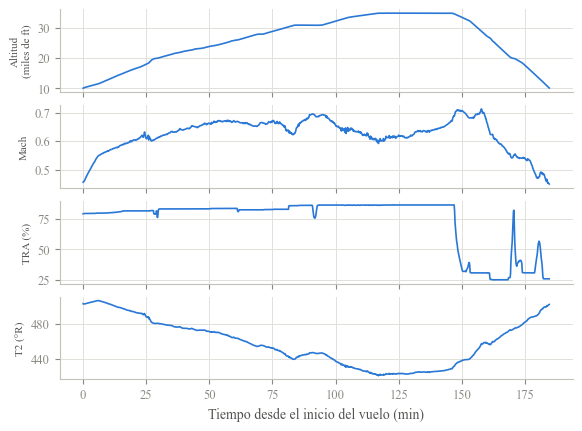

Motor 2, ciclo 3: 1109 registros, 3.1 h


In [20]:
EXAMPLE_UNIT = 2.0                                       # motor de entrenamiento del ejemplo
_m = dev["unit"] == EXAMPLE_UNIT
_cycles = np.unique(dev["cycle"][_m])
_lens = np.array([np.sum(_m & (dev["cycle"] == c)) for c in _cycles])
# Vuelo cuya duración es la más cercana a la mediana del motor
EXAMPLE_CYCLE = float(_cycles[np.argmin(np.abs(_lens - np.median(_lens)))])
_f = _m & (dev["cycle"] == EXAMPLE_CYCLE)
_t = np.arange(_f.sum()) * SAMPLE_STEP / 60              # tiempo desde el inicio, en minutos
W_LABELS = {"alt": "Altitud\n(miles de ft)", "Mach": "Mach", "TRA": "TRA (%)", "T2": "T2 (°R)"}

fig, axes = plt.subplots(4, 1, figsize=(FIG_W, 4.2), sharex=True, layout="constrained")
for j, (ax, name) in enumerate(zip(axes, var_names["W"])):
    v = dev["features"][_f, j] / (1000 if name == "alt" else 1)
    ax.plot(_t, v, color=ARCH_COLORS["A5"], lw=1.2)
    ax.set_ylabel(W_LABELS[name], fontsize=8)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(3))
axes[-1].set_xlabel("Tiempo desde el inicio del vuelo (min)")
save_fig(fig, "fig_vuelo_tipico")
plt.show()
print(f"Motor {EXAMPLE_UNIT:.0f}, ciclo {EXAMPLE_CYCLE:.0f}: {_f.sum()} registros, "
      f"{_t[-1] / 60:.1f} h")

## 1.4 Cómo se ve la degradación en los sensores

Los sensores dependen sobre todo de la condición de vuelo: una temperatura del motor sube
y baja con el empuje y la altitud mucho más de lo que cambia por la degradación. Para
medirlo, se ajusta para cada sensor una regresión con las 4 variables de W y sus términos
cuadráticos, usando solo los registros **sanos** de los motores de entrenamiento. El
coeficiente R² dice qué fracción de la variación del sensor explica la condición de vuelo.
El residuo (sensor medido menos lo que predice W) es lo que la condición de vuelo no
explica.

Luego, en cada motor de entrenamiento, se promedia el sensor y su residuo en cada ciclo, y
se mide con la correlación de Spearman si ese promedio sube o baja de forma sostenida a lo
largo de la vida.

Este análisis es solo descriptivo: la regresión no forma parte del modelo, que recibe W y
los sensores sin transformar (salvo la normalización) y aprende por sí mismo a separar
ambos efectos.

In [21]:
POLY_DEGREE = 2                                         # W y sus términos cuadráticos
_train = np.isin(dev["unit"], TRAIN_UNITS)
_healthy = _train & (dev["hs"] == 1)                    # registros sanos de entrenamiento
_poly = PolynomialFeatures(POLY_DEGREE, include_bias=False).fit(dev["features"][_healthy, :N_W])
_P_all = _poly.transform(dev["features"][:, :N_W])      # (registros, 14 términos de W)

RESIDUAL = {}                                           # sensor -> residuo de cada registro
rows = []
for j, name in enumerate(FEATURE_NAMES[N_W:]):
    y = dev["features"][:, N_W + j]
    reg = LinearRegression().fit(_P_all[_healthy], y[_healthy])
    RESIDUAL[name] = y - reg.predict(_P_all)
    rho_raw, rho_res = [], []
    for u in TRAIN_UNITS:
        m = dev["unit"] == u
        cyc = np.unique(dev["cycle"][m])
        raw_mean = [y[m & (dev["cycle"] == c)].mean() for c in cyc]
        res_mean = [RESIDUAL[name][m & (dev["cycle"] == c)].mean() for c in cyc]
        rho_raw.append(spearmanr(cyc, raw_mean)[0])
        rho_res.append(spearmanr(cyc, res_mean)[0])
    rows.append({"Sensor": name, "R² de W": reg.score(_P_all[_healthy], y[_healthy]),
                 "ρ sensor": np.median(rho_raw), "ρ residuo": np.median(rho_res),
                 "ρ residuo mín.": np.min(np.abs(rho_res))})
sens = pd.DataFrame(rows).sort_values("ρ residuo", key=np.abs, ascending=False).reset_index(drop=True)
print("R² = fracción de la variación del sensor explicada por W (registros sanos de entrenamiento).")
print("ρ = Spearman entre el número de ciclo y el promedio por ciclo; mediana sobre los 4 motores")
print("de entrenamiento. 'ρ residuo mín.' = el menor |ρ| entre los 4 motores.")
print(sens.round(3).to_string(index=False))

tab_sens = pd.DataFrame({"Sensor": sens["Sensor"],
                         "R² de W": [fmt_num(v, 3) for v in sens["R² de W"]],
                         "ρ, sensor medido": [fmt_num(v, 2, sign=True) for v in sens["ρ sensor"]],
                         "ρ, residuo": [fmt_num(v, 2, sign=True) for v in sens["ρ residuo"]]})
save_table(tab_sens, "tab_sensores_condicion")
cifra("RcuadradoWmin", sens["R² de W"].min(), 3, desc="menor R² de W sobre un sensor")
cifra("rhoTcuarentayochoMedido", sens.set_index("Sensor").loc["T48", "ρ sensor"], 2, sign=True,
      desc="Spearman ciclo vs promedio de T48 medido (mediana de 4 motores)")
cifra("rhoTcuarentayochoResiduo", sens.set_index("Sensor").loc["T48", "ρ residuo"], 2, sign=True,
      desc="Spearman ciclo vs promedio del residuo de T48 (mediana de 4 motores)")

R² = fracción de la variación del sensor explicada por W (registros sanos de entrenamiento).
ρ = Spearman entre el número de ciclo y el promedio por ciclo; mediana sobre los 4 motores
de entrenamiento. 'ρ residuo mín.' = el menor |ρ| entre los 4 motores.
Sensor  R² de W  ρ sensor  ρ residuo  ρ residuo mín.
   T48    1.000     0.376      0.971           0.961
   T50    0.999     0.391      0.967           0.956
    Nc    1.000    -0.108     -0.929           0.909
   T24    1.000     0.077      0.871           0.837
    Wf    1.000     0.113      0.849           0.795
   T30    1.000    -0.040     -0.846           0.832
   P40    1.000     0.010     -0.819           0.783
  Ps30    1.000     0.013     -0.807           0.744
   P24    1.000     0.080      0.805           0.703
   P50    1.000     0.065     -0.369           0.269
   P15    1.000     0.090      0.315           0.162
   P21    1.000     0.090      0.315           0.162
    P2    1.000     0.084      0.057           0.001
   

**Figura 1.2.** Promedio por ciclo del sensor T48 (temperatura a la salida de la turbina
de alta presión) en los cuatro motores de entrenamiento: (a) medido y (b) después de
restar el efecto de la condición de vuelo. El punto marca el ciclo de transición
(`hs` pasa de 1 a 0). Se elige T48 porque es el sensor con la tendencia más clara tras
corregir por W (tabla anterior).

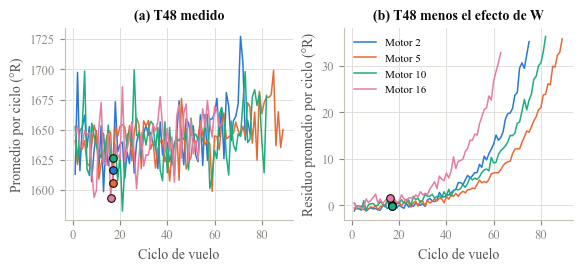

In [22]:
DEGRADATION_SENSOR = sens.loc[0, "Sensor"]               # el de mayor |ρ| del residuo
UNIT_COLORS = {2.0: "#2a78d6", 5.0: "#eb6834", 10.0: "#1baf7a", 16.0: "#e87ba4"}
j = FEATURE_NAMES.index(DEGRADATION_SENSOR)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.6), layout="constrained")
for u in TRAIN_UNITS:
    m = dev["unit"] == u
    cyc = np.unique(dev["cycle"][m])
    raw = np.array([dev["features"][m & (dev["cycle"] == c), j].mean() for c in cyc])
    res = np.array([RESIDUAL[DEGRADATION_SENSOR][m & (dev["cycle"] == c)].mean() for c in cyc])
    t_tr = dev["cycle"][m & (dev["hs"] == 0)].min()
    for ax, v in zip(axes, (raw, res)):
        ax.plot(cyc, v, color=UNIT_COLORS[u], lw=1.1, label=f"Motor {u:.0f}")
        k = np.where(cyc == t_tr)[0][0]
        # Punto con borde negro en el ciclo de transición, para que se distinga de la línea
        ax.scatter([t_tr], [v[k]], s=30, color=UNIT_COLORS[u], edgecolor=INK, linewidth=0.8, zorder=3)
axes[0].set_title(f"(a) {DEGRADATION_SENSOR} medido")
axes[1].set_title(f"(b) {DEGRADATION_SENSOR} menos el efecto de W")
axes[0].set_ylabel("Promedio por ciclo (°R)")
axes[1].set_ylabel("Residuo promedio por ciclo (°R)")
for ax in axes:
    ax.set_xlabel("Ciclo de vuelo")
axes[1].legend(loc="upper left", fontsize=8)
save_fig(fig, "fig_degradacion_sensor")
plt.show()

**Lectura.** La condición de vuelo explica prácticamente toda la variación de cada sensor
(R² de 0,999 o más). Por eso el promedio del sensor medido apenas muestra la degradación,
mientras que el residuo sube de forma sostenida en los cuatro motores: la degradación es una
señal pequeña montada sobre una variación grande debida al vuelo. Esto justifica dos
decisiones del trabajo:

1. **El modelo recibe W junto con los sensores**, para poder descontar el efecto de la
   condición de vuelo.
2. **Las ventanas son cortas (5 minutos) y la red las procesa con convoluciones**, que
   combinan en cada paso los 18 canales: la relación entre W y los sensores en un mismo
   instante es la que delata la degradación.

## 1.5 Etiqueta de RUL y recorte lineal por tramos

El RUL de cada registro es el número de ciclos que faltan para la falla. Mientras el motor
está sano, los sensores no indican cuánto falta, así que la etiqueta se **recorta** en un
valor máximo: el RUL de los registros más tempranos se reemplaza por ese valor. Este
recorte lineal por tramos (PwL, *piecewise linear*) es habitual en la bibliografía de
C-MAPSS.

El valor máximo se calcula desde los datos: la mediana del RUL en el momento de la
transición (`hs` de 1 a 0) de los motores de entrenamiento.

In [23]:
tab_pwl = pd.DataFrame({"Motor de entrenamiento": [int(u) for u in TRAIN_UNITS],
                        "RUL en la transición (ciclos)": [int(t) for t in transitions]})
print(tab_pwl.to_string(index=False))
print(f"Mediana: {np.median(transitions):.1f} -> umbral PwL = {RUL_MAX:.0f} ciclos")
save_table(tab_pwl, "tab_pwl", align="rr")
cifra("RULmax", RUL_MAX, 0, desc="umbral del recorte PwL (ciclos)")
cifra("RULmedianaTransicion", np.median(transitions), 1, desc="mediana del RUL en la transición")

 Motor de entrenamiento  RUL en la transición (ciclos)
                      2                             58
                      5                             72
                     10                             65
                     16                             47
Mediana: 61.5 -> umbral PwL = 62 ciclos


**Figura 1.3.** RUL real y etiqueta recortada del motor 2. La zona sombreada son los ciclos
sanos (`hs = 1`). El umbral es una mediana, así que no coincide con la transición de cada
motor: el motor 2 pasa a degradado con RUL 58, de modo que su etiqueta empieza a bajar en
el ciclo 13 (RUL 62), cuatro ciclos antes de la transición. En el motor 5 (transición con
RUL 72) ocurre lo contrario: su etiqueta sigue recortada durante los primeros ciclos
degradados.

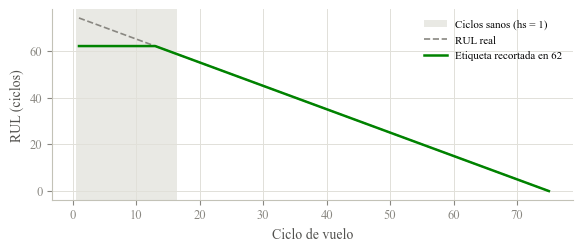

In [24]:
_m = dev["unit"] == EXAMPLE_UNIT
_cyc = np.unique(dev["cycle"][_m])
_rul = np.array([dev["rul"][_m & (dev["cycle"] == c)].max() for c in _cyc])   # RUL de cada ciclo
_healthy_cycles = np.unique(dev["cycle"][_m & (dev["hs"] == 1)])

fig, ax = plt.subplots(figsize=(FIG_W, 2.4), layout="constrained")
ax.axvspan(_healthy_cycles.min() - 0.5, _healthy_cycles.max() + 0.5, color=GRID, alpha=0.7, lw=0,
           label="Ciclos sanos (hs = 1)")
ax.plot(_cyc, _rul, color=MUTED, lw=1.2, ls="--", label="RUL real")
ax.plot(_cyc, np.minimum(_rul, RUL_MAX), color=ARCH_COLORS["A6"], lw=1.8,
        label=f"Etiqueta recortada en {RUL_MAX:.0f}")
ax.set_xlabel("Ciclo de vuelo")
ax.set_ylabel("RUL (ciclos)")
ax.legend(loc="upper right", fontsize=8)
save_fig(fig, "fig_rul_pwl")
plt.show()

## 1.6 Ventanas, partición y zonas de evaluación

- **Submuestreo:** se usa 1 de cada 10 registros, es decir, uno cada 10 s.
- **Ventanas:** 30 registros consecutivos de un mismo vuelo (5 minutos), que avanzan de 10
  en 10. La etiqueta de una ventana es el RUL de su último registro.
- **Partición por motor:** ningún motor aparece en dos conjuntos.
- **Normalización:** media y desviación de cada canal calculadas solo con los motores de
  entrenamiento.
- **Zonas de evaluación**, según el RUL real de la ventana: final (≤ 20 ciclos, la métrica
  principal), intermedia (20 a 40) y temprana (más de 40).

In [25]:
rows = []
for part, units, (X, y, meta) in (("Entrenamiento", TRAIN_UNITS, _T["train"]),
                                   ("Validación", VAL_UNITS, _T["val"]),
                                   ("Prueba", [11.0, 14.0, 15.0], _T["eval"])):
    frac = [np.mean(_zone_mask(y, lo, hi)) for _, lo, hi in ZONES]
    rows.append({"Conjunto": part, "Motores": ", ".join(str(int(u)) for u in units),
                 "Ventanas": fmt_num(len(y), 0),
                 **{f"Zona\n{n.lower()} (%)": fmt_num(100 * f, 1) for (n, _, _), f in zip(ZONES, frac)}})
    _macro = {"Entrenamiento": "Entrenamiento", "Validación": "Validacion", "Prueba": "Prueba"}[part]
    cifra(f"nVentanas{_macro}", len(y), 0, desc=f"ventanas del conjunto de {part.lower()}")
tab_particion = pd.DataFrame(rows)
print(tab_particion.to_string(index=False))
save_table(tab_particion, "tab_particion", align="llrrrr")

_y_val = _T["val"][1]
for (n, lo, hi) in ZONES:
    cifra(f"pctZona{n}Val", 100 * np.mean(_zone_mask(_y_val, lo, hi)), 1,
          desc=f"% de ventanas de validación en la zona {n.lower()}")
cifra("ventanaPasos", WINDOW_SIZE, 0, desc="pasos por ventana")
cifra("ventanaMinutos", WINDOW_SIZE * SAMPLE_STEP / 60, 0, desc="duración de una ventana (min)")

     Conjunto      Motores Ventanas Zona\nfinal (%) Zona\nintermedia (%) Zona\ntemprana (%)
Entrenamiento 2, 5, 10, 16   35 287            26.0                 26.3               47.7
   Validación       18, 20   16 251            31.1                 29.4               39.4
       Prueba   11, 14, 15   12 047            34.3                 29.7               36.0


## 1.7 Arquitecturas

Las seis arquitecturas comparadas en la ablación (v02 y v03) y las dos variantes con
pooling de v04. La columna "Antes de la agregación" es la forma del tensor que llega al
último estado, al promedio o a la atención: `(B, T, C)`, con B ventanas del lote, T pasos
de tiempo y C canales. El detalle de cada capa está en la sección 0.8 y en
`Diagramas.md`.

In [26]:
AGG_NAMES = {"last": "Último estado", "mean": "Promedio temporal", "attention": "Atención"}
tab_arq = arch_table.copy()                                # tabla de la sección 0.8
tab_arq["Agregación"] = tab_arq["Agregación"].map(AGG_NAMES)
tab_arq["Inspirada en"] = tab_arq["Inspirada en"].replace({"—": "—", "— (referencia por definir)": "—"})
print(tab_arq.to_string(index=False))
save_table(tab_arq.rename(columns={"Antes de la agregación": "Forma antes\nde agregar"}),
           "tab_arquitecturas", align="lp{2.5cm}p{1.8cm}lrp{2.7cm}")
# Número de parámetros de la base (A3) y de la configuración final (A6)
cifra("parametrosBase", count_params(make_model("A3")), 0, desc="parámetros de A3 (base)")
cifra("parametrosFinal", count_params(make_model("A6")), 0, desc="parámetros de A6 (final)")

   Id                              Arquitectura        Agregación Antes de la agregación Parámetros                                      Inspirada en
   A1                                    1D-CNN Promedio temporal            (B, 30, 64)     10.273 Sateesh Babu et al. (2016); Li, Ding y Sun (2018)
   A2                                      LSTM     Último estado            (B, 30, 64)     23.617             Zheng et al. (2017); Wu et al. (2018)
   A3                                CNN + LSTM     Último estado            (B, 30, 64)     29.025                                                 —
   A4                           LSTM + atención          Atención            (B, 30, 64)     27.841                de Oliveira da Costa et al. (2019)
   A5                     CNN + LSTM + atención          Atención            (B, 30, 64)     33.249                                  Li et al. (2022)
   A6                            CNN + atención          Atención            (B, 30, 64)     14.497 

## 1.8 Entrenamiento e hiperparámetros

Todos los modelos se entrenan igual. Los valores se fijaron en v01 y v02 y no se
ajustaron por arquitectura (limitación declarada).

In [27]:
HP_TABLE = [
    ("Submuestreo", f"1 de cada {SAMPLE_STEP} registros", "Un registro cada 10 s"),
    ("Largo de la ventana", f"{WINDOW_SIZE} pasos", "5 minutos de vuelo"),
    ("Desplazamiento entre ventanas", f"{STRIDE} pasos", "Ventanas consecutivas comparten 20 pasos"),
    ("Umbral del recorte PwL", f"{RUL_MAX:.0f} ciclos", "Mediana del RUL en la transición"),
    ("Filtros de la primera convolución", f"{CONV_CHANNELS}", "Kernel 3, padding 1"),
    ("Dimensión antes de la agregación", f"{HIDDEN_SIZE}", "Canales de la 2.ª convolución o unidades de la LSTM"),
    ("Dropout", fmt_num(DROPOUT, 1), "Uno por arquitectura"),
    ("Tamaño del lote", f"{BATCH_SIZE}", "Ventanas por lote"),
    ("Optimizador", "Adam", f"Tasa de aprendizaje {fmt_num(LR, 3)}"),
    ("Regularización L2", fmt_num(WEIGHT_DECAY, 4), "weight decay de Adam"),
    ("Máximo de épocas", f"{MAX_EPOCHS}", "Con early stopping"),
    ("Paciencia", f"{PATIENCE} épocas", "Épocas sin mejorar en validación antes de detener"),
    ("Semillas", f"{len(SEEDS)}", "0 a 4; cada configuración se entrena con todas"),
    ("Pérdida de la configuración final", "α = 2", "Pérdida cuadrática asimétrica"),
]
tab_hp = pd.DataFrame(HP_TABLE, columns=["Hiperparámetro", "Valor", "Comentario"])
print(tab_hp.to_string(index=False))
save_table(tab_hp, "tab_hiperparametros", align="p{4.2cm}lp{5.4cm}")
cifra("nSemillas", len(SEEDS), 0, desc="semillas por configuración")
cifra("maxEpocas", MAX_EPOCHS, 0, desc="máximo de épocas")
cifra("paciencia", PATIENCE, 0, desc="paciencia del early stopping")

                   Hiperparámetro                  Valor                                          Comentario
                      Submuestreo 1 de cada 10 registros                               Un registro cada 10 s
              Largo de la ventana               30 pasos                                  5 minutos de vuelo
    Desplazamiento entre ventanas               10 pasos            Ventanas consecutivas comparten 20 pasos
           Umbral del recorte PwL              62 ciclos                    Mediana del RUL en la transición
Filtros de la primera convolución                     32                                 Kernel 3, padding 1
 Dimensión antes de la agregación                     64 Canales de la 2.ª convolución o unidades de la LSTM
                          Dropout                    0.2                                Uno por arquitectura
                  Tamaño del lote                    256                                   Ventanas por lote
                   

## 1.9 Conclusiones de la etapa 1

1. **Datos.** DS02 tiene 9 motores; el modelo usa 18 variables por registro (4
   condiciones de vuelo y 14 sensores físicos) y no usa los sensores virtuales ni los
   parámetros de salud. Los ciclos de vida y de transición calculados coinciden con la
   documentación del conjunto.
2. **La degradación es una señal pequeña.** La condición de vuelo explica prácticamente
   toda la variación de cada sensor (R² de 0,999 o más); una vez descontada, la
   temperatura a la salida de la turbina de alta presión sube de forma sostenida en los
   cuatro motores de entrenamiento. Por eso el modelo recibe W junto con los sensores.
3. **Etiqueta.** El RUL se recorta en 62 ciclos, la mediana del RUL en la transición de
   los motores de entrenamiento.
4. **Dominio no visto.** Todos los motores de desarrollo son de clase de vuelo 3; dos de
   los tres de prueba no lo son, y validación no puede medir ese cambio de dominio.
5. **Observación sin resolver:** los vuelos de los datos son más cortos que lo que indica
   la definición de las clases de vuelo, en las tres clases.

### Valores elegidos en esta etapa

| Valor | Dónde | Por qué |
|---|---|---|
| Motor 2 y el vuelo de duración mediana | Figuras 1.1 y 1.3 | El motor 2 es de entrenamiento; el vuelo de duración mediana evita mostrar uno atípicamente corto o largo |
| Regresión de cada sensor con W y sus términos cuadráticos (grado 2) | Sección 1.4 | Con grado 1 quedaba curvatura sin explicar en varios sensores (la ρ del residuo de Nc era −0,61 con grado 1 y −0,93 con grado 2); grado 2 es el más simple que la captura |
| Ajuste solo con registros sanos de entrenamiento | Sección 1.4 | Así la regresión describe el motor sano, y la degradación queda en el residuo; no se usan motores de validación ni de prueba |
| Promedio por ciclo y Spearman | Sección 1.4 | El promedio por ciclo resume un vuelo en un número; Spearman mide si sube o baja de forma sostenida sin suponer una relación lineal |
| Sensor de la figura 1.2 = el de mayor \|ρ\| del residuo (T48) | Figura 1.2 | Se elige con un criterio de la tabla, no a ojo |
| Colores de los motores en la figura 1.2 | Figura 1.2 | Cuatro tonos de la paleta categórica de referencia; en esa figura no aparece ninguna arquitectura |
| Fondo blanco, letra tipo Times de 10 pt, 14,5 cm de ancho | Todas las figuras | Confirmado por el estudiante: coincide con el texto de la memoria |
| Punto decimal y espacio fino de miles en tablas y cifras exportadas | Sección 0.16 | La plantilla de la memoria usa `\decimalpoint`; con punto decimal, un punto de miles sería ambiguo |

Lo demás viene del protocolo: umbral PwL, ventanas, partición, zonas e hiperparámetros
(v01 y v02).

# Etapa 2 — Resultados experimentales

Material para el capítulo **Resultados** de la memoria. Cada sección carga desde disco las
corridas de v02 y v04 (no se entrena nada), presenta la tabla y la figura, y aplica la
regla de decisión **tal como se registró antes de ver los resultados** en
`ProjectV02/results/seleccion.json` y `ProjectV04/results/seleccion.json`. Los `assert`
comprueban que la decisión y sus cifras coinciden con las registradas en su momento.

| Sección | Pregunta | Regla registrada | Decisión |
|---|---|---|---|
| 2.1 | ¿Qué arquitectura? | Entre las con atención (A4, A5, A6), la de menor mediana de RMSE final | A6 |
| 2.2 | ¿Qué normalización? | La de menor mediana de RMSE final para A6; si ninguna nueva mejora a la global, se mantiene la global | Global |
| 2.3 | ¿Qué pérdida? | El α de menor mediana de score NASA final | α = 2 |
| 2.4 | ¿Agregar pooling? | Con α = 2, la mejor variante reemplaza a A6 solo si su mediana de RMSE final es menor **y** gana en 4 de 5 semillas | No |
| 2.5 | ¿Se generaliza a otros motores? | Sin selección: validación cruzada dejando un motor fuera | — |
| 2.6 | ¿Cómo rinde en motores nunca vistos? | Sin selección: única evaluación en el conjunto de prueba (v02) | — |

Todas las cifras son de validación (motores 18 y 20), mediana [mínimo – máximo] sobre 5
semillas, salvo en 2.5 (motor dejado fuera, 3 semillas) y 2.6 (prueba). Desde v05, el
sesgo que se informa es el de la **zona final**, la misma zona en que se decide; el sesgo
global se informa aparte cuando se cita.

In [28]:
def med_range_tex(values, dec=2, sign=False):
    """'mediana [mín. – máx.]' con el formato de la memoria (punto decimal, signo menos −)."""
    v = np.asarray(values, float)
    return (f"{fmt_num(np.median(v), dec, sign)} "
            f"[{fmt_num(v.min(), dec, sign)} – {fmt_num(v.max(), dec, sign)}]")


def summary_tex(df, group_col, groups, metrics, names=None, first_col="Configuración"):
    """Tabla de la memoria: una fila por grupo y 'mediana [mín. – máx.]' de cada métrica.
    `metrics` es una lista de (columna de df, encabezado, decimales, con signo)."""
    rows = []
    for g in groups:
        sub = df[df[group_col] == g]
        row = {first_col: (names or {}).get(g, g)}
        for col, header, dec, sign in metrics:
            row[header] = med_range_tex(sub[col], dec, sign)
        rows.append(row)
    return pd.DataFrame(rows)


def stacked(df, first=None):
    """Versión para la memoria: el rango [mín. – máx.] pasa a una segunda línea bajo la mediana,
    para que la tabla quepa en el ancho del texto. `first` = {texto: texto en dos líneas} para
    partir también los nombres largos de la primera columna."""
    out = df.map(lambda v: v.replace(" [", "\n[") if isinstance(v, str) else v)
    if first:
        out.iloc[:, 0] = out.iloc[:, 0].map(lambda v: first.get(v, v))
    return out


def wins(df_a, df_b, metric, key="seed"):
    """Cuántas semillas en que df_a tiene menor `metric` que df_b, comparando semilla con semilla."""
    a, b = df_a.set_index(key)[metric], df_b.set_index(key)[metric]
    return int((a < b.loc[a.index]).sum())


# Métricas que se informan en las tablas de validación: (columna, encabezado, decimales, con signo)
VAL_METRICS = [("RMSE final", "RMSE final", 2, False),
               ("Sesgo final", "Sesgo final", 2, True),
               ("Score NASA final", "Score NASA final", 2, False),
               ("RMSE", "RMSE global", 2, False)]

## 2.1 Ablación de arquitecturas (v02 y v03, etapa 1)

Las seis arquitecturas de la sección 1.7, entrenadas con MSE (α = 1) y normalización
global, 5 semillas cada una (30 corridas).

**Regla registrada:** entre las arquitecturas con atención (A4, A5, A6) se elige la de
menor mediana de RMSE final en validación. A3 (CNN + LSTM, la red de v01) se mantiene como
referencia sin atención.

In [29]:
ABL_ARCHS = ["A1", "A2", "A3", "A4", "A5", "A6"]
abl = run_many([dict(arch=a, alpha=1.0, seed=s) for a in ABL_ARCHS for s in SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in abl)
abl_df = records_to_df(abl, "val")
abl_df["label"] = abl_df["arch"].map(ARCH_LABELS)

# Aplicación de la regla y comprobación contra la decisión registrada en v02
_med = abl_df.groupby("arch")["RMSE final"].median()
STAGE1_CHOICE = _med[["A4", "A5", "A6"]].idxmin()
_a3, _a6 = abl_df[abl_df["arch"] == "A3"], abl_df[abl_df["arch"] == STAGE1_CHOICE]
print("Mediana de RMSE final por arquitectura:", _med.round(4).to_dict())
print(f"Elegida: {STAGE1_CHOICE} | mejor que A3 en {wins(_a6, _a3, 'RMSE final')} de 5 semillas")
if not SMOKE_TEST:
    assert STAGE1_CHOICE == "A6" and round(_med["A6"], 4) == 2.0039 and round(_med["A3"], 4) == 2.5993
    print("OK: coincide con la decisión registrada en v02 (A6, 2.0039; A3, 2.5993).")

tab_abl = summary_tex(abl_df, "arch", ABL_ARCHS, VAL_METRICS,
                      names={a: f"{a} · {ARCHS[a]['name']}" for a in ABL_ARCHS}, first_col="Arquitectura")
tab_abl.insert(1, "Parámetros", [fmt_num(count_params(make_model(a)), 0) for a in ABL_ARCHS])
print(tab_abl.to_string(index=False))
HEAD2 = {"RMSE final": "RMSE\nfinal", "Sesgo final": "Sesgo\nfinal", "Score NASA final": "Score\nNASA final",
         "RMSE global": "RMSE\nglobal", "Parámetros": "Pará-\nmetros"}   # encabezados en dos líneas
# Sin la columna de parámetros, que ya está en tab_arquitecturas, para que quepa en el ancho
save_table(stacked(tab_abl.drop(columns="Parámetros"),
                   first={n: n.replace(" · ", "\n") for n in tab_abl.iloc[:, 0]}).rename(columns=HEAD2),
           "tab_ablacion", align="lrrrr", colsep=4)
cifra("ablRMSEfinalAseis", _med["A6"], 2, desc="mediana de RMSE final de A6 (MSE) en validación")
cifra("ablRMSEfinalAtres", _med["A3"], 2, desc="mediana de RMSE final de A3 (MSE) en validación")
cifra("ablSemillasAseisMejorAtres", wins(_a6, _a3, "RMSE final"), 0, desc="semillas en que A6 mejora a A3")
cifra("ablRMSEfinalMin", _med.min(), 2, desc="menor mediana de RMSE final de la ablación")
cifra("ablRMSEfinalMaxSinAtres", _med.drop("A3").max(), 2,
      desc="mayor mediana de RMSE final de la ablación sin contar A3")

  A1 · global · alpha=1 · semilla 0 | mejor época  6/11 | caché
  A1 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A1 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A1 · global · alpha=1 · semilla 3 | mejor época  6/11 | caché
  A1 · global · alpha=1 · semilla 4 | mejor época  7/12 | caché
  A2 · global · alpha=1 · semilla 0 | mejor época  8/13 | caché
  A2 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A2 · global · alpha=1 · semilla 2 | mejor época 17/22 | caché
  A2 · global · alpha=1 · semilla 3 | mejor época  9/14 | caché
  A2 · global · alpha=1 · semilla 4 | mejor época  8/13 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
  A4 · global · alpha=1 · semilla 0 | me

**Figura 2.1.** RMSE final (izquierda) y sesgo final (derecha) de cada arquitectura en
validación. Cada punto es una semilla; el trazo negro, la mediana.

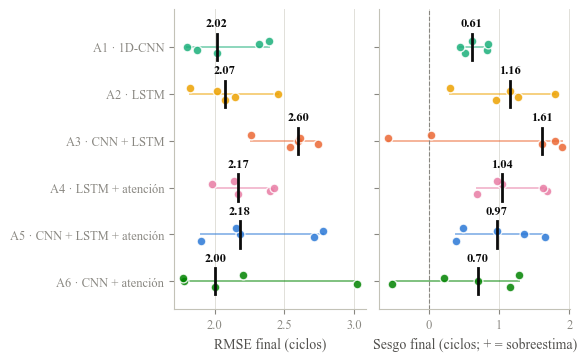

In [30]:
# Sin sharey: el panel derecho tiene sus propias marcas, que se ocultan para no repetir nombres
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.5), layout="constrained")
seed_dotplot(axes[0], abl_df, "RMSE final", ABL_ARCHS, labels={a: f"{a} · {ARCHS[a]['name']}" for a in ABL_ARCHS})
seed_dotplot(axes[1], abl_df, "Sesgo final", ABL_ARCHS)
axes[1].tick_params(labelleft=False)
axes[1].axvline(0, color=MUTED, lw=0.8, ls="--")
axes[0].set_xlabel("RMSE final (ciclos)")
axes[1].set_xlabel("Sesgo final (ciclos; + = sobreestima)")
save_fig(fig, "fig_ablacion")
plt.show()

**Figura 2.2.** Curvas de aprendizaje: RMSE de validación por época, en un eje común de 1 a
30 épocas (pedido de la Reunión 04). Cada línea tenue es una semilla y termina donde la
detuvo el early stopping; el punto marca la época conservada; la línea gruesa es la mediana
entre semillas.

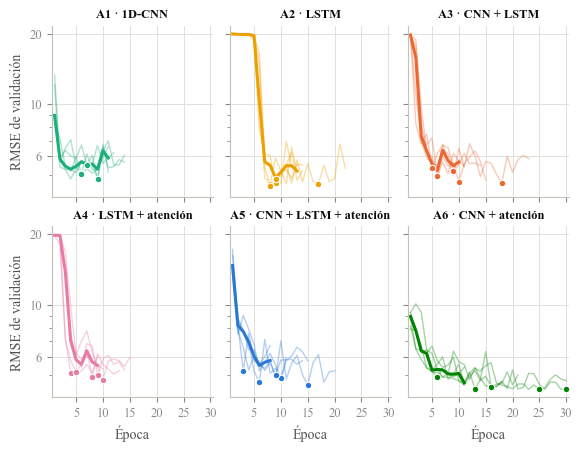

Mejor época por arquitectura (mediana y máximo):
      median  max
arch             
A1       7.0    9
A2       9.0   17
A3       9.0   18
A4       8.0   10
A5       9.0   15
A6      16.0   30
Corridas cuya mejor época fue la 30 (el límite): ['A6']


In [31]:
fig, axes = plt.subplots(2, 3, figsize=(FIG_W, 4.4), layout="constrained", sharex=True, sharey=True)
for ax, a in zip(axes.ravel(), ABL_ARCHS):
    seed_curves(ax, [r for r in abl if r["arch"] == a], color=ARCH_COLORS[a])
    set_epoch_axis(ax)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.FixedLocator([4, 6, 10, 20]))
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_title(f"{a} · {ARCHS[a]['name']}", fontsize=9)
for ax in axes[0]:
    ax.set_xlabel("")
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE de validación")
save_fig(fig, "fig_curvas_ablacion")
plt.show()
_ep = abl_df.groupby("arch")["best_epoch"].agg(["median", "max"])
_capped = {r["arch"] for r in abl if r["epochs"] == MAX_EPOCHS and r["best_epoch"] == MAX_EPOCHS}
print("Mejor época por arquitectura (mediana y máximo):")
print(_ep.to_string())
print(f"Corridas cuya mejor época fue la {MAX_EPOCHS} (el límite): {sorted(_capped) or 'ninguna'}")

**Lectura.** A6 (CNN + atención) tiene la menor mediana de RMSE final entre las
arquitecturas con atención y es la elegida. Pero las arquitecturas A1, A2, A4, A5 y A6
quedan a menos de 0,2 ciclos entre sí, con rangos que se superponen: con 5 semillas no se
distinguen. Solo A3 (CNN + LSTM, la red de v01) queda claramente peor. A6 mejora a A3 en 4
de 5 semillas. La ablación no es estricta entre extractores (A1 y A6 tienen una convolución
más que A3 y A5), limitación declarada en la sección 0.8.

## 2.2 Normalización (v02, etapa 2)

Se comparan la normalización global y las dos por condición de operación de la sección 0.6
(N1a, por régimen; N1b, por motor), con A6 y con A3, MSE y 5 semillas.

**Regla registrada:** se adopta la de menor mediana de RMSE final para la arquitectura de
la etapa anterior (A6); si ninguna nueva mejora a la global, se mantiene la global.

In [32]:
NORMS = ["global", "regimen", "motor"]
norm_runs = run_many([dict(arch=a, norm=n, alpha=1.0, seed=s) for a in ("A6", "A3")
                      for n in NORMS for s in SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in norm_runs)
norm_df = records_to_df(norm_runs, "val")
norm_df["grupo"] = norm_df["arch"] + " · " + norm_df["norm"].map(NORM_LABELS)
_medn = norm_df[norm_df["arch"] == "A6"].groupby("norm")["RMSE final"].median()
STAGE2_NORM = _medn.idxmin() if _medn.min() < _medn["global"] else "global"
print("A6, mediana de RMSE final por normalización:", _medn.round(4).to_dict())
print(f"Regímenes de N1a: K = {NORM_INFO['regimen']['k']} (silueta por K: "
      f"{ {k: round(v, 3) for k, v in NORM_INFO['regimen']['silueta'].items()} })")
if not SMOKE_TEST:
    assert STAGE2_NORM == "global" and NORM_INFO["regimen"]["k"] == 2
    assert [round(_medn[n], 4) for n in NORMS] == [2.0039, 2.0231, 3.288]
    print("OK: coincide con la decisión registrada en v02 (global; 2.0039, 2.0231, 3.288; K = 2).")

NORM_GROUPS = [f"{a} · {NORM_LABELS[n]}" for a in ("A6", "A3") for n in NORMS]
tab_norm = summary_tex(norm_df, "grupo", NORM_GROUPS, VAL_METRICS, first_col="Arquitectura y normalización")
print(tab_norm.to_string(index=False))
save_table(stacked(tab_norm, first={n: n.replace(" · ", "\n") for n in tab_norm.iloc[:, 0]}).rename(
    columns={"Arquitectura y normalización": "Arquitectura y\nnormalización"}),
    "tab_normalizacion", align="lrrrr", colsep=4)
cifra("normRMSEfinalNunoa", _medn["regimen"], 2, desc="mediana de RMSE final de A6 con N1a")
cifra("normRMSEfinalNunob", _medn["motor"], 2, desc="mediana de RMSE final de A6 con N1b")
cifra("normKregimenes", NORM_INFO["regimen"]["k"], 0, desc="regímenes de N1a")

  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché


  A6 · regimen · alpha=1 · semilla 0 | mejor época  7/12 | caché
  A6 · regimen · alpha=1 · semilla 1 | mejor época  7/12 | caché
  A6 · regimen · alpha=1 · semilla 2 | mejor época 14/19 | caché
  A6 · regimen · alpha=1 · semilla 3 | mejor época 18/23 | caché
  A6 · regimen · alpha=1 · semilla 4 | mejor época 19/24 | caché


  A6 · motor · alpha=1 · semilla 0 | mejor época  6/11 | caché
  A6 · motor · alpha=1 · semilla 1 | mejor época  7/12 | caché
  A6 · motor · alpha=1 · semilla 2 | mejor época  6/11 | caché
  A6 · motor · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A6 · motor · alpha=1 · semilla 4 | mejor época  4/ 9 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
  A3 · regimen · alpha=1 · semilla 0 | mejor época  6/11 | caché
  A3 · regimen · alpha=1 · semilla 1 | mejor época  4/ 9 | caché
  A3 · regimen · alpha=1 · semilla 2 | mejor época  4/ 9 | caché
  A3 · regimen · alpha=1 · semilla 3 | mejor época 11/16 | caché
  A3 · regimen · alpha=1 · semilla 4 | mejor época  9/14 | caché
  A3 · motor · alpha=1 · semilla 0 | mej

**Figura 2.3.** RMSE final con cada normalización, para A6 y A3.

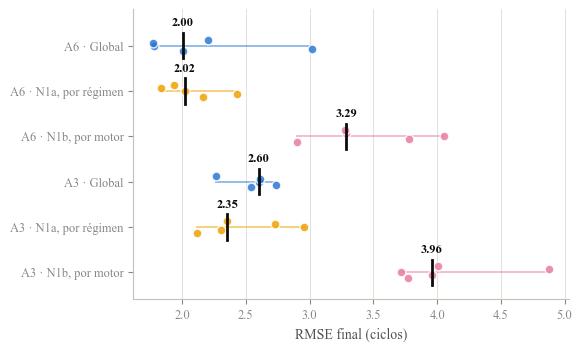

In [33]:
NORM_COLORS = {"Global": "#2a78d6", "N1a, por régimen": "#eda100", "N1b, por motor": "#e87ba4"}
_cols = {g: NORM_COLORS[g.split(" · ")[1]] for g in NORM_GROUPS}
fig, ax = plt.subplots(figsize=(FIG_W, 3.4), layout="constrained")
seed_dotplot(ax, norm_df, "RMSE final", NORM_GROUPS, group_col="grupo", colors=_cols)
ax.set_xlabel("RMSE final (ciclos)")
save_fig(fig, "fig_normalizacion")
plt.show()

**Lectura.** Con A6, la normalización por régimen (N1a) queda empatada con la global
(diferencia de 0,02 ciclos en la mediana) y la normalización por motor (N1b) es mucho peor:
usa como referencia los primeros ciclos de cada motor, y cada motor parte de una condición
de salud distinta. Se mantiene la global, que además es la más simple. N1a eligió K = 2
regímenes, que corresponden a un corte por altitud (v04, etapa 3).

## 2.3 Pérdida asimétrica (v02 y v03, etapa 2)

A6 con normalización global y α ∈ {1, 2, 4}, 5 semillas. Con α = 1 la pérdida es el MSE;
con α > 1, sobreestimar cuesta α veces más que subestimar (sección 0.9).

**Regla registrada:** el α de menor mediana de **score NASA final** en validación. Se usó el
score, y no el RMSE, porque el objetivo de la pérdida asimétrica es castigar más la
sobreestimación, y el score también lo hace (criterio C4 del diseño).

In [34]:
ALPHAS = [1.0, 2.0, 4.0]
alpha_runs = run_many([dict(arch="A6", alpha=al, seed=s) for al in ALPHAS for s in SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in alpha_runs)
alpha_df = records_to_df(alpha_runs, "val")
ALPHA_NAMES = {al: f"α = {al:g}" + (" (MSE)" if al == 1 else "") for al in ALPHAS}
alpha_df["grupo"] = alpha_df["alpha"].map(ALPHA_NAMES)
_meda = alpha_df.groupby("alpha")["Score NASA final"].median()
STAGE3_ALPHA = float(_meda.idxmin())
print("Mediana de score NASA final por α:", _meda.round(4).to_dict())
if not SMOKE_TEST:
    assert STAGE3_ALPHA == 2.0 and [round(_meda[a], 4) for a in ALPHAS] == [0.1756, 0.139, 0.1687]
    print("OK: coincide con la decisión registrada en v02 (α = 2; 0.1756, 0.139, 0.1687).")

ALPHA_METRICS = [("Score NASA final", "Score NASA final", 2, False),
                 ("RMSE final", "RMSE final", 2, False),
                 ("Sesgo final", "Sesgo final", 2, True),
                 ("% sobreest. final", "% sobreest. final", 1, False)]
tab_alpha = summary_tex(alpha_df, "grupo", [ALPHA_NAMES[a] for a in ALPHAS], ALPHA_METRICS,
                        first_col="Pérdida")
_mse, _a2 = alpha_df[alpha_df["alpha"] == 1.0], alpha_df[alpha_df["alpha"] == 2.0]
print(tab_alpha.to_string(index=False))
print(f"α = 2 mejora a MSE en RMSE final en {wins(_a2, _mse, 'RMSE final')} de 5 semillas y en "
      f"score final en {wins(_a2, _mse, 'Score NASA final')} de 5")
save_table(stacked(tab_alpha), "tab_alpha", align="lrrrr", colsep=4)
cifra("alphaScoreUno", _meda[1.0], 2, desc="mediana de score final con MSE")
cifra("alphaScoreDos", _meda[2.0], 2, desc="mediana de score final con alfa = 2")
cifra("alphaScoreCuatro", _meda[4.0], 2, desc="mediana de score final con alfa = 4")
cifra("alphaRMSEfinalDos", _a2["RMSE final"].median(), 2, desc="mediana de RMSE final de A6 con alfa = 2")
cifra("alphaSemillasDosMejorUno", wins(_a2, _mse, "RMSE final"), 0,
      desc="semillas en que alfa = 2 mejora a MSE en RMSE final")

  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché
  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · alpha=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
  A6 · global · alpha=4 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=4 · semilla 1 | mejor época  8/13 | caché
  A6 · global · alpha=4 · semilla 2 | mejor época  7/12 | caché
  A6 · global · alpha=4 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=4 · semilla 4 | mejor época 15/20 | caché
-> 15 corridas en 0.0 min (15 desde cach

**Comprobación de la teoría: qué estima el modelo.** La pérdida asimétrica es la de la
regresión por expectiles (Newey y Powell, 1987). En su óptimo se cumple
$\alpha \cdot \text{Sobreest. media} = \text{Subest. media}$ (`Guia_Estudio.md`, sección
6.2): el cociente subestimación / sobreestimación debería acercarse a α. Se mide en todas
las ventanas de validación y, desde v05, también en la zona final.

In [35]:
rows = []
for al in ALPHAS:
    g = alpha_df[alpha_df["alpha"] == al]
    rows.append({"α": f"{al:g}", "Valor teórico": f"{al:g}",
                 "Cociente, todas las ventanas": med_range_tex(g["Subest. media"] / g["Sobreest. media"]),
                 "Cociente, zona final": med_range_tex(g["Subest. media final"] / g["Sobreest. media final"])})
tab_exp = pd.DataFrame(rows)
print("Subestimación media / sobreestimación media en validación:")
print(tab_exp.to_string(index=False))
save_table(tab_exp, "tab_expectiles", align="crrr")
for al, name in ((1.0, "Uno"), (2.0, "Dos"), (4.0, "Cuatro")):
    g = alpha_df[alpha_df["alpha"] == al]
    cifra(f"cociente{name}", (g["Subest. media"] / g["Sobreest. media"]).median(), 2,
          desc=f"cociente subest./sobreest. en validación con alfa = {al:g}")

Subestimación media / sobreestimación media en validación:
α Valor teórico Cociente, todas las ventanas Cociente, zona final
1             1           1.05 [0.53 – 1.15]   0.33 [0.13 – 1.55]
2             2           1.75 [1.14 – 2.51]   1.07 [0.45 – 1.35]
4             4           3.53 [2.52 – 3.92]   2.01 [1.77 – 5.14]


**Figura 2.4.** Score NASA final (izquierda, el criterio) y RMSE final (derecha) para cada
α. Los colores van de claro a oscuro a medida que α crece.

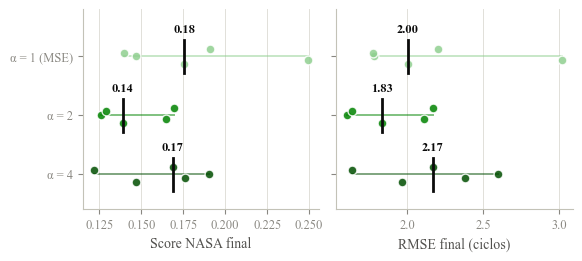

In [36]:
ALPHA_COLORS = {ALPHA_NAMES[1.0]: "#8fcf8f", ALPHA_NAMES[2.0]: "#008300", ALPHA_NAMES[4.0]: "#004d00"}
_ag = [ALPHA_NAMES[a] for a in ALPHAS]
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.5), layout="constrained", sharey=True)
seed_dotplot(axes[0], alpha_df, "Score NASA final", _ag, group_col="grupo", colors=ALPHA_COLORS)
seed_dotplot(axes[1], alpha_df, "RMSE final", _ag, group_col="grupo", colors=ALPHA_COLORS)
axes[0].set_xlabel("Score NASA final")
axes[1].set_xlabel("RMSE final (ciclos)")
save_fig(fig, "fig_alpha")
plt.show()

**Lectura.** α = 2 minimiza el score final y es el elegido. Frente a MSE mejora también el
RMSE final en las 5 semillas, y su sesgo final queda cerca de 0. Con α = 4 el modelo se
vuelve demasiado conservador: el score y el RMSE empeoran. El cociente entre subestimación
y sobreestimación crece con α como predice la teoría, aunque queda bajo el valor teórico,
porque la condición rige exactamente sobre los datos de entrenamiento. En la zona final el
cociente es menor: la condición se cumple en promedio sobre todas las ventanas, no zona por
zona (v05).

## 2.4 Pooling (v04, etapa 1)

A6 sin pooling y sus dos variantes (A6-P1, pooling tras la primera convolución; A6-P2, tras
cada convolución; sección 1.7), con α = 1 y α = 2, 5 semillas.

**Regla registrada (v04):** con α = 2, entre A6-P1 y A6-P2 se toma la de menor mediana de
RMSE final; reemplaza a A6 solo si (a) su mediana es menor que la de A6 y (b) es mejor que
A6 en al menos 4 de 5 semillas. Los resultados con α = 1 se informan pero no deciden.

In [37]:
POOL_STUDY = ["A6", "A6P1", "A6P2"]
pool_runs = run_many([dict(arch=a, alpha=al, seed=s) for al in (2.0, 1.0) for a in POOL_STUDY
                      for s in SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in pool_runs)
pool_df = records_to_df(pool_runs, "val")
pool_df["grupo"] = pool_df["arch"].map(ARCH_IDS) + ", " + pool_df["alpha"].map(ALPHA_NAMES)

_p2 = pool_df[pool_df["alpha"] == 2.0]
_medp = _p2.groupby("arch")["RMSE final"].median()
_cand = _medp[POOL_ARCHS].idxmin()
_wins_cand = wins(_p2[_p2["arch"] == _cand], _p2[_p2["arch"] == "A6"], "RMSE final")
POOL_ADOPTED = bool(_medp[_cand] < _medp["A6"] and _wins_cand >= 4)
print(f"α = 2, mediana de RMSE final: {_medp.round(4).to_dict()}")
print(f"Candidata: {ARCH_IDS[_cand]} | (a) mediana menor que A6: {_medp[_cand] < _medp['A6']} | "
      f"(b) semillas en que mejora a A6: {_wins_cand} de 5 | adoptada: {POOL_ADOPTED}")
if not SMOKE_TEST:
    assert not POOL_ADOPTED
    print("OK: coincide con la decisión registrada en v04 (el pooling no se adopta).")

POOL_GROUPS = [f"{ARCH_IDS[a]}, {ALPHA_NAMES[al]}" for al in (2.0, 1.0) for a in POOL_STUDY]
tab_pool = summary_tex(pool_df, "grupo", POOL_GROUPS, VAL_METRICS[:3], first_col="Variante")
tab_pool["Semillas mejor que A6"] = [
    "—" if g.startswith("A6,") else
    f"{wins(pool_df[pool_df['grupo'] == g], pool_df[(pool_df['arch'] == 'A6') & (pool_df['alpha'] == al)], 'RMSE final')} de 5"
    for g, al in zip(POOL_GROUPS, [2.0] * 3 + [1.0] * 3)]
print(tab_pool.to_string(index=False))
save_table(stacked(tab_pool, first={n: n.replace(", ", "\n") for n in tab_pool.iloc[:, 0]}).rename(
    columns={"Semillas mejor que A6": "Semillas\nmejor que A6"}), "tab_pooling", align="lrrrr", colsep=4)
_p1 = pool_df[pool_df["alpha"] == 1.0]
cifra("poolRMSEfinalAseisDos", _medp["A6"], 2, desc="mediana de RMSE final de A6 con alfa = 2")
cifra("poolRMSEfinalPdosDos", _medp["A6P2"], 2, desc="mediana de RMSE final de A6-P2 con alfa = 2")
cifra("poolRMSEfinalPunoDos", _medp["A6P1"], 2, desc="mediana de RMSE final de A6-P1 con alfa = 2")
cifra("poolRMSEfinalPdosUno", _p1[_p1["arch"] == "A6P2"]["RMSE final"].median(), 2,
      desc="mediana de RMSE final de A6-P2 con MSE")
cifra("poolSemillasCandidata", _wins_cand, 0, desc="semillas en que la candidata con pooling mejora a A6")

  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · alpha=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
  A6P1 · global · alpha=2 · semilla 0 | mejor época 13/18 | caché
  A6P1 · global · alpha=2 · semilla 1 | mejor época  6/11 | caché
  A6P1 · global · alpha=2 · semilla 2 | mejor época  7/12 | caché
  A6P1 · global · alpha=2 · semilla 3 | mejor época 14/19 | caché
  A6P1 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
  A6P2 · global · alpha=2 · semilla 0 | mejor época  4/ 9 | caché
  A6P2 · global · alpha=2 · semilla 1 | mejor época 17/22 | caché
  A6P2 · global · alpha=2 · semilla 2 | mejor época  8/13 | caché
  A6P2 · global · alpha=2 · semilla 3 | mejor época 14/19 | caché
  A6P2 · global · alpha=2 · semilla 4 | mejor época  5/10 | caché
  A6 · global · alph

**Figura 2.5.** RMSE final de A6 y sus variantes con pooling, con α = 2 (la comparación que
decide) y con MSE.

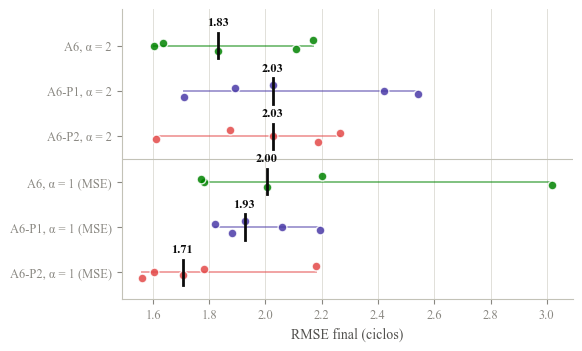

In [38]:
_pc = {g: ARCH_COLORS[next(a for a in POOL_STUDY if g.startswith(ARCH_IDS[a] + ","))] for g in POOL_GROUPS}
fig, ax = plt.subplots(figsize=(FIG_W, 3.4), layout="constrained")
seed_dotplot(ax, pool_df, "RMSE final", POOL_GROUPS, group_col="grupo", colors=_pc)
ax.axhline(2.5, color=AXIS, lw=0.8)                      # separa α = 2 (arriba) de MSE (abajo)
ax.set_xlabel("RMSE final (ciclos)")
save_fig(fig, "fig_pooling")
plt.show()

**Lectura.** Con α = 2 el pooling empeora el RMSE final (1,83 a 2,03 en las dos variantes),
y cada variante mejora a A6 en solo 2 de 5 semillas: no se adopta. Con MSE, A6-P2 sí mejora
a A6 (1,71 frente a 2,00). En la zona final, A6-P2 baja las predicciones con las dos
pérdidas, pero el cambio de RMSE se explica tanto o más por la variación del error que por
ese desplazamiento (v05, etapa 3). La bibliografía respalda la decisión: Li, Ding y Sun
(2018), con ventanas de 30 pasos como aquí, desaconsejan el pooling cuando la entrada es de
baja dimensión.

## 2.5 Validación cruzada dejando un motor fuera (v03, etapa 3)

Con solo dos motores de validación, el resultado depende de qué motores se eligieron. Para
medir cuánto se generaliza, se repite el entrenamiento seis veces, dejando fuera cada vez
uno de los seis motores de desarrollo para evaluar. En cada fold valida el motor siguiente
(de forma circular) y entrenan los otros cuatro. Se comparan la configuración final (A6,
α = 2) y la base (A3, MSE), con 3 semillas por fold (36 corridas). No se selecciona nada.

In [39]:
CV_UNITS = [2.0, 5.0, 10.0, 16.0, 18.0, 20.0]       # los 6 motores de desarrollo
CV_SEEDS = SEEDS[:3]                                 # 3 semillas por fold (v03)
rows = []
for k, u in enumerate(CV_UNITS):
    v = CV_UNITS[(k + 1) % len(CV_UNITS)]            # validación: el motor siguiente (circular)
    tr = [x for x in CV_UNITS if x not in (u, v)]
    # Cada fold es una partición más; build_tensors la trata igual que la oficial
    SPLITS[f"cv_u{int(u)}"] = {"name": f"cv_u{int(u)}", "train": tr, "val": [v], "eval": [u]}
    rows.append({"Fold": k + 1, "Motor evaluado": int(u), "Validación": int(v),
                 "Entrenamiento": ", ".join(str(int(x)) for x in tr)})
tab_folds = pd.DataFrame(rows)
print(tab_folds.to_string(index=False))

CV_CFGS = {"Final": dict(arch="A6", alpha=2.0), "Base": dict(arch="A3", alpha=1.0)}
cv_runs = run_many([dict(**c, seed=s, split=f"cv_u{int(u)}") for u in CV_UNITS
                    for c in CV_CFGS.values() for s in CV_SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in cv_runs)
cv_df = records_to_df(cv_runs, "eval")               # métricas sobre el motor dejado fuera
cv_df["Motor"] = cv_df["split"].str.replace("cv_u", "").astype(int)
cv_df["Config"] = np.where(cv_df["arch"] == "A6", "Final", "Base")

# Medianas por motor y comprobación contra v03
cv_med = cv_df.groupby(["Motor", "Config"])[["RMSE final", "Sesgo final", "Sesgo",
                                              "Sobreest. media final"]].median().unstack("Config")
if not SMOKE_TEST:
    ref = {2: (2.0191, 1.5501), 5: (5.5985, 2.992), 10: (2.7792, 2.2882),
           16: (1.8688, 3.3119), 18: (2.013, 1.8451), 20: (1.8865, 3.2957)}
    for u, (f, b) in ref.items():
        assert round(cv_med.loc[u, ("RMSE final", "Final")], 4) == f
        assert round(cv_med.loc[u, ("RMSE final", "Base")], 4) == b
    print("OK: el RMSE final por motor coincide con el registrado en v03.")

_pairs = cv_df.pivot_table(index=["Motor", "seed"], columns="Config",
                           values=["RMSE final", "Sobreest. media final"])
n_units_better = int((cv_med[("RMSE final", "Final")] < cv_med[("RMSE final", "Base")]).sum())
n_pairs_over = int((_pairs[("Sobreest. media final", "Final")] < _pairs[("Sobreest. media final", "Base")]).sum())
print(f"La final tiene menor RMSE final que la base en {n_units_better} de 6 motores (medianas)")
print(f"La final sobreestima menos en la zona final en {n_pairs_over} de {len(_pairs)} pares motor-semilla")

# Tabla para la memoria: por motor, vida, RMSE final y sesgo final de cada configuración
_life = {int(u): int(dev["cycle"][dev["unit"] == u].max()) for u in CV_UNITS}
rows = []
for u in CV_UNITS:
    u = int(u)
    g = {c: cv_df[(cv_df["Motor"] == u) & (cv_df["Config"] == c)] for c in ("Final", "Base")}
    rows.append({"Motor": u, "Vida (ciclos)": _life[u],
                 "RMSE final, base": med_range_tex(g["Base"]["RMSE final"]),
                 "RMSE final, final": med_range_tex(g["Final"]["RMSE final"]),
                 "Sesgo final, base": fmt_num(g["Base"]["Sesgo final"].median(), 2, True),
                 "Sesgo final, final": fmt_num(g["Final"]["Sesgo final"].median(), 2, True)})
tab_cv = pd.DataFrame(rows)
print(tab_cv.to_string(index=False))
save_table(tab_cv.rename(columns={"Vida (ciclos)": "Vida\n(ciclos)", "RMSE final, base": "RMSE final\nbase",
                                  "RMSE final, final": "RMSE final\nfinal", "Sesgo final, base": "Sesgo\nfinal, base",
                                  "Sesgo final, final": "Sesgo final,\nfinal"}),
           "tab_validacion_cruzada", align="rrrrrr", colsep=4)
cifra("cvMotoresMejor", n_units_better, 0, desc="motores en que la final tiene menor RMSE final que la base")
cifra("cvParesMenosSobreest", n_pairs_over, 0, desc="pares motor-semilla en que la final sobreestima menos")
cifra("cvPares", len(_pairs), 0, desc="pares motor-semilla de la validación cruzada")

 Fold  Motor evaluado  Validación  Entrenamiento
    1               2           5 10, 16, 18, 20
    2               5          10  2, 16, 18, 20
    3              10          16   2, 5, 18, 20
    4              16          18   2, 5, 10, 20
    5              18          20   2, 5, 10, 16
    6              20           2  5, 10, 16, 18


  A6 · global · alpha=2 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época  1/ 6 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  6/11 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época  9/14 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 16/21 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 11/16 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  4/ 9 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época 10/15 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 10/15 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 14/19 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época  8/13 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  5/10 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época  9/14 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 10/15 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 14/19 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época 11/16 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época 11/16 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 14/19 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época 22/27 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 14/19 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época 11/16 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  6/11 | caché
-> 36 corridas en 0.0 min (36 desde caché)
OK: el RMSE final por motor coincide con el registrado en v03.
La final tiene menor RMSE final que la base en 2 de 6 motores (medianas)
La final sobreestima menos en la zona final en 16 de 18 pares motor-semilla
 Motor  Vida (ciclos)   RMSE final, base  RMSE final, final Sesgo final, base Sesgo final, final
     2             75 1.55 [1.55 – 1.81] 2.02 [1.80 – 4.25]             +0.68              −1.18
     5             89 2.99 [2.66 – 3.48] 5.60 [4.05 – 8.01]             −1.92              −3.66
    10             82 2.29 [1.70 – 2.56] 2.78 [2.57 – 3.03]           

**Vida del motor y sesgo.** En v03 se encontró que los motores de vida más corta se
sobreestiman y los de vida más larga se subestiman, usando el sesgo **global** de cada
motor. Como en v05 se mostró que el sesgo global no representa la zona final, aquí se
repite con los dos: la correlación de Spearman entre la vida del motor y su sesgo mediano.

In [40]:
rows = []
for c in ("Base", "Final"):
    for col, name in (("Sesgo", "global"), ("Sesgo final", "zona final")):
        b = [cv_med.loc[int(u), (col, c)] for u in CV_UNITS]
        rows.append({"Configuración": c, "Sesgo": name,
                     "Spearman con la vida": spearmanr([_life[int(u)] for u in CV_UNITS], b)[0]})
life_corr = pd.DataFrame(rows)
print(life_corr.round(2).to_string(index=False))
for _, r in life_corr.iterrows():
    cifra(f"rhoVida{r['Configuración']}{'Global' if r['Sesgo'] == 'global' else 'Final'}",
          r["Spearman con la vida"], 2, sign=True,
          desc=f"Spearman vida-sesgo {r['Sesgo']}, configuración {r['Configuración'].lower()}")

# Predicciones fuera del rango válido (más de 5 ciclos fuera de [0, 62])
_out = [(r["arch"], int(np.sum((r["eval_pred"] > RUL_MAX + 5) | (r["eval_pred"] < -5))),
         float(r["eval_pred"].max())) for r in cv_runs]
for arch in ("A6", "A3"):
    n = sum(o[1] for o in _out if o[0] == arch)
    mx = max(o[2] for o in _out if o[0] == arch)
    print(f"{arch}: ventanas fuera de rango = {n}, predicción máxima = {mx:.0f} ciclos")
cifra("cvPrediccionMaxima", max(o[2] for o in _out if o[0] == "A6"), 0,
      desc="mayor predicción de A6 en la validación cruzada (ciclos)")

Configuración      Sesgo  Spearman con la vida
         Base     global                 -0.83
         Base zona final                 -0.94
        Final     global                 -0.89
        Final zona final                 -0.94
A6: ventanas fuera de rango = 19, predicción máxima = 190 ciclos
A3: ventanas fuera de rango = 0, predicción máxima = 62 ciclos


**Lectura.** La relación de v03 se confirma, y con más fuerza, al usar el sesgo de la zona
final: cuanto más larga la vida del motor, más se subestima su RUL cerca de la falla
(Spearman −0,94 en las dos configuraciones, frente a −0,83 y −0,89 con el sesgo global).
El modelo aprende una degradación promedio: un motor que se degrada más rápido que ese
promedio recibe predicciones optimistas, y uno más lento, pesimistas. Con 6 motores es un
indicio fuerte, no una prueba.

**Figura 2.6.** RMSE final de la base y de la configuración final en cada motor dejado
fuera (3 semillas por motor). Los motores están ordenados por su vida, de la más corta a la
más larga.

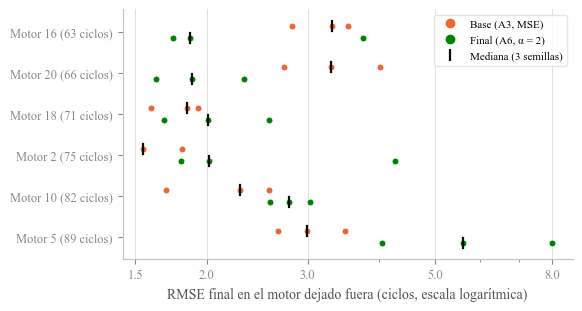

In [41]:
_order = sorted(CV_UNITS, key=lambda u: _life[int(u)])
cv_df["grupo"] = cv_df.apply(lambda r: f"Motor {r['Motor']} ({_life[r['Motor']]} ciclos)", axis=1)
_groups = [f"Motor {int(u)} ({_life[int(u)]} ciclos)" for u in _order]
fig, ax = plt.subplots(figsize=(FIG_W, 3.0), layout="constrained")
for c, color, off in (("Base", ARCH_COLORS["A3"], 0.15), ("Final", ARCH_COLORS["A6"], -0.15)):
    sub = cv_df[cv_df["Config"] == c]
    for i, g in enumerate(_groups):
        v = sub[sub["grupo"] == g]["RMSE final"].values
        y = len(_groups) - 1 - i + off
        ax.scatter(v, [y] * len(v), s=26, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3,
                   label=c if i == 0 else None)
        ax.plot([np.median(v)] * 2, [y - 0.12, y + 0.12], color=INK, lw=1.6, zorder=4)
ax.set_yticks(range(len(_groups)))
ax.set_yticklabels(_groups[::-1])
ax.grid(axis="y", visible=False)
ax.set_xscale("log")
ax.xaxis.set_major_locator(mticker.FixedLocator([1.5, 2, 3, 5, 8]))
ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel("RMSE final en el motor dejado fuera (ciclos, escala logarítmica)")
# Leyenda construida a mano: un marcador por configuración y el trazo de la mediana
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", lw=0, color=ARCH_COLORS["A3"], label="Base (A3, MSE)"),
                   Line2D([], [], marker="o", lw=0, color=ARCH_COLORS["A6"], label="Final (A6, α = 2)"),
                   Line2D([], [], marker="|", lw=0, markersize=9, markeredgewidth=1.6, color=INK,
                          label="Mediana (3 semillas)")],
          loc="upper right", fontsize=8, frameon=True, facecolor=SURFACE, edgecolor=GRID)   # esquina sin datos
save_fig(fig, "fig_validacion_cruzada")
plt.show()

**Lectura.** La ventaja de la configuración final no es uniforme. Es más precisa que la base
en solo 2 de los 6 motores (16 y 20, los de vida más corta), pero sobreestima menos en la
zona final en la gran mayoría de los pares motor-semilla. La pérdida asimétrica baja las
predicciones: corrige donde la base era optimista (motores de vida corta) y perjudica donde
ya era pesimista (motores 5 y 10, de vida larga). En el motor 5, además, A6 produce algunas
predicciones fuera del rango válido, porque su salida no está acotada (limitación declarada).

## 2.6 Conjunto de prueba oficial (v02, evaluado una sola vez)

Los motores 11, 14 y 15 no se usaron en ninguna decisión. El conjunto de prueba se evaluó
**una sola vez**, en v02, con todas las decisiones ya tomadas. Aquí se cargan esas
predicciones guardadas para tres configuraciones: la base (A3, MSE), A6 con MSE (aísla el
efecto de la arquitectura) y la final (A6, α = 2).

**Métrica nueva, declarada.** Además de las métricas de v02, se informa el **sesgo de la
zona final en prueba**, calculado por primera vez en v06 desde las predicciones guardadas
(decisión del estudiante, 17 de noviembre de 2026). Es una métrica descriptiva: todas las
decisiones están cerradas y ninguna depende de ella. Las demás cifras se comprueban contra
la tabla de v03 (`ProjectV03/results/prueba_oficial.csv`).

In [42]:
TEST_CFGS = {"Base (A3, MSE)": dict(arch="A3", alpha=1.0), "A6, MSE": dict(arch="A6", alpha=1.0),
             "Final (A6, α = 2)": dict(arch="A6", alpha=2.0)}
test_runs = run_many([dict(**c, seed=s) for c in TEST_CFGS.values() for s in SEEDS], label="  ")
assert SMOKE_TEST or all(r["cached"] for r in test_runs)      # nada se entrena con la prueba a la vista
test_df = records_to_df(test_runs, "eval")
_inv = {(c["arch"], c["alpha"]): n for n, c in TEST_CFGS.items()}
test_df["Configuración"] = [_inv[(a, al)] for a, al in zip(test_df["arch"], test_df["alpha"])]

if not SMOKE_TEST:
    v03 = pd.read_csv("../ProjectV03/results/prueba_oficial.csv", encoding="utf-8-sig")
    _cols = [c for c in ("RMSE final", "Sobreest. media final", "% sobreest. final", "Score NASA final",
                         "RMSE", "MAE", "Score NASA", "Sesgo", "% sobreest.", "RMSE final u11",
                         "RMSE final u14", "RMSE final u15", "RMSE u11", "RMSE u14", "RMSE u15")
             if c in v03.columns]
    both = test_df.merge(v03, on=["arch", "alpha", "seed"], suffixes=("", "_v03"))
    _dmax = max(float(np.max(np.abs(both[c] - both[c + "_v03"]))) for c in _cols)
    assert len(both) == 15 and _dmax < 1e-9
    print(f"OK: {len(_cols)} métricas de prueba coinciden con v03 (diferencia máxima {_dmax:.1e}).")

    # Registro de la métrica nueva en seleccion.json
    selection["decisiones"]["sesgo_final_prueba_v06"] = {
        "nota": "Métrica descriptiva calculada en v06 desde predicciones guardadas; no interviene en decisiones.",
        "mediana_por_configuracion": {n: round(float(test_df[test_df["Configuración"] == n]["Sesgo final"].median()), 4)
                                      for n in TEST_CFGS}}
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

TEST_METRICS = [("RMSE final", "RMSE final", 2, False),
                ("Sesgo final", "Sesgo final*", 2, True),
                ("% sobreest. final", "% sobreest. final", 1, False),
                ("Score NASA final", "Score NASA final", 2, False),
                ("RMSE", "RMSE global", 2, False),
                ("Sesgo", "Sesgo global", 2, True)]
tab_test = summary_tex(test_df, "Configuración", list(TEST_CFGS), TEST_METRICS)
print(tab_test.to_string(index=False))
print("* Sesgo de la zona final: calculado en v06 (métrica descriptiva declarada).")
# En la memoria, las dos columnas globales muestran solo la mediana, para que la tabla quepa
_tt = tab_test.copy()
for col in ("RMSE global", "Sesgo global"):
    _tt[col] = _tt[col].str.split(" \\[").str[0]
save_table(stacked(_tt, first={n: n.replace(" (", "\n(") for n in TEST_CFGS}).rename(columns={
                                    "RMSE final": "RMSE\nfinal", "Sesgo final*": "Sesgo\nfinal*",
                                    "% sobreest. final": "% sobreest.\nfinal", "Score NASA final": "Score\nNASA final",
                                    "RMSE global": "RMSE\nglobal", "Sesgo global": "Sesgo\nglobal"}),
           "tab_prueba", align="lrrrrrr", colsep=3)

# RMSE final por motor de prueba
rows = []
for n in TEST_CFGS:
    g = test_df[test_df["Configuración"] == n]
    rows.append({"Configuración": n, **{f"Motor {u} (clase {fc})": med_range_tex(g[f"RMSE final u{u}"])
                                       for u, fc in ((11, 3), (14, 1), (15, 2))}})
tab_test_u = pd.DataFrame(rows)
print(tab_test_u.to_string(index=False))
save_table(tab_test_u, "tab_prueba_motores", align="lrrr")

_tm = {n: test_df[test_df["Configuración"] == n] for n in TEST_CFGS}
for n, key in (("Base (A3, MSE)", "Base"), ("A6, MSE", "AseisMSE"), ("Final (A6, α = 2)", "Final")):
    g = _tm[n]
    cifra(f"pruebaRMSEfinal{key}", g["RMSE final"].median(), 2, desc=f"prueba: mediana de RMSE final, {n}")
    cifra(f"pruebaSesgoFinal{key}", g["Sesgo final"].median(), 2, sign=True, desc=f"prueba: mediana de sesgo final, {n}")
    cifra(f"pruebaSobreestFinal{key}", g["% sobreest. final"].median(), 1, desc=f"prueba: % de ventanas sobreestimadas, zona final, {n}")
    cifra(f"pruebaScoreFinal{key}", g["Score NASA final"].median(), 2, desc=f"prueba: mediana de score final, {n}")
    cifra(f"pruebaRMSEfinalMin{key}", g["RMSE final"].min(), 2, desc=f"prueba: mínimo de RMSE final, {n}")
    cifra(f"pruebaRMSEfinalMax{key}", g["RMSE final"].max(), 2, desc=f"prueba: máximo de RMSE final, {n}")
cifra("pruebaMejoraPct", 100 * (1 - _tm["Final (A6, α = 2)"]["RMSE final"].median()
                                / _tm["Base (A3, MSE)"]["RMSE final"].median()), 0,
      desc="reducción porcentual de la mediana de RMSE final, final frente a base (prueba)")

# Cifras globales de la configuración final para la comparación con el estado del arte
# (capítulo 2 de la memoria). Los trabajos publicados en DS02 informan el RMSE sobre toda la
# vida de cada motor de prueba, no solo en la zona final, por eso se exportan el RMSE y el MAE
# globales y el RMSE global por motor. Se calculan con las mismas predicciones guardadas de v02
# (comprobadas arriba contra v03); no es una consulta nueva al conjunto de prueba.
_gf = _tm["Final (A6, α = 2)"]
for col, key, nom in (("RMSE", "RMSEglobal", "RMSE global"), ("MAE", "MAEglobal", "MAE global")):
    cifra(f"prueba{key}Final", _gf[col].median(), 2, desc=f"prueba: mediana de {nom}, Final (A6, α = 2)")
    cifra(f"prueba{key}MinFinal", _gf[col].min(), 2, desc=f"prueba: mínimo de {nom}, Final (A6, α = 2)")
    cifra(f"prueba{key}MaxFinal", _gf[col].max(), 2, desc=f"prueba: máximo de {nom}, Final (A6, α = 2)")
# Nombres de macro solo con letras: 11 → Once, 14 → Catorce, 15 → Quince
for u, nom in ((11, "Once"), (14, "Catorce"), (15, "Quince")):
    cifra(f"pruebaRMSEu{nom}Final", _gf[f"RMSE u{u}"].median(), 2,
          desc=f"prueba: mediana de RMSE global del motor {u}, Final (A6, α = 2)")
    cifra(f"pruebaRMSEu{nom}MinFinal", _gf[f"RMSE u{u}"].min(), 2,
          desc=f"prueba: mínimo de RMSE global del motor {u}, Final (A6, α = 2)")
    cifra(f"pruebaRMSEu{nom}MaxFinal", _gf[f"RMSE u{u}"].max(), 2,
          desc=f"prueba: máximo de RMSE global del motor {u}, Final (A6, α = 2)")

  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché
  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · alpha=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
-> 15 corridas en 0.0 min (15 desde cach

**Figura 2.7.** RMSE final (izquierda) y sesgo final (derecha) en el conjunto de prueba.

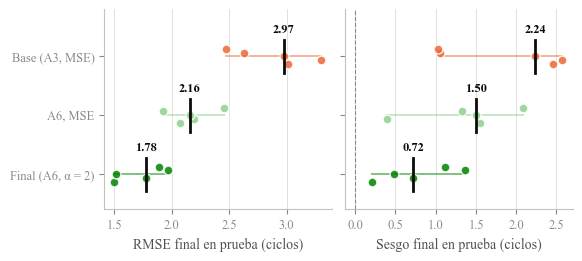

In [43]:
_tc = {"Base (A3, MSE)": ARCH_COLORS["A3"], "A6, MSE": "#8fcf8f", "Final (A6, α = 2)": ARCH_COLORS["A6"]}
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.5), layout="constrained", sharey=True)
seed_dotplot(axes[0], test_df, "RMSE final", list(TEST_CFGS), group_col="Configuración", colors=_tc)
seed_dotplot(axes[1], test_df, "Sesgo final", list(TEST_CFGS), group_col="Configuración", colors=_tc)
axes[1].axvline(0, color=MUTED, lw=0.8, ls="--")
axes[0].set_xlabel("RMSE final en prueba (ciclos)")
axes[1].set_xlabel("Sesgo final en prueba (ciclos)")
save_fig(fig, "fig_prueba")
plt.show()

**Lectura.**

- **Precisión.** La configuración final obtiene 1,78 ciclos de RMSE final, frente a 2,97 de
  la base: su peor semilla es mejor que la mejor de la base, y mejora en los tres motores,
  incluidos los dos de clases de vuelo que no aparecen en desarrollo (14 y 15). El cambio
  de arquitectura explica la mayor parte de la mejora (2,97 → 2,16) y la pérdida asimétrica
  el resto (2,16 → 1,78).
- **Sesgo en la zona final (métrica nueva).** En prueba, la configuración final **sigue
  sobreestimando cerca de la falla**: +0,72 ciclos en mediana, positivo en las 5 semillas, y
  sobreestima el 67 % de las ventanas de la zona final. La pérdida asimétrica redujo la
  sobreestimación a un tercio de la de la base (+2,24), pero no la eliminó. El sesgo global
  que se citaba hasta v05 (+0,19) daba una imagen más favorable, porque mezcla la zona
  final con la temprana, que se subestima por el recorte en 62. Es coherente con la
  validación cruzada: los motores de prueba tienen vidas cortas (59 a 76 ciclos), y los
  motores de vida corta tienden a sobreestimarse.

## 2.7 Conclusiones de la etapa 2

Las cifras exactas quedan en `Memoria/cifras.tex`; aquí, redondeadas.

1. **Arquitectura.** A6 (CNN + atención) tiene la menor mediana de RMSE final entre las
   arquitecturas con atención (2,00 ciclos en validación, frente a 2,60 de la base A3), pero
   cinco de las seis arquitecturas no se distinguen con 5 semillas.
2. **Normalización.** La global se mantiene: N1a empata (2,02) y N1b es mucho peor (3,29).
3. **Pérdida.** α = 2 minimiza el score final (0,14 frente a 0,18 con MSE) y mejora el RMSE
   final en las 5 semillas (1,83). La relación entre subestimación y sobreestimación sigue lo
   que predice la regresión por expectiles.
4. **Pooling.** No se adopta: con α = 2 empeora el RMSE final (2,03) y gana en solo 2 de 5
   semillas.
5. **Generalización.** En la validación cruzada la ventaja no es uniforme: la configuración
   final es más precisa en 2 de 6 motores, aunque sobreestima menos en 16 de 18 pares
   motor-semilla. El sesgo de cada motor depende de su vida (Spearman −0,94 con el sesgo de
   la zona final): los de vida corta se sobreestiman y los de vida larga se subestiman.
6. **Prueba.** En los motores nunca vistos la configuración final obtiene 1,78 ciclos de RMSE
   final, frente a 2,97 de la base, y mejora en los tres motores. Su sesgo en la zona final,
   calculado en v06 y declarado, es +0,72: la configuración final reduce la sobreestimación
   cerca de la falla a un tercio, pero no la elimina.

### Valores elegidos en esta etapa

| Valor | Dónde | Por qué |
|---|---|---|
| Sesgo de la zona final en las tablas, en vez del global | Todas las tablas | Es la métrica de la zona en que se decide (salvaguarda de v05); el global se informa aparte en la tabla de prueba |
| Colores de la normalización (azul, amarillo, rosa) | Figura 2.3 | Tres tonos de la paleta categórica que no son los de A3 ni A6, para no confundir normalizaciones con arquitecturas |
| Verdes de claro a oscuro para α = 1, 2 y 4 | Figuras 2.4 y 2.7 | α es una magnitud ordenada: un solo tono que se oscurece con α (el verde de A6, la arquitectura de esa comparación) |
| Escala logarítmica en la figura 2.6 | Figura 2.6 | El RMSE final del motor 5 llega a 8 ciclos; en escala lineal aplastaría las diferencias de los demás motores |
| Margen de 5 ciclos para contar predicciones fuera de rango | Sección 2.5 | Es el criterio de v03; evita contar como fuera de rango errores normales cerca de 0 o de 62 |
| Encabezados en dos líneas y espacio entre columnas de 3 o 4 pt | Tablas exportadas | Para que las tablas quepan en los 14,5 cm del texto |

# Etapa 3 — Análisis y factibilidad

Material para los capítulos **Análisis y discusión** y **Evaluación de factibilidad** de la
memoria. Reúne los análisis de v03 a v05 sobre las predicciones ya guardadas y agrega una
medición nueva, el tiempo de inferencia en CPU.

| Sección | Pregunta | Origen |
|---|---|---|
| 3.1 | ¿Cuánto se sobreestima y dónde? | v05, etapa 1 |
| 3.2 | ¿Por qué el score NASA es tan pequeño y cuándo no sigue al RMSE? | v05, etapa 2 |
| 3.3 | ¿Por qué unos motores se sobreestiman y otros no? | v03, etapa 4, con el sesgo de la zona final (etapa 2 de este notebook) |
| 3.4 | ¿Qué miran los pesos de atención? | v03 y v04 |
| 3.5 | ¿El error depende de la fase de vuelo o del régimen de operación? | v03, etapa 4, y v04, etapa 3 |
| 3.6 | ¿El modelo es implementable? Tamaño, tiempo de inferencia y de entrenamiento | Nuevo en v06 |

Todo es en validación (motores 18 y 20), salvo la validación cruzada (3.3) y la medición de
tiempos (3.6), que no usa etiquetas.

In [44]:
_, y_val, meta_val = build_tensors("global", "oficial")["val"]
REC = {name: [r for r in analysis if CONFIG_NAMES[(r["arch"], r["alpha"])] == name]
       for name in (BASE_NAME, FINAL_NAME)}                  # corridas de la base y de la final
CONF_COLORS = {BASE_NAME: ARCH_COLORS["A3"], FINAL_NAME: ARCH_COLORS["A6"]}

## 3.1 El sesgo por zona de RUL y el recorte en 62 (v05, etapa 1)

El sesgo, $\frac{1}{N}\sum_i(\hat{y}_i - y_i)$, es la sobreestimación media menos la
subestimación media (sección 0.10). El sesgo de todas las ventanas (global) es el promedio
de los sesgos de las tres zonas, ponderado por su número de ventanas. La tabla muestra el
sesgo de cada zona y su aporte al global (fracción de ventanas × sesgo de la zona).

In [45]:
_frac = {n: float(np.mean(_zone_mask(y_val, lo, hi))) for n, lo, hi in ZONES}
rows = []
for name in (BASE_NAME, FINAL_NAME):
    g = val_df[val_df["Configuración"] == name]
    row = {"Configuración": name, "Global": med_range_tex(g["Sesgo"], 2, True)}
    for zn, _, _ in ZONES:
        row[f"Sesgo {zn.lower()}"] = med_range_tex(g[f"Sesgo {zn.lower()}"], 2, True)
        row[f"Aporte {zn.lower()}"] = fmt_num((_frac[zn] * g[f"Sesgo {zn.lower()}"]).median(), 2, True)
    rows.append(row)
tab_sz = pd.DataFrame(rows)
print("Fracción de ventanas por zona:", {k: round(v, 3) for k, v in _frac.items()})
print(tab_sz.to_string(index=False))
# Para la memoria, sin la zona intermedia (que no cambia la lectura) para que quepa en el ancho
_tex = tab_sz[["Configuración", "Global", "Sesgo final", "Sesgo temprana", "Aporte temprana"]]
save_table(stacked(_tex, first={n: n.replace(" (", "\n(") for n in _tex.iloc[:, 0]}).rename(columns={
    "Global": "Sesgo\nglobal", "Sesgo final": "Sesgo\nzona final",
    "Sesgo temprana": "Sesgo\nzona temprana", "Aporte temprana": "Aporte de la\ntemprana al global"}),
    "tab_sesgo_zonas", align="lrrrr", colsep=4)

_g = val_df[val_df["Configuración"] == FINAL_NAME]
cifra("fracZonaTempranaVal", 100 * _frac["Temprana"], 0, desc="% de ventanas de validación en la zona temprana")
cifra("sesgoGlobalFinalVal", _g["Sesgo"].median(), 2, True, desc="sesgo global de la final en validación")
cifra("sesgoFinalFinalVal", _g["Sesgo final"].median(), 2, True, desc="sesgo de la zona final de la final en validación")
cifra("aporteTempranaFinalVal", (_frac["Temprana"] * _g["Sesgo temprana"]).median(), 2, True,
      desc="aporte de la zona temprana al sesgo global (final, validación)")
cifra("sobreestMediaFinalVal", _g["Sobreest. media final"].median(), 2, desc="sobreestimación media, zona final (final, validación)")
cifra("subestMediaFinalVal", _g["Subest. media final"].median(), 2, desc="subestimación media, zona final (final, validación)")
cifra("pctSobreestFinalVal", _g["% sobreest. final"].median(), 0, desc="% de ventanas sobreestimadas, zona final (final, validación)")
cifra("sesgoFinalMotorDieciocho", _g["Sesgo final u18"].median(), 2, True, desc="sesgo final del motor 18 (final)")
cifra("sesgoFinalMotorVeinte", _g["Sesgo final u20"].median(), 2, True, desc="sesgo final del motor 20 (final)")
_pct_sist = (100 * _g["Sesgo final"] ** 2 / _g["RMSE final"] ** 2).median()
cifra("pctSistematicoFinal", _pct_sist, 1, desc="% del RMSE² final que es sesgo² (final, validación)")
_gb = val_df[val_df["Configuración"] == BASE_NAME]
cifra("pctSistematicoBase", (100 * _gb["Sesgo final"] ** 2 / _gb["RMSE final"] ** 2).median(), 0,
      desc="% del RMSE² final que es sesgo² (base, validación)")

Fracción de ventanas por zona: {'Final': 0.311, 'Intermedia': 0.294, 'Temprana': 0.394}
    Configuración                Global           Sesgo final Aporte final      Sesgo intermedia Aporte intermedia        Sesgo temprana Aporte temprana
   Base (A3, MSE) +1.56 [+0.72 – +1.91] +1.61 [−0.59 – +1.89]        +0.50 +3.12 [+2.33 – +3.89]             +0.92 +0.96 [+0.06 – +1.33]           +0.38
Final (A6, α = 2) −0.93 [−1.53 – −0.21] −0.04 [−0.21 – +0.47]        −0.01 +0.55 [−0.13 – +1.29]             +0.16 −2.82 [−3.62 – −0.97]           −1.11


**Figura 3.1.** Error medio de las ventanas que tienen cada valor de RUL real (0 a 62
ciclos), para la base y la configuración final. La línea es la mediana entre semillas y la
banda va del mínimo al máximo.

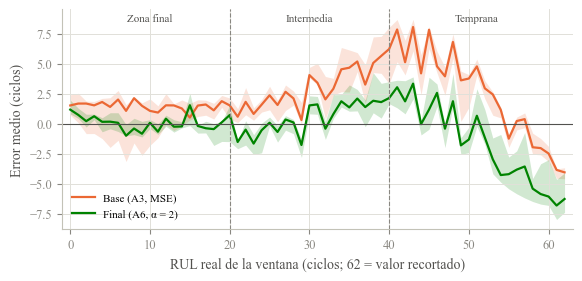

Final (A6, α = 2): sesgo de las ventanas con etiqueta 62 = -6.24 ciclos
Base (A3, MSE): sesgo de las ventanas con etiqueta 62 = -4.03 ciclos


In [46]:
_values = np.unique(y_val)                                   # 0, 1, ..., 62
fig, ax = plt.subplots(figsize=(FIG_W, 2.7), layout="constrained")
for name, recs in REC.items():
    curves = np.array([[np.mean(r["val_pred"][y_val == v] - v) for v in _values] for r in recs])
    ax.fill_between(_values, curves.min(axis=0), curves.max(axis=0), color=CONF_COLORS[name], alpha=0.18, lw=0)
    ax.plot(_values, np.median(curves, axis=0), color=CONF_COLORS[name], lw=1.6, label=name)
ax.axhline(0, color=INK_2, lw=0.8)
for x in (20, 40):
    ax.axvline(x, color=MUTED, lw=0.8, ls="--")
for x, name in ((10, "Zona final"), (30, "Intermedia"), (51, "Temprana")):
    ax.annotate(name, (x, 1.0), xycoords=("data", "axes fraction"), xytext=(0, -3),
                textcoords="offset points", ha="center", va="top", color=INK_2, fontsize=8)
ax.set_xlim(-1, RUL_MAX + 1)
ax.set_xlabel(f"RUL real de la ventana (ciclos; {RUL_MAX:.0f} = valor recortado)")
ax.set_ylabel("Error medio (ciclos)")
ax.legend(loc="lower left", fontsize=8)
save_fig(fig, "fig_error_vs_rul")
plt.show()

_cap = y_val == RUL_MAX
for name, key in ((FINAL_NAME, "Final"), (BASE_NAME, "Base")):
    b = np.median([np.mean(r["val_pred"][_cap] - RUL_MAX) for r in REC[name]])
    print(f"{name}: sesgo de las ventanas con etiqueta {RUL_MAX:.0f} = {b:+.2f} ciclos")
    cifra(f"sesgoTope{key}", b, 2, True, desc=f"sesgo de las ventanas con etiqueta 62, {name}")
cifra("pctVentanasTope", 100 * _cap.mean(), 0, desc="% de ventanas de validación con etiqueta 62")

**Lectura.** Cerca de la falla la configuración final no tiene sesgo en validación (−0,04),
pero el sesgo global es negativo (−0,93) porque lo domina la zona temprana: el 39 % de las
ventanas, subestimadas por el recorte. Como ninguna etiqueta supera 62, el promedio que
aprende el modelo en el tope de la escala solo puede quedar por debajo; las ventanas con
etiqueta 62 se subestiman unos 6 ciclos. Por motor, el sesgo final de −0,04 es el promedio
de dos sesgos opuestos (motor 18: −1,04; motor 20: +1,07). En la zona final el sesgo
explica una parte mínima del RMSE² de la configuración final (el resto es variación de una
ventana a otra), frente a un tercio en la base.

## 3.2 El score NASA (v05, etapa 2)

$s(d) = e^{-d/13} - 1$ si $d < 0$ y $e^{d/10} - 1$ si $d \ge 0$; en este trabajo se
promedia sobre las ventanas. Con errores pequeños la exponencial es casi una recta, así que
el score se comporta como un MAE asimétrico:
$\text{Score} \approx \text{Sobreest. media}/10 + \text{Subest. media}/13$.

**Figura 3.2.** La función $s(d)$ y sus aproximaciones lineales. La franja gris contiene el
90 % central de los errores de la configuración final en la zona final.

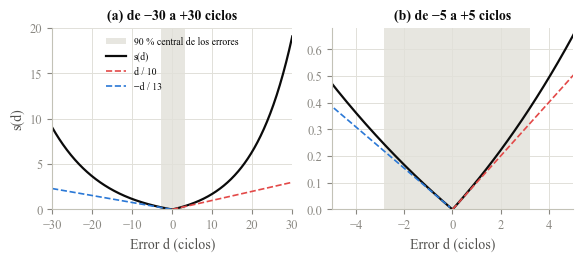

90 % central de los errores: -2.87 a 3.21 | score 0.139 equivale a sobreestimar 1.30 o subestimar 1.69 ciclos | suma 704


In [47]:
_fz = y_val <= FINAL_ZONE
_d_fin = np.concatenate([r["val_pred"][_fz] - y_val[_fz] for r in REC[FINAL_NAME]])
_q05, _q95 = np.quantile(_d_fin, [0.05, 0.95])
_dd = np.linspace(-30, 30, 601)
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.5), layout="constrained")
for ax, lim in zip(axes, (30, 5)):                           # vista completa y acercamiento
    ax.axvspan(_q05, _q95, color=GRID, alpha=0.8, lw=0, label="90 % central de los errores")
    ax.plot(_dd, nasa_terms(_dd), color=INK, lw=1.6, label="s(d)")
    ax.plot(_dd[_dd >= 0], _dd[_dd >= 0] / 10, color="#e34948", lw=1.2, ls="--", label="d / 10")
    ax.plot(_dd[_dd < 0], -_dd[_dd < 0] / 13, color="#2a78d6", lw=1.2, ls="--", label="−d / 13")
    m = np.abs(_dd) <= lim
    ax.set_xlim(-lim, lim)
    ax.set_ylim(0, nasa_terms(_dd[m]).max() * 1.05)
    ax.set_xlabel("Error d (ciclos)")
axes[0].set_ylabel("s(d)")
axes[0].set_title("(a) de −30 a +30 ciclos")
axes[1].set_title("(b) de −5 a +5 ciclos")
axes[0].legend(loc="upper center", fontsize=7)
save_fig(fig, "fig_score_funcion")
plt.show()

_S = _g["Score NASA final"].median()
cifra("scoreFinalVal", _S, 2, desc="score NASA final de la final (validación)")
cifra("scoreEquivSobre", 10 * np.log1p(_S), 1, desc="error constante sobreestimando con el mismo score (ciclos)")
cifra("scoreEquivSub", 13 * np.log1p(_S), 1, desc="error constante subestimando con el mismo score (ciclos)")
cifra("errorFinalQcinco", _q05, 1, True, desc="percentil 5 del error, zona final (final)")
cifra("errorFinalQnoventaycinco", _q95, 1, True, desc="percentil 95 del error, zona final (final)")
_sum = np.median([np.sum(nasa_terms(r["val_pred"][_fz] - y_val[_fz])) for r in REC[FINAL_NAME]])
cifra("scoreSumaFinal", _sum, 0, desc="score de la final sumado sobre la zona final de validación")
print(f"90 % central de los errores: {_q05:.2f} a {_q95:.2f} | score {_S:.3f} equivale a "
      f"sobreestimar {10 * np.log1p(_S):.2f} o subestimar {13 * np.log1p(_S):.2f} ciclos | suma {_sum:.0f}")

**¿Cuándo no sigue al RMSE?** Se comparan, sobre las 60 corridas de validación con
normalización global de la etapa 2 (ablación, α y pooling), cómo ordenan las corridas el
score, el RMSE, el MAE y el MAE asimétrico (correlación de rangos de Spearman).

In [48]:
all_val = (pd.concat([abl_df, alpha_df, pool_df], ignore_index=True)
           .drop_duplicates(subset=["arch", "alpha", "seed"]).reset_index(drop=True))
all_val["MAE asimétrico final"] = all_val["Sobreest. media final"] / 10 + all_val["Subest. media final"] / 13
rows = []
for m1, name in (("RMSE final", "RMSE"), ("MAE final", "MAE"), ("MAE asimétrico final", "MAE asimétrico")):
    rho = spearmanr(all_val[m1], all_val["Score NASA final"])[0]
    rows.append({"Métrica": name, "Spearman con el score": rho})
    cifra(f"rhoScore{name.replace(' asimétrico', 'Asim')}", rho, 2, desc=f"Spearman score final vs {name} final (60 corridas)")
print(f"Corridas: {len(all_val)}")
print(pd.DataFrame(rows).round(3).to_string(index=False))
cifra("nCorridasScore", len(all_val), 0, desc="corridas de la comparación score/RMSE")

Corridas: 60
       Métrica  Spearman con el score
          RMSE                  0.945
           MAE                  0.913
MAE asimétrico                  0.990


**Lectura.** El score es pequeño porque con errores de 1 a 2 ciclos cada ventana aporta
entre 0,08 y 0,22, y aquí se promedia. En la bibliografía se suma (Sateesh Babu et al., 2016;
Li, Ding y Sun, 2018; Li, Wang y Li, 2022): con la suma, las mismas predicciones darían unos
700 en la zona final, así que los valores no son comparables con los publicados. En general
el score ordena las corridas como el RMSE; cuando no, la causa es su asimetría (ordena casi
igual que el MAE asimétrico), que favorece a los modelos que subestiman.

## 3.3 Vida del motor y sesgo (v03, etapa 4)

**Figura 3.3.** Sesgo de la zona final de cada motor de desarrollo cuando se deja fuera en
la validación cruzada (mediana de 3 semillas), frente a su vida total. Se incluyen la base y
la configuración final.

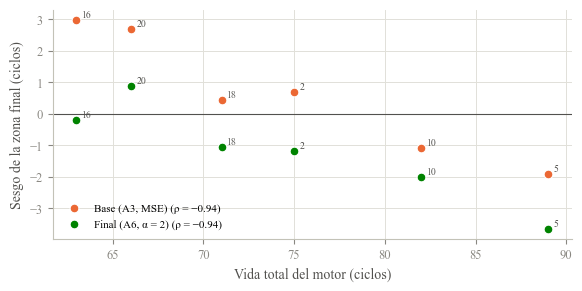

In [49]:
fig, ax = plt.subplots(figsize=(FIG_W, 2.8), layout="constrained")
for c, name in (("Base", BASE_NAME), ("Final", FINAL_NAME)):
    lives = [_life[int(u)] for u in CV_UNITS]
    bias = [cv_med.loc[int(u), ("Sesgo final", c)] for u in CV_UNITS]
    ax.scatter(lives, bias, s=40, color=CONF_COLORS[name], edgecolor=SURFACE, linewidth=0.8, zorder=3,
               label=f"{name} (ρ = {fmt_num(spearmanr(lives, bias)[0], 2, True)})")
    for u, x, yb in zip(CV_UNITS, lives, bias):
        ax.annotate(f"{int(u)}", (x, yb), xytext=(4, 2), textcoords="offset points", fontsize=7, color=INK_2)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Vida total del motor (ciclos)")
ax.set_ylabel("Sesgo de la zona final (ciclos)")
ax.legend(loc="lower left", fontsize=8)
save_fig(fig, "fig_vida_sesgo")
plt.show()

**Lectura.** Los motores de vida corta se sobreestiman cerca de la falla y los de vida larga
se subestiman, con las dos configuraciones. La pérdida asimétrica desplaza toda la nube hacia
abajo: corrige los motores de vida corta y empeora los de vida larga. Los motores de prueba
tienen vidas de 59 a 76 ciclos, en el rango corto, lo que es coherente con el sesgo positivo
en prueba de la sección 2.6.

## 3.4 Pesos de atención (v03 y v04)

La atención de A4, A5 y A6 asigna un peso a cada uno de los 30 pasos de la ventana. Si todos
los pasos pesaran igual, cada peso valdría 1/30. La figura muestra el peso medio por paso
multiplicado por 30 (1 = promedio uniforme), en validación, promediando las 5 semillas.

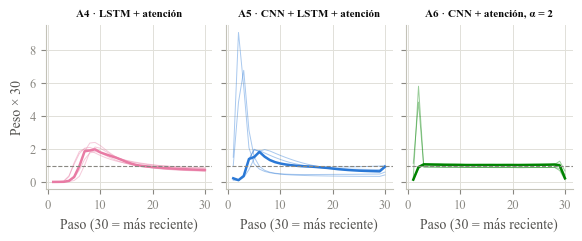

Peso × 30 (mediana entre semillas):
Arquitectura  Interior: mín.  Interior: máx.  Paso 1  Paso 30
          A4            0.01            1.98    0.01     0.73
          A5            0.37            1.83    0.22     0.92
          A6            1.03            1.07    0.14     0.23


In [50]:
ATT_CFGS = [("A4", 1.0, abl), ("A5", 1.0, abl), ("A6", 2.0, alpha_runs)]
_Xv = build_tensors("global", "oficial")["val"][0]
ATT = {}
for arch, al, recs in ATT_CFGS:
    rs = [r for r in recs if r["arch"] == arch and r["alpha"] == al]
    # Pesos de cada semilla, forma (N ventanas, 30); se promedian ventanas y luego semillas
    ATT[(arch, al)] = np.array([predict(load_model(r), _Xv, collect_weights=True)[1].mean(axis=0) for r in rs])

fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 2.3), layout="constrained", sharey=True)
_steps = np.arange(1, WINDOW_SIZE + 1)
for ax, (arch, al, _) in zip(axes, ATT_CFGS):
    w = ATT[(arch, al)] * WINDOW_SIZE                       # (semillas, 30)
    for s in w:
        ax.plot(_steps, s, color=ARCH_COLORS[arch], lw=0.7, alpha=0.4)
    ax.plot(_steps, np.median(w, axis=0), color=ARCH_COLORS[arch], lw=1.8)
    ax.axhline(1, color=MUTED, lw=0.8, ls="--")
    ax.set_title(f"{arch} · {ARCHS[arch]['name']}" + (", α = 2" if al == 2 else ""), fontsize=8)
    ax.set_xlabel("Paso (30 = más reciente)")
axes[0].set_ylabel("Peso × 30")
save_fig(fig, "fig_atencion")
plt.show()

rows = []
for arch, al, _ in ATT_CFGS:
    w = np.median(ATT[(arch, al)] * WINDOW_SIZE, axis=0)
    inner = w[2:-2]                                          # pasos 3 a 28: sin los bordes
    rows.append({"Arquitectura": arch, "Interior: mín.": inner.min(), "Interior: máx.": inner.max(),
                 "Paso 1": w[0], "Paso 30": w[-1]})
att_tab = pd.DataFrame(rows)
print("Peso × 30 (mediana entre semillas):")
print(att_tab.round(2).to_string(index=False))
_w6 = att_tab.set_index("Arquitectura").loc["A6"]
cifra("atencionInteriorMin", _w6["Interior: mín."], 2, desc="peso×30 mínimo en los pasos 3 a 28 (A6 final)")
cifra("atencionInteriorMax", _w6["Interior: máx."], 2, desc="peso×30 máximo en los pasos 3 a 28 (A6 final)")

**Lectura.**

- **A6 (la configuración final):** en los pasos 3 a 28 los pesos son casi uniformes (entre
  1,03 y 1,07 veces el promedio): la atención funciona en la práctica como un promedio
  temporal. Los bordes se comportan distinto y varían entre semillas: en 2 de las 5 semillas
  el paso 2 recibe unas 5 veces el peso uniforme, y los pasos 1 y 30 suelen recibir poco. Son
  los pasos que la convolución calcula con el relleno de ceros (*padding*), la explicación
  más probable, no comprobada.
- **A4 y A5 (con LSTM):** los pesos no son uniformes: casi no pesan los primeros pasos, tienen
  un máximo entre los pasos 6 y 9 y luego decaen. Pero pesan salidas de la LSTM, y cada salida
  ya resume todos los pasos anteriores, así que los pesos no indican directamente qué instantes
  del vuelo son más informativos.

En ningún caso los pesos señalan instantes del vuelo con un significado físico claro, lo que
limita la interpretabilidad que se esperaba de la atención (criterio C8). Con datos que cambian
lentamente dentro de 5 minutos, un promedio, que es lo que hace A6, es una agregación razonable.

## 3.5 Fases de vuelo y regímenes de operación (v03, etapa 4; v04, etapa 3)

**Fases de vuelo.** Se calculan con la tasa de cambio de la altitud: ascenso si sube más de
10 pies por paso de 10 s, descenso si baja más que eso y nivelado en otro caso (umbral de
v03, elegido desde los datos porque los ascensos de N-CMAPSS son lentos).

**Regímenes.** Se agrupan las condiciones de vuelo con k-means y Spectral Clustering (K de 2
a 20) y DBSCAN, en dos espacios: W (4 variables) y W + X_s (18 variables, lo que ve el
modelo), sobre una submuestra de 8 000 registros de entrenamiento (como en v03 y v04).

In [51]:
from sklearn.cluster import DBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA

PHASE_NAMES = ["Ascenso", "Nivelado", "Descenso"]
PHASE_TH = 10.0                      # pies por paso de 10 s (v03)
CLUSTER_SAMPLE = 8000                # submuestra de registros de entrenamiento (v03)
K_RANGE = list(range(2, 21)) if not SMOKE_TEST else [2, 3]
SWEEP_FILE = os.path.join(OUT_DIR, "etapa3_barrido_k.csv")          # resultados del barrido
SWEEP_LABELS = os.path.join(OUT_DIR, "etapa3_barrido_k_grupos.npz")  # grupos de cada configuración


def flight_bounds(d):
    """Límites [inicio, fin) de cada vuelo: segmentos contiguos con el mismo (motor, ciclo)."""
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    return np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])


def flight_phases(d, th=PHASE_TH):
    """Fase de cada registro (0 ascenso, 1 nivelado, 2 descenso) según la tasa de cambio de la altitud."""
    alt, rate = d["features"][:, 0], np.zeros(len(d["unit"]))
    b = flight_bounds(d)
    for s, e in zip(b[:-1], b[1:]):
        if e - s >= 3:
            # Diferencia entre pasos vecinos, suavizada con una mediana móvil de 5 pasos
            rate[s:e] = pd.Series(np.gradient(alt[s:e])).rolling(5, center=True, min_periods=1).median().values
    phase = np.ones(len(rate), dtype=int)
    phase[rate > th], phase[rate < -th] = 0, 2
    return phase


phase_dev = flight_phases(dev)
_tr = np.isin(dev["unit"], TRAIN_UNITS)
SPACES = {"W (4D)": list(range(N_W)), "W + X_s (18D)": list(range(NUM_FEATURES))}
Z_DEV = {sp: StandardScaler().fit(dev["features"][_tr][:, c]).transform(dev["features"][:, c])
         for sp, c in SPACES.items()}                        # estandarizados con entrenamiento
SUB = np.random.default_rng(0).choice(np.where(_tr)[0], size=CLUSTER_SAMPLE, replace=False)   # semilla de v03
XS = {sp: Z_DEV[sp][SUB] for sp in SPACES}
print("Fracción de registros por fase (entrenamiento):",
      {n: round(100 * np.mean(phase_dev[_tr] == p), 1) for p, n in enumerate(PHASE_NAMES)})

# PCA de W: cuántas direcciones independientes tienen las 4 condiciones de vuelo
pca_w = PCA().fit(Z_DEV["W (4D)"][_tr])
tab_pca = pd.DataFrame({"Componente": [f"CP{i + 1}" for i in range(N_W)],
                        "Varianza explicada (%)": [fmt_num(100 * v, 1) for v in pca_w.explained_variance_ratio_],
                        "Acumulada (%)": [fmt_num(100 * v, 1) for v in np.cumsum(pca_w.explained_variance_ratio_)],
                        **{f"Peso {n}": [fmt_num(v, 2, True) for v in pca_w.components_[:, j]]
                           for j, n in enumerate(var_names["W"])}})
print(tab_pca.to_string(index=False))
save_table(tab_pca.rename(columns={"Varianza explicada (%)": "Varianza\nexplicada (%)",
                                   "Acumulada (%)": "Acumulada\n(%)"}), "tab_pca_w", align="lrrrrrr", colsep=4)
cifra("pcaCPuno", 100 * pca_w.explained_variance_ratio_[0], 0, desc="% de varianza de W en CP1")
cifra("pcaCPunodos", 100 * pca_w.explained_variance_ratio_[:2].sum(), 0, desc="% de varianza de W en CP1 + CP2")

Fracción de registros por fase (entrenamiento): {'Ascenso': 30.3, 'Nivelado': 47.0, 'Descenso': 22.7}
Componente Varianza explicada (%) Acumulada (%) Peso alt Peso Mach Peso TRA Peso T2
       CP1                   79.2          79.2    +0.55     +0.53    +0.37   −0.53
       CP2                   16.6          95.8    −0.22     −0.18    +0.93   +0.23
       CP3                    4.2         100.0    −0.15     +0.79    −0.03   +0.60
       CP4                    0.0         100.0    +0.79     −0.27    +0.00   +0.55


**Barrido de K.** Es la parte más costosa de esta etapa (78 agrupamientos; unos 2 minutos en
el equipo de desarrollo). Sus resultados se guardan en `results/` y, si ya existen, se cargan
en vez de recalcularse. Los métodos son deterministas (semilla 0), así que recalcular da el
mismo resultado.

In [52]:
def quality(X, lab):
    """Silueta (sobre 5 000 puntos) y Davies-Bouldin, sin contar el ruido de DBSCAN (-1)."""
    m = lab >= 0
    if len(np.unique(lab[m])) < 2:
        return np.nan, np.nan
    return (float(silhouette_score(X[m], lab[m], sample_size=min(5000, m.sum()), random_state=0)),
            float(davies_bouldin_score(X[m], lab[m])))


def run_sweep():
    """k-means y Spectral con K en K_RANGE y DBSCAN en el codo, en los dos espacios."""
    rows, labels = [], {}
    for sp in SPACES:
        X = XS[sp]
        cfgs = []
        for k in K_RANGE:
            cfgs.append(("k-means", k, KMeans(k, n_init=10, random_state=0).fit_predict(X)))
            cfgs.append(("Spectral", k, SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                                           n_neighbors=15, assign_labels="cluster_qr",
                                                           random_state=0).fit_predict(X)))
        # DBSCAN: eps en el codo de la distancia al k-ésimo vecino (v03), min_samples = 2 × dimensiones
        ms = 2 * X.shape[1]
        kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
        xn, yn = np.linspace(0, 1, len(kd)), (kd - kd[0]) / (kd[-1] - kd[0])
        cfgs.append(("DBSCAN", 0, DBSCAN(eps=float(kd[np.argmax(np.abs(yn - xn))]), min_samples=ms).fit_predict(X)))
        for method, k, lab in cfgs:
            sil, db = quality(X, lab)
            key = f"{sp}|{method}|{k}"
            labels[key] = lab
            rows.append({"Espacio": sp, "Método": method, "K": k, "Grupos": len(np.unique(lab[lab >= 0])),
                         "Silueta": sil, "Davies-Bouldin": db,
                         "Rand ajustado vs. fases": adjusted_rand_score(phase_dev[SUB], lab), "clave": key})
    return pd.DataFrame(rows), labels


if os.path.exists(SWEEP_FILE) and os.path.exists(SWEEP_LABELS) and not SMOKE_TEST:
    sweep_df = pd.read_csv(SWEEP_FILE, encoding="utf-8-sig")
    _npz = np.load(SWEEP_LABELS)
    sweep_labels = {k: _npz[k.replace("|", "__").replace(" ", "_")] for k in sweep_df["clave"]}
    print(f"Barrido cargado desde {SWEEP_FILE} ({len(sweep_df)} agrupamientos)")
else:
    _t0 = time.time()
    sweep_df, sweep_labels = run_sweep()
    print(f"Barrido calculado: {len(sweep_df)} agrupamientos en {(time.time() - _t0) / 60:.1f} min")
    if not SMOKE_TEST:
        sweep_df.to_csv(SWEEP_FILE, index=False, encoding="utf-8-sig")
        np.savez_compressed(SWEEP_LABELS, **{k.replace("|", "__").replace(" ", "_"): v
                                             for k, v in sweep_labels.items()})

best = (sweep_df[sweep_df["Método"] != "DBSCAN"].sort_values("Silueta", ascending=False)
        .groupby(["Espacio", "Método"]).head(1).set_index(["Espacio", "Método"]))
print(best[["K", "Silueta", "Rand ajustado vs. fases"]].round(3).to_string())
print(sweep_df[sweep_df["Método"] == "DBSCAN"][["Espacio", "Grupos", "Silueta"]].round(3).to_string(index=False))
_ari_max = sweep_df.loc[sweep_df["Rand ajustado vs. fases"].idxmax()]
print(f"Mayor Rand ajustado vs. fases de todo el barrido: {_ari_max['Rand ajustado vs. fases']:.3f} "
      f"({_ari_max['Método']}, {_ari_max['Espacio']}, K = {_ari_max['K']})")
cifra("randMaximoBarrido", _ari_max["Rand ajustado vs. fases"], 2, desc="mayor Rand ajustado vs. fases del barrido")
for sp, tag in (("W (4D)", "Cuatro"), ("W + X_s (18D)", "Dieciocho")):
    for method, mtag in (("k-means", "Kmeans"), ("Spectral", "Spectral")):
        cifra(f"silueta{mtag}{tag}", best.loc[(sp, method), "Silueta"], 2, desc=f"mejor silueta {method}, {sp}")
        cifra(f"mejorK{mtag}{tag}", best.loc[(sp, method), "K"], 0, desc=f"K de mejor silueta {method}, {sp}")
        cifra(f"rand{mtag}{tag}", best.loc[(sp, method), "Rand ajustado vs. fases"], 2,
              desc=f"Rand ajustado vs. fases, mejor {method}, {sp}")

Barrido cargado desde results\etapa3_barrido_k.csv (78 agrupamientos)
                        K  Silueta  Rand ajustado vs. fases
Espacio       Método                                       
W (4D)        k-means   2    0.509                    0.109
W + X_s (18D) k-means   3    0.479                    0.319
W (4D)        Spectral  2    0.445                    0.108
W + X_s (18D) Spectral  2    0.440                    0.117
      Espacio  Grupos  Silueta
       W (4D)      18   -0.479
W + X_s (18D)       1      NaN
Mayor Rand ajustado vs. fases de todo el barrido: 0.366 (Spectral, W + X_s (18D), K = 3)


**Figura 3.5.** Silueta (izquierda) y coincidencia con las fases de vuelo (Rand ajustado,
derecha) según el número de grupos K. Líneas continuas: W (4D); discontinuas: W + X_s (18D).
Las líneas punteadas grises marcan la escala de Kaufman y Rousseeuw (1990): bajo 0,25, sin
estructura; de 0,26 a 0,50, débil; de 0,51 a 0,70, razonable.

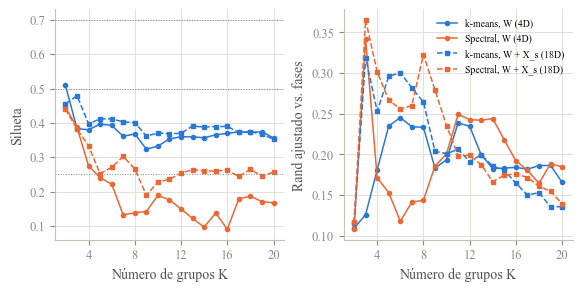

In [53]:
_km = sweep_df[sweep_df["Método"] != "DBSCAN"]
_MC = {"k-means": "#2a78d6", "Spectral": "#eb6834"}
_SS = {"W (4D)": dict(ls="-", marker="o"), "W + X_s (18D)": dict(ls="--", marker="s")}
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.8), layout="constrained")
for ax, metric in zip(axes, ("Silueta", "Rand ajustado vs. fases")):
    for sp in SPACES:
        for method in ("k-means", "Spectral"):
            s = _km[(_km["Espacio"] == sp) & (_km["Método"] == method)].sort_values("K")
            ax.plot(s["K"], s[metric], color=_MC[method], lw=1.1, ms=3, label=f"{method}, {sp}", **_SS[sp])
    ax.set_xlabel("Número de grupos K")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(4))
for lvl in (0.25, 0.50, 0.70):
    axes[0].axhline(lvl, color=MUTED, lw=0.7, ls=":")
axes[0].set_ylabel("Silueta")
axes[1].set_ylabel("Rand ajustado vs. fases")
axes[1].legend(loc="upper right", fontsize=7)
save_fig(fig, "fig_silueta_k")
plt.show()

**Error por fase de vuelo.** Cada ventana recibe la fase más frecuente entre sus 30
registros (mismo orden que las ventanas de `build_tensors`), y se mide el RMSE final de la
base y de la configuración final en cada fase, en validación.

In [54]:
def window_labels(rec_labels, source, units=None):
    """Etiqueta de cada ventana = la más frecuente entre sus 30 registros (mismo orden que _gather)."""
    starts, w_unit, _ = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    L = rec_labels[starts[m][:, None] + np.arange(WINDOW_SIZE)[None, :]]          # (N, 30)
    counts = np.stack([(L == c).sum(axis=1) for c in range(int(rec_labels.max()) + 1)], axis=1)
    return counts.argmax(axis=1)


RUN_PHASE_ERROR = not SMOKE_TEST          # en la prueba rápida las ventanas están submuestreadas
if RUN_PHASE_ERROR:
    ph_val = window_labels(phase_dev, "dev", VAL_UNITS)
    rows = []
    for p, pname in enumerate(PHASE_NAMES):
        m = ph_val == p
        fin = m & _fz
        row = {"Fase": pname, "Ventanas (%)": fmt_num(100 * m.mean(), 1)}
        for name, key in ((BASE_NAME, "base"), (FINAL_NAME, "final")):
            row[f"RMSE final, {key}"] = med_range_tex([rmse(y_val[fin], r["val_pred"][fin]) for r in REC[name]])
        row["Sesgo final, final"] = med_range_tex([np.mean(r["val_pred"][fin] - y_val[fin]) for r in REC[FINAL_NAME]], 2, True)
        rows.append(row)
    tab_fase = pd.DataFrame(rows)
    print(tab_fase.to_string(index=False))
    save_table(stacked(tab_fase).rename(columns={"Ventanas (%)": "Ventanas\n(%)", "RMSE final, base": "RMSE final\nbase",
                                                 "RMSE final, final": "RMSE final\nfinal",
                                                 "Sesgo final, final": "Sesgo final\nfinal"}),
               "tab_error_fase", align="lrrrr")
    for p, pname in enumerate(PHASE_NAMES):
        m = (ph_val == p) & _fz
        cifra(f"rmseFinalFase{pname}", np.median([rmse(y_val[m], r["val_pred"][m]) for r in REC[FINAL_NAME]]), 2,
              desc=f"RMSE final de la final en la fase {pname.lower()}")
        cifra(f"sesgoFinalFase{pname}", np.median([np.mean(r["val_pred"][m] - y_val[m]) for r in REC[FINAL_NAME]]),
              2, True, desc=f"sesgo final de la final en la fase {pname.lower()}")

    Fase Ventanas (%)   RMSE final, base  RMSE final, final    Sesgo final, final
 Ascenso         30.1 2.10 [1.68 – 2.39] 1.55 [1.40 – 1.95] −0.36 [−0.50 – −0.30]
Nivelado         48.1 2.39 [2.08 – 2.86] 1.66 [1.39 – 2.22] −0.07 [−0.71 – +0.65]
Descenso         21.8 3.47 [2.35 – 3.84] 2.31 [1.99 – 2.91] +1.49 [−0.10 – +1.62]


**Lectura.**

- Las cuatro variables de W se usan, pero altitud, Mach y T2 repiten casi la misma
  información: la primera componente principal explica la mayor parte de la varianza. Por
  eso el agrupamiento en W es, en la práctica, un corte por altitud.
- La silueta es máxima con K = 2 o 3 y no mejora con más grupos: los datos de operación
  forman un continuo, no nubes separadas. Ningún agrupamiento recupera bien las fases de
  vuelo: el mayor Rand ajustado de todo el barrido es bajo (Spectral en 18D con K = 3). Entre
  los agrupamientos de mayor silueta, el que más se acerca es k-means en 18D, porque los
  sensores pesan la posición del acelerador (TRA), que es lo que distingue las fases.
- El error es mayor en el descenso, la fase en que las condiciones cambian más rápido. La
  configuración final mejora a la base en las tres fases. En el descenso, además, la
  configuración final sobreestima en la zona final (sesgo +1,49 en mediana), mientras que en
  el ascenso y en vuelo nivelado su sesgo está cerca de 0 o es negativo: la sobreestimación
  que queda se concentra en esa fase.

## 3.6 Factibilidad: tamaño, tiempo de inferencia y de entrenamiento (nuevo en v06)

Para evaluar si el modelo se puede implementar en un sistema real se mide:

- **Tamaño:** número de parámetros, memoria de los pesos (4 bytes por parámetro en float32)
  y tamaño del archivo de pesos guardado.
- **Tiempo de inferencia en CPU:** con una ventana a la vez (el caso de un motor en
  operación, que produce una ventana nueva cada 100 s) y con lotes de 256 ventanas (el caso
  de procesar una flota o un historial). Se descartan las primeras repeticiones
  (calentamiento) y se informa la mediana.
- **Tiempo de entrenamiento:** el registrado en las 5 corridas de la configuración final
  (`run.json`), en este mismo equipo.

Las mediciones dependen del equipo (se informa cuál es) y varían algo de una ejecución a
otra, porque el sistema operativo comparte la CPU con otros procesos; el orden de magnitud
es lo que importa para la factibilidad.

In [55]:
import platform

N_WARMUP, N_REPS_1, N_REPS_256 = 20, 300, 50     # calentamiento y repeticiones (ver "Valores elegidos")
final_rec = next(r for r in alpha_runs if r["alpha"] == 2.0 and r["seed"] == 0)
model_final = load_model(final_rec)
n_params = count_params(model_final)
state_size = os.path.getsize(os.path.join(RUNS_DIR, final_rec["id"], "state.pt"))


@torch.no_grad()
def time_inference(model, batch, reps, warmup=N_WARMUP):
    """Mediana del tiempo (s) de una pasada hacia adelante con `batch` ventanas."""
    x = torch.from_numpy(np.ascontiguousarray(_Xv[:batch])).to(device)
    for _ in range(warmup):                               # calentamiento: no se mide
        model(x)
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        model(x)
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


t1 = time_inference(model_final, 1, N_REPS_1 if not SMOKE_TEST else 5)
t256 = time_inference(model_final, 256, N_REPS_256 if not SMOKE_TEST else 3)
_t0 = time.perf_counter()
predict(model_final, _Xv)                                 # todo el conjunto de validación
t_val = time.perf_counter() - _t0

_final_runs = [r for r in alpha_runs if r["alpha"] == 2.0]
_secs = np.array([r["seconds"] for r in _final_runs])
_epochs = np.array([r["epochs"] for r in _final_runs])

FEAS = [("Parámetros", fmt_num(n_params, 0), ""),
        ("Memoria de los pesos (float32)", f"{fmt_num(n_params * 4 / 1024, 0)} KiB", "4 bytes por parámetro"),
        ("Archivo de pesos (state.pt)", f"{fmt_num(state_size / 1024, 0)} KiB", "Incluye las estadísticas de BatchNorm"),
        ("Inferencia, 1 ventana", f"{fmt_num(1000 * t1, 2)} ms", "Mediana; un motor en operación"),
        ("Inferencia, lote de 256 ventanas", f"{fmt_num(1000 * t256, 1)} ms",
         f"{fmt_num(1e6 * t256 / 256, 0)} µs por ventana"),
        ("Validación completa", f"{fmt_num(t_val, 2)} s", f"{fmt_num(len(_Xv), 0)} ventanas"),
        ("Entrenamiento de una corrida", f"{fmt_num(np.median(_secs), 0)} s",
         f"Mediana de 5 semillas; {fmt_num(np.median(_epochs), 0)} épocas"),
        ("Tiempo por época", f"{fmt_num(np.median(_secs / _epochs), 1)} s", f"{fmt_num(35287, 0)} ventanas de entrenamiento"),
        ("Equipo", f"CPU, {os.cpu_count()} núcleos lógicos", f"PyTorch {torch.__version__.split('+')[0]}, {torch.get_num_threads()} hilos")]
tab_feas = pd.DataFrame(FEAS, columns=["Medida", "Valor", "Comentario"])
print(f"Procesador: {platform.processor()}")
print(tab_feas.to_string(index=False))
save_table(tab_feas, "tab_factibilidad", align="lrp{4.5cm}")
cifra("inferenciaUnaVentanaMs", 1000 * t1, 2, desc="ms por inferencia de una ventana en CPU")
cifra("inferenciaPorVentanaLoteUs", 1e6 * t256 / 256, 0, desc="µs por ventana en lotes de 256")
cifra("pesosKiB", n_params * 4 / 1024, 0, desc="memoria de los pesos (KiB)")
cifra("entrenamientoSegundos", np.median(_secs), 0, desc="segundos por corrida de entrenamiento (final)")
cifra("segundosPorEpoca", np.median(_secs / _epochs), 1, desc="segundos por época (final)")
cifra("margenTiempoReal", 100 / t1, 0, desc="veces que cabe una inferencia en los 100 s entre ventanas")

Procesador: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel
                          Medida                   Valor                            Comentario
                      Parámetros                  14 497                                      
  Memoria de los pesos (float32)                  57 KiB                 4 bytes por parámetro
     Archivo de pesos (state.pt)                  63 KiB Incluye las estadísticas de BatchNorm
           Inferencia, 1 ventana                 0.52 ms        Mediana; un motor en operación
Inferencia, lote de 256 ventanas                  3.7 ms                     15 µs por ventana
             Validación completa                  0.45 s                       16 251 ventanas
    Entrenamiento de una corrida                    52 s      Mediana de 5 semillas; 18 épocas
                Tiempo por época                   2.8 s      35 287 ventanas de entrenamiento
                          Equipo CPU, 12 núcleos lógicos                PyTorch 

**Lectura.** El modelo final es pequeño (unos 14 500 parámetros, menos de 60 KiB) y una
inferencia en CPU tarda menos de un milisegundo: un motor en operación produce una ventana
nueva cada 100 s, así que el cómputo no es una restricción. Entrenar una configuración toma
menos de un minuto en un computador personal sin GPU. Las restricciones para implementar
el predictor no son de cómputo sino de datos y de validación: el modelo se entrenó con datos
simulados de 6 motores de una sola clase de vuelo, y su comportamiento en motores reales y en
otras clases de vuelo no está medido (capítulo de factibilidad).

## 3.7 Figura de apoyo para el marco teórico

**Figura 3.6.** (a) Pérdida cuadrática asimétrica de una ventana, $w(d)\,d^2$, para α = 1
(MSE), 2 y 4 (sección 0.9). (b) Término del score NASA de una ventana, $s(d)$ (sección
0.10). Es una figura teórica: no usa datos, solo las fórmulas.

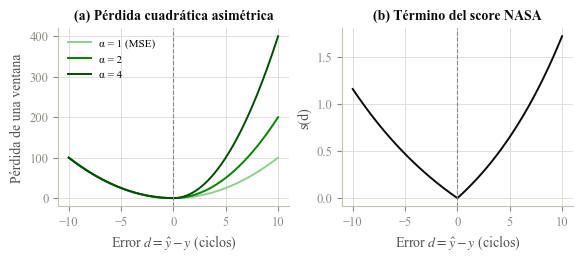

In [56]:
_d = np.linspace(-10, 10, 401)                           # error d = predicho - real, en ciclos
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.5), layout="constrained")
for al in ALPHAS:                                        # mismos colores que la figura 2.4
    w = np.where(_d > 0, al, 1.0)                        # peso alfa al sobreestimar, 1 al subestimar
    axes[0].plot(_d, w * _d ** 2, color=ALPHA_COLORS[ALPHA_NAMES[al]], lw=1.4, label=ALPHA_NAMES[al])
axes[0].set_title("(a) Pérdida cuadrática asimétrica")
axes[0].set_ylabel("Pérdida de una ventana")
axes[0].legend(loc="upper left", fontsize=8)              # esquina sin curvas
axes[1].plot(_d, nasa_terms(_d), color=INK, lw=1.4)
axes[1].set_title("(b) Término del score NASA")
axes[1].set_ylabel("s(d)")
for ax in axes:
    ax.axvline(0, color=MUTED, lw=0.8, ls="--")
    ax.set_xlabel(r"Error $d = \hat{y} - y$ (ciclos)")
save_fig(fig, "fig_perdidas")
plt.show()

## 3.8 Conclusiones de la etapa 3

1. **Sesgo.** Cerca de la falla, la configuración final no tiene sesgo en validación, pero
   sí en prueba (+0,72, sección 2.6). El sesgo depende de la vida del motor: los de vida corta
   se sobreestiman. El sesgo global no representa la zona final, por el recorte en 62.
2. **Score NASA.** Es pequeño porque se promedia y los errores son pequeños; en la
   bibliografía se suma, así que no es comparable. Cuando no sigue al RMSE es por su
   asimetría.
3. **Atención.** En A6, casi uniforme en el interior de la ventana: funciona como un promedio
   temporal. En A4 y A5 no es uniforme, pero pesa salidas de la LSTM que ya mezclan los pasos
   anteriores. En ningún caso señala instantes con significado físico claro: la
   interpretabilidad que se esperaba de ella es limitada.
4. **Regímenes.** Las condiciones de vuelo forman un continuo dominado por la altitud; los
   agrupamientos no recuperan las fases. El error es mayor en el descenso.
5. **Factibilidad computacional.** Modelo de menos de 60 KiB, inferencia de medio
   milisegundo en CPU y entrenamiento de menos de un minuto: el cómputo no limita la
   implementación.

### Valores elegidos en esta etapa

| Valor | Dónde | Por qué |
|---|---|---|
| A4 y A5 con MSE y A6 con α = 2 en la figura de atención | Sección 3.4 | Son las tres arquitecturas con atención; A6 con la configuración final, las otras dos con la pérdida con que se compararon en la ablación |
| Pasos 3 a 28 como "interior" de la ventana | Sección 3.4 | La convolución de kernel 3 usa el relleno de ceros en los pasos 1 y 30, y la segunda convolución propaga ese efecto un paso más; se excluyen 2 pasos por lado |
| Guardar el barrido de K en `results/` y cargarlo si existe | Sección 3.5 | Es determinista (semilla 0) y es la parte más lenta de la etapa (unos 2 minutos; se había estimado en 15 a 30 minutos por v04, que incluía más configuraciones de DBSCAN); evita repetirlo en cada ejecución |
| 20 repeticiones de calentamiento, 300 mediciones con 1 ventana y 50 con 256, mediana | Sección 3.6 | El calentamiento descarta el costo de la primera llamada; la mediana no se ve afectada por interrupciones ocasionales del sistema operativo; 300 y 50 repeticiones dan una mediana estable en pocos segundos |
| Lote de 256 en la medición | Sección 3.6 | Es el tamaño de lote del entrenamiento |
| 100 s entre ventanas como referencia de tiempo real | Sección 3.6 | Las ventanas avanzan 10 pasos de 10 s (sección 0.2) |
| Eje de −10 a +10 ciclos en la figura 3.6 | Sección 3.7 | Cubre el 90 % central de los errores de la zona final y deja ver la asimetría sin que la exponencial del score domine la escala |

Lo demás viene de versiones anteriores: umbral de las fases (10 pies por paso, v03),
submuestra de 8 000 registros con semilla 0, K de 2 a 20 (v04), 15 vecinos en Spectral y
DBSCAN en el codo (v03).